In [1]:
from catboost import CatBoostClassifier
from sklearn.model_selection import GroupKFold, ParameterGrid
from sklearn.metrics import f1_score, classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis

from sklearn.covariance import MinCovDet
from scipy.linalg import svd

from scipy.stats import pearsonr, spearmanr

In [2]:
import scipy.stats as stats
from scipy.stats import shapiro, anderson

In [3]:
import catboost

**Первый вариант датасета по керну 09.2026**

In [25]:
df = pd.read_csv("Data/data_kern.csv")

**Второй вариант датасета по керну 05.10.2026**

In [4]:
df = pd.read_csv("Data/data_kern_05_10.csv")

**Третий вариант датасета по керну 28.10.2026**

In [23]:
df = pd.read_csv("Data/data_kern_28_10.csv")

**Сначала берем датасет "data_kern_05_10.csv"**

In [38]:
df = pd.read_csv("Data/data_kern_05_10.csv")

In [39]:
df.info

<bound method DataFrame.info of      Calibration Well  Sample    Depth Stratigraphy        Mg         Al  \
0          LE-FP   C3       1  2868.11           Fr  1.821148   7.515664   
1          LE-FP   C3       2  2868.30           Fr  1.266357   7.461183   
2          LE-FP   C3       3  2868.45           Fr  1.724880   7.150965   
3          LE-FP   C3       4  2868.64           Fr  1.646439   8.260792   
4          LE-FP   C3       5  2868.78           Fr  1.847176   7.757235   
...          ...  ...     ...      ...          ...       ...        ...   
3039       LE-FP   C7     362  2697.50          Tum  1.583924  10.335025   
3040       LE-FP   C7     363  2697.78          Tum  1.491458   7.860884   
3041       LE-FP   C7     364  2697.84          Tum  1.459012  11.210366   
3042       LE-FP   C7     365  2698.97          Tum  1.300348   1.489742   
3043       LE-FP   C7     366  2699.34          Tum  1.097352   9.414267   

             Si         P          S  ...  Depth.2     

In [44]:
df.describe()

,Sample,Depth,Mg,Al,Si,P,S,K,Ca,Ti,...,Depth.2,Mo/Al,Depth.3,Sr/Ca,Depth.4,Ni/Si+Ca+Mg,Depth.5,Se/Ti,Depth.6,Si\Al
count,3044.000000,3044.000000,3044.000000,3044.000000,3044.000000,3044.000000,3044.000000,3044.000000,3044.000000,3044.000000,...,3044.000000,3044.000000,3044.000000,2599.000000,3044.000000,3044.000000,3044.000000,3042.000000,3044.000000,3044.000000
mean,134.382392,2765.205111,1.652230,5.219209,24.646897,0.212532,4.525596,0.880230,5.574717,0.235596,...,2765.238226,0.001927,2765.238226,0.055267,2765.238226,0.000534,2765.238226,0.007035,2765.238226,7.504092
std,103.394965,76.104401,2.014461,3.006002,9.189635,1.072377,3.930274,0.702478,8.767929,0.167842,...,76.073951,0.003012,76.073951,0.428864,76.073951,0.001569,76.073951,0.019213,76.073951,14.257585
min,1.000000,2643.280000,0.000000,0.013244,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,2643.280000,0.000000,2643.280000,0.000000,2643.280000,-0.000004,2643.280000,0.000000,2643.280000,0.000000
25%,59.000000,2714.155000,0.624416,2.970877,19.248832,0.000000,1.734324,0.292311,0.163731,0.146356,...,2714.155000,0.000171,2714.155000,0.003174,2714.155000,0.000114,2714.155000,0.000973,2714.155000,2.878219
50%,114.000000,2744.245000,1.099680,4.842561,25.880274,0.001000,3.301751,0.760405,0.951696,0.210898,...,2744.245000,0.001129,2744.245000,0.010833,2744.245000,0.000287,2744.245000,0.003532,2744.245000,4.826373
75%,175.000000,2813.930000,1.794564,7.052667,31.662610,0.048013,6.248604,1.333626,7.788837,0.305586,...,2813.930000,0.002684,2813.930000,0.038439,2813.930000,0.000587,2813.930000,0.008008,2813.930000,7.817072
max,500.000000,2968.270000,18.477263,15.490503,42.677071,11.844915,31.978827,3.364525,41.428715,6.406212,...,2968.270000,0.071664,2968.270000,17.144531,2968.270000,0.056817,2968.270000,0.756733,2968.270000,494.098348


**Отобранные элементы с доставерными определениями**

In [45]:
elements = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

In [46]:
cols_to_keep = elements + ['Well', 'Sample', 'Depth', 'Stratigraphy']
df_filtered = df[cols_to_keep].query("Stratigraphy != 'Tum'").copy()

**Замена пачек на цифровые коды**

In [47]:
def to_str_key(val):
    try:
        return str(int(val))
    except (ValueError, TypeError):
        return str(val).strip()

df_filtered['Strat'] = df_filtered['Stratigraphy'].apply(to_str_key)

In [48]:
formation_map = {
    'Abl': 0,
    'A0': 1,
    '1': 2,
    '2a': 3,
    '2b': 4,
    '3': 5,
    '4a': 6,
    '4b': 7,
    '5a': 8,
    '5b': 9,
    '6': 10,
    'Fr': 11
}

df_filtered['Strat'] = df_filtered['Strat'].map(formation_map)

**Подсчет нулей по всем признакам**

In [49]:
# Подсчёт нулей и процентов по каждому элементу
zero_counts = df_filtered[elements].isnull().sum() + (df_filtered[elements] == 0).sum()
total = len(df_filtered)

zero_table = pd.DataFrame({
    'Элемент': zero_counts.index,
    'Нулей': zero_counts.values,
    'Доля нулей, %': (zero_counts.values / total * 100).round(2)
}).sort_values('Доля нулей, %', ascending=False).reset_index(drop=True)

print("Таблица нулевых значений по элементам:")
print(zero_table.to_string(index=False))

# Общее количество
total_zeros = zero_counts.sum()
total_values = total * len(elements)
print(f"\nОбщее количество нулевых значений: {total_zeros}")
print(f"Процент нулевых значений (все элементы): {total_zeros / total_values * 100:.2f}%")

Таблица нулевых значений по элементам:
Элемент  Нулей  Доля нулей, %
      P   1321          43.64
     Mo    591          19.52
     Mn    449          14.83
     Ca    440          14.54
     Cu    348          11.50
     Se    346          11.43
     Mg    344          11.36
     Rb    257           8.49
     Ni    215           7.10
     Fe    183           6.05
      K    141           4.66
     Sr     93           3.07
     Zr     26           0.86
     Zn     23           0.76
      S      5           0.17
     Si      3           0.10
     Ti      2           0.07
     Al      0           0.00

Общее количество нулевых значений: 4787
Процент нулевых значений (все элементы): 8.79%


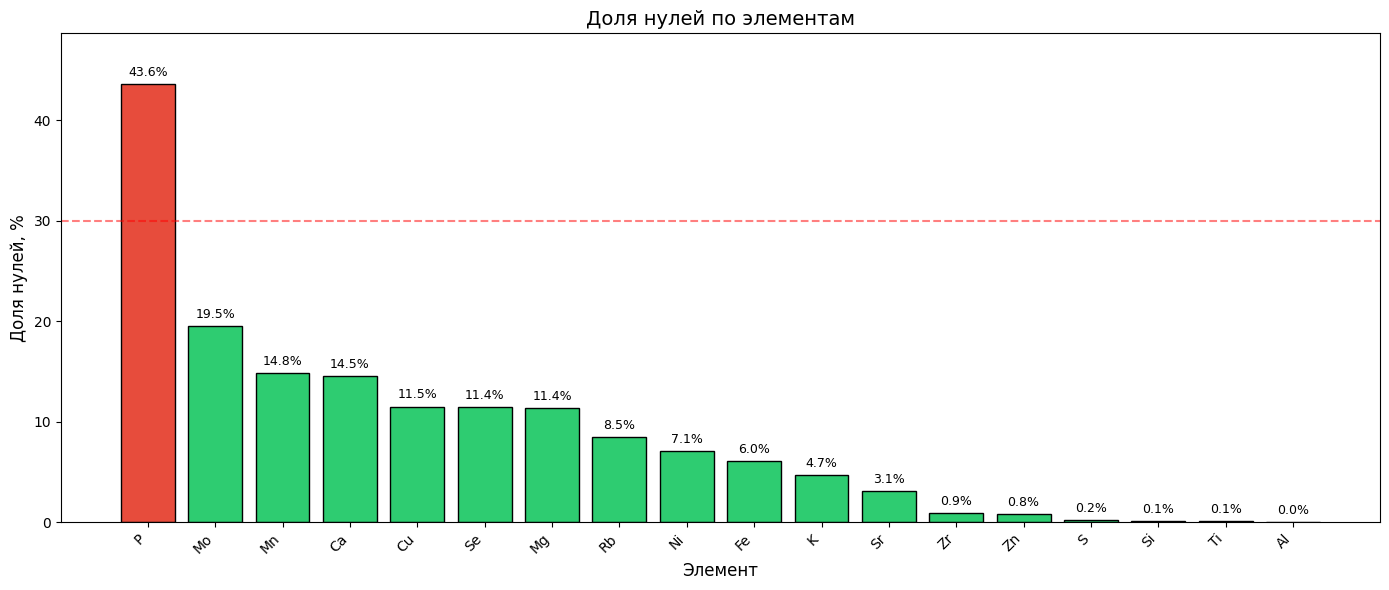

In [50]:
# График: доля нулей по элементам
fig, ax = plt.subplots(figsize=(14, 6))

# Цвета по группам 
def get_color(pct):
    if pct < 30:
        return '#2ecc71'  
    else:
        return '#e74c3c'  

colors = [get_color(p) for p in zero_table['Доля нулей, %']]

bars = ax.bar(zero_table['Элемент'], zero_table['Доля нулей, %'], color=colors, edgecolor='black')

# Подписи значений над столбцами
for bar, pct in zip(bars, zero_table['Доля нулей, %']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{pct:.1f}%', ha='center', va='bottom', fontsize=9)

# Пороговые линии
ax.axhline(y=30, color='red', linestyle='--', alpha=0.5)

ax.set_xlabel('Элемент', fontsize=12)
ax.set_ylabel('Доля нулей, %', fontsize=12)
ax.set_title('Доля нулей по элементам', fontsize=14)

ax.set_ylim(0, max(zero_table['Доля нулей, %']) + 5)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Проверка распределения**

Mg: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Al: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Si: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
P: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
S: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
K: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Ca: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Ti: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Mn: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Fe: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Ni: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Cu: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Zn: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Se: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Rb: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Sr: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Zr: Shapiro p (сырые) = 0.0000, p (log) = 0.0000
Mo: Shapiro p (сырые) = 0.0000, p (log) = 0.0000


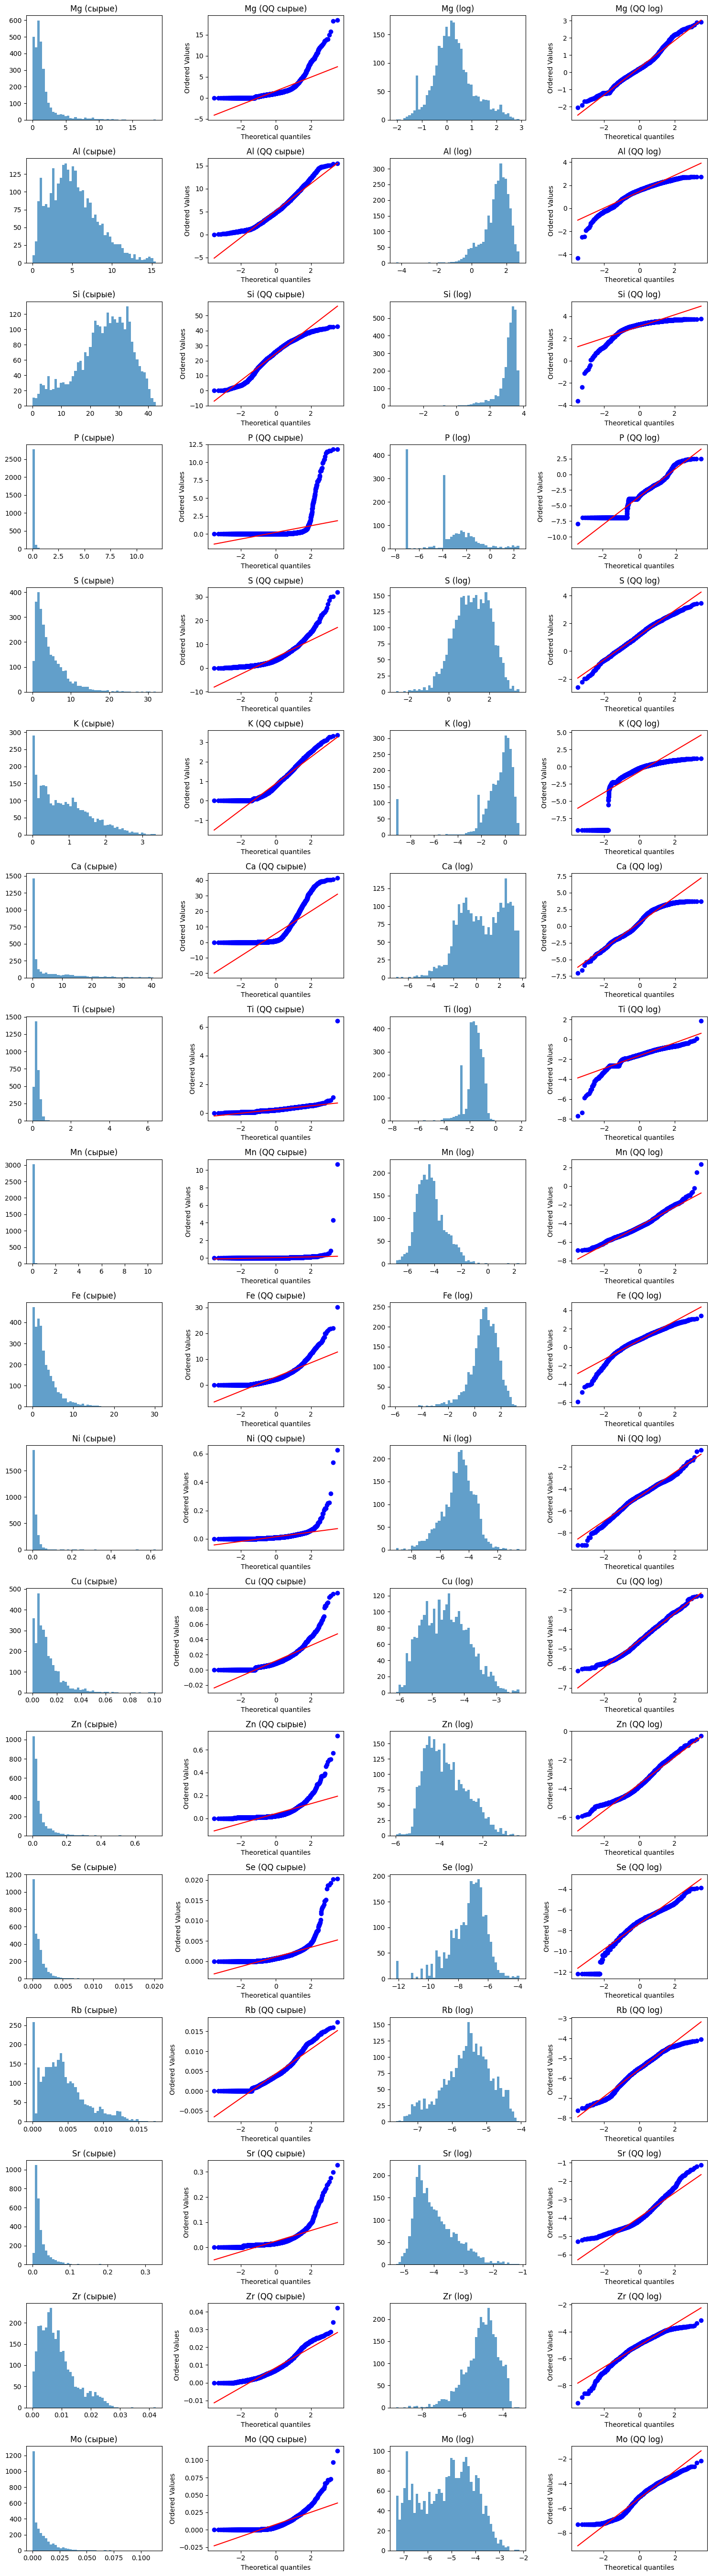

Элемент  N (ненулевых)  Skew (сырые)  Skew (log)  Kurt (сырые)  Kurt (log) Skew(log) < 0.5?
     Mn           2595         41.24        0.63       1844.10        1.03              нет
     Ti           3042         16.70       -1.63        600.05        7.26              нет
     Ni           2814         10.79       -0.43        196.56        0.61               да
      P           1720          5.60        0.07         33.40       -0.50               да
     Se           2682          5.56       -1.01         46.70        1.91              нет
     Sr           2950          4.32        0.98         26.83        0.76              нет
     Zn           3020          3.89        0.55         23.64       -0.31              нет
     Mg           2697          3.17        0.43         12.52        0.36               да
     Cu           2684          2.56        0.30         10.43       -0.46               да
     Mo           2438          2.46       -0.13         10.37       -0.99      

In [51]:
fig, axes = plt.subplots(len(elements), 4, figsize=(15, 3*len(elements)))
results = []
for i, col in enumerate(elements):
    x_raw = df[col].dropna()
    x_nonzero = x_raw[x_raw > 0]
    x_log = np.log(x_nonzero)

    results.append({
        'Элемент': col,
        'N (ненулевых)': len(x_nonzero),
        'Skew (сырые)': round(skew(x_nonzero), 2),
        'Skew (log)': round(skew(x_log), 2),
        'Kurt (сырые)': round(kurtosis(x_nonzero), 2),
        'Kurt (log)': round(kurtosis(x_log), 2),
        'Skew(log) < 0.5?': 'да' if abs(skew(x_log)) < 0.5 else 'нет',
    })
    
    # Гистограмма сырых
    axes[i, 0].hist(x_raw, bins=50, alpha=0.7)
    axes[i, 0].set_title(f'{col} (сырые)')
    
    # QQ-plot сырых
    stats.probplot(x_raw, dist="norm", plot=axes[i, 1])
    axes[i, 1].set_title(f'{col} (QQ сырые)')

    # Гистограмма логарифмированных значений
    axes[i, 2].hist(x_log, bins=50, alpha=0.7)
    axes[i, 2].set_title(f'{col} (log)')
    
    # QQ-plot логарифмов
    stats.probplot(x_log, dist="norm", plot=axes[i, 3])
    axes[i, 3].set_title(f'{col} (QQ log)')
    
    # Тесты
    sw_raw = shapiro(x_raw.sample(min(5000, len(x_raw))))[1]
    sw_log = shapiro(x_log.sample(min(5000, len(x_log))))[1]
    print(f"{col}: Shapiro p (сырые) = {sw_raw:.4f}, p (log) = {sw_log:.4f}")

plt.tight_layout()

plt.savefig('plot_element_kern_05_10.png', dpi=600, bbox_inches='tight')
plt.show()

results_df = pd.DataFrame(results).sort_values('Skew (сырые)', ascending=False)
print(results_df.to_string(index=False))

**Нахождение артефактов LOD и их зануление**


ЭЛЕМЕНТ: Mg
Всего скважин: 14
Скважин с минимумом > 0: 5


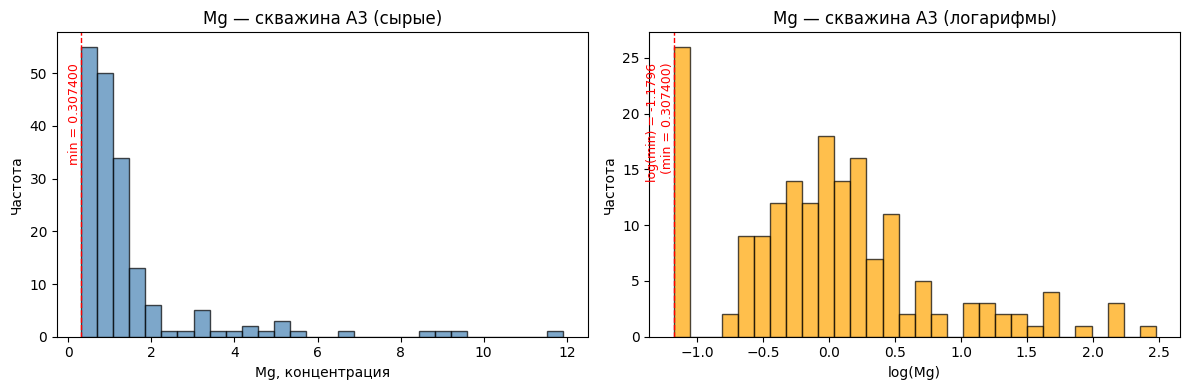

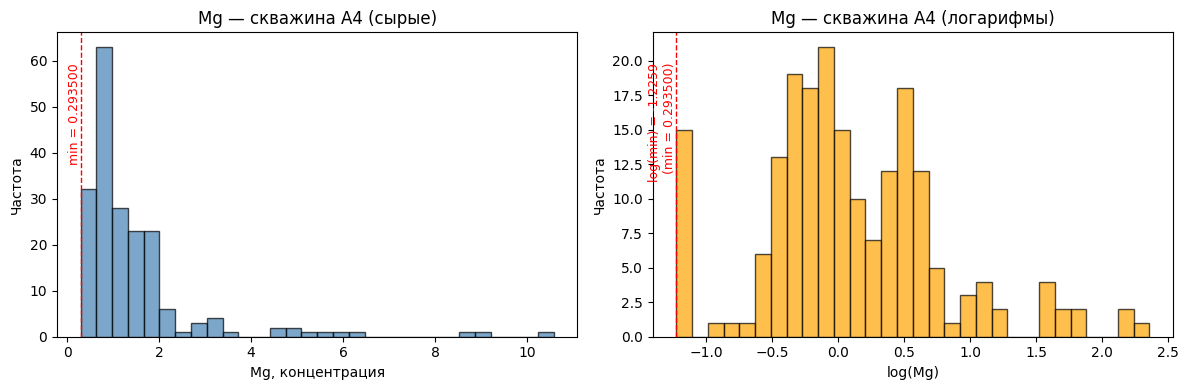

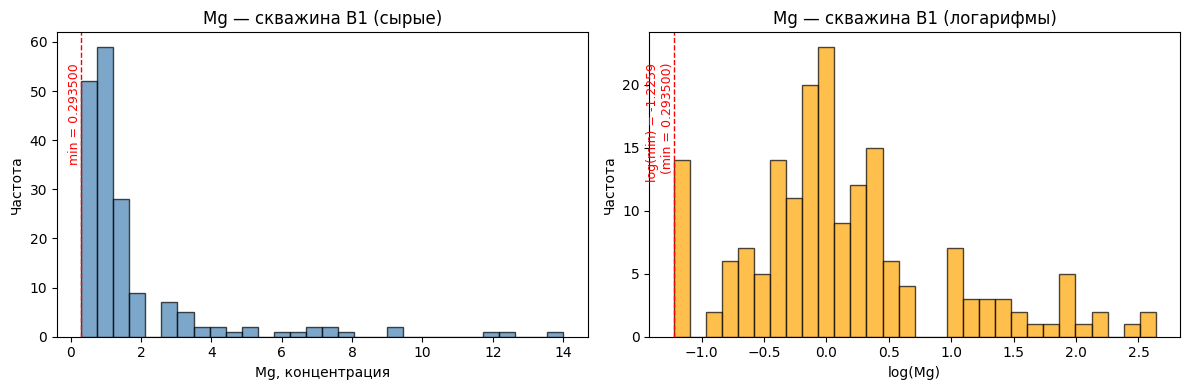

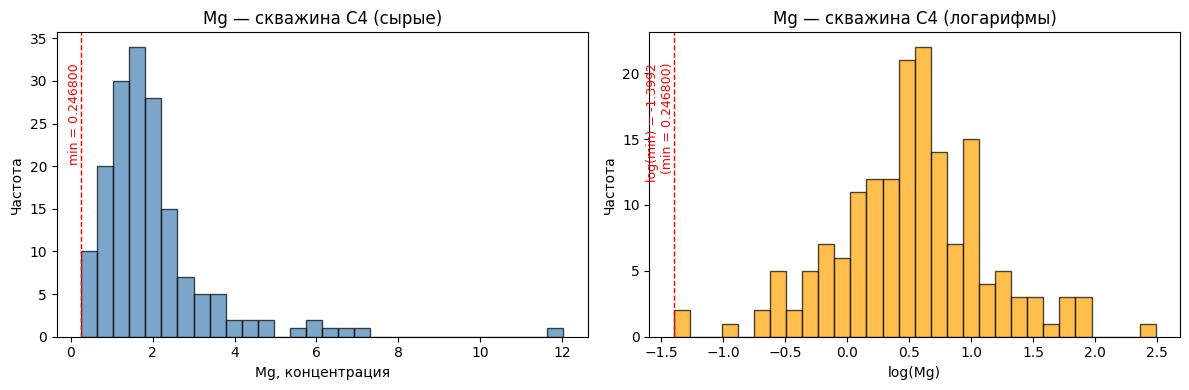

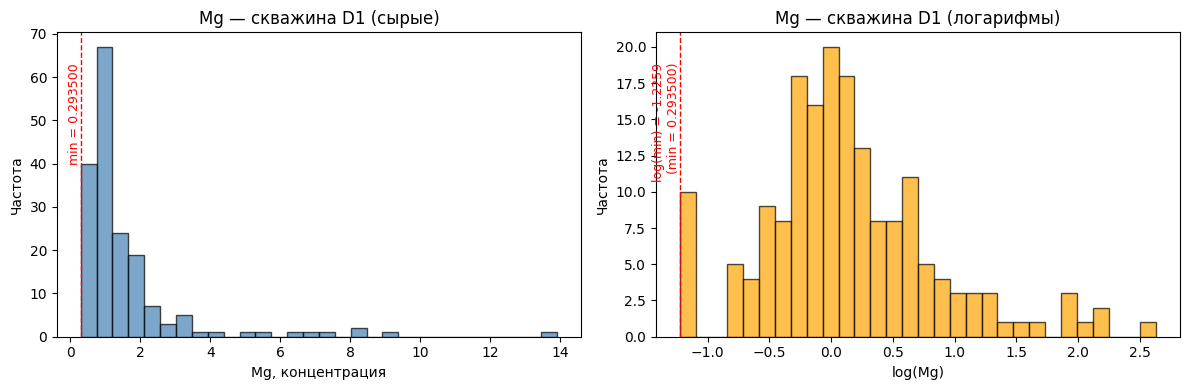


ЭЛЕМЕНТ: Al
Всего скважин: 14
Скважин с минимумом > 0: 14


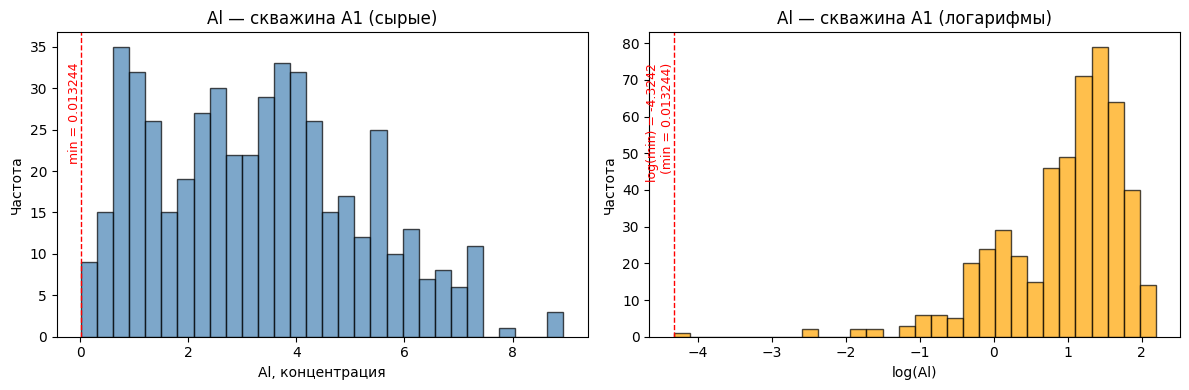

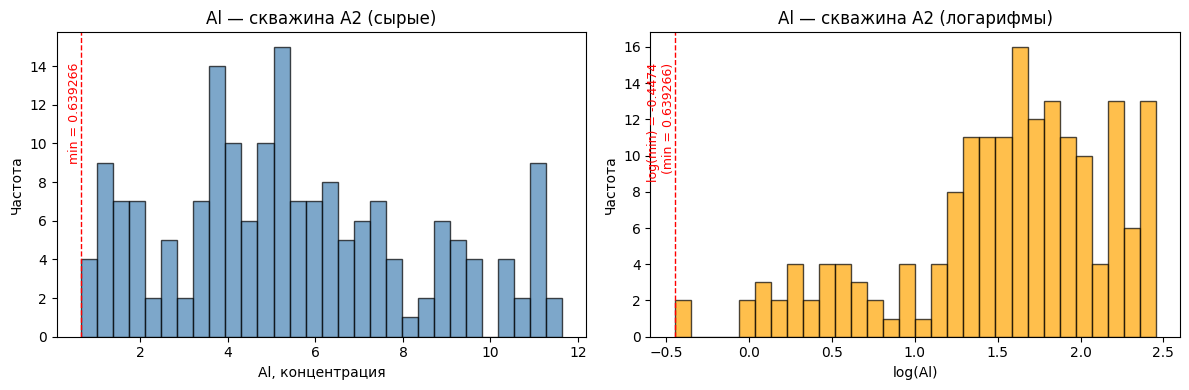

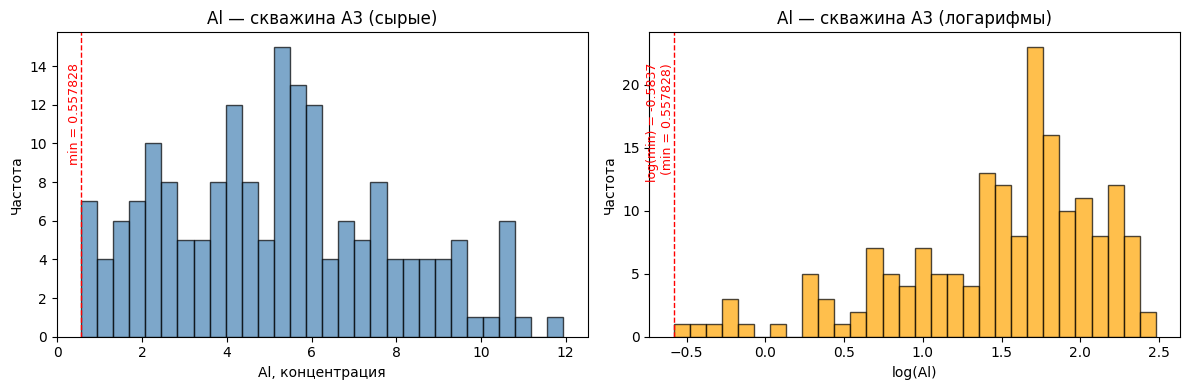

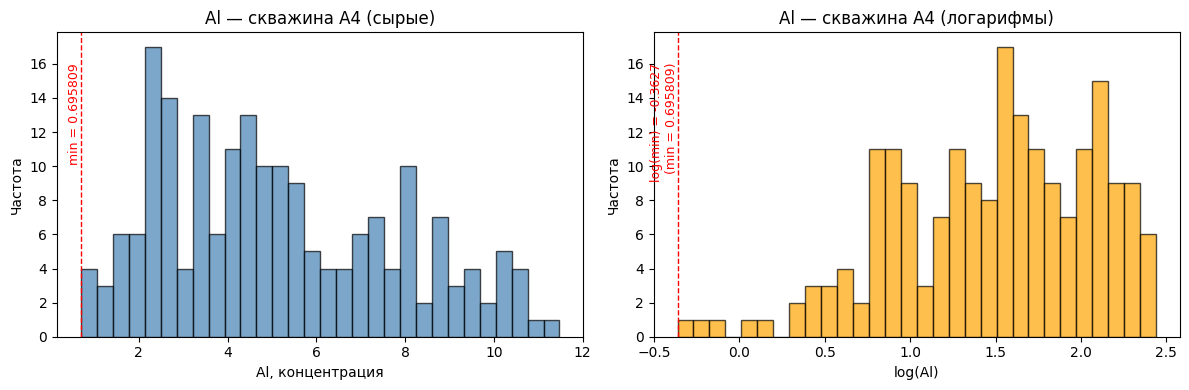

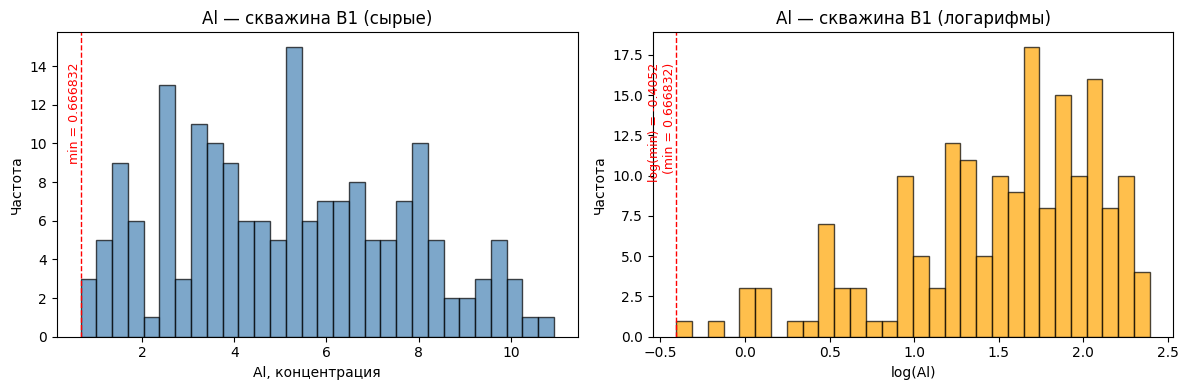

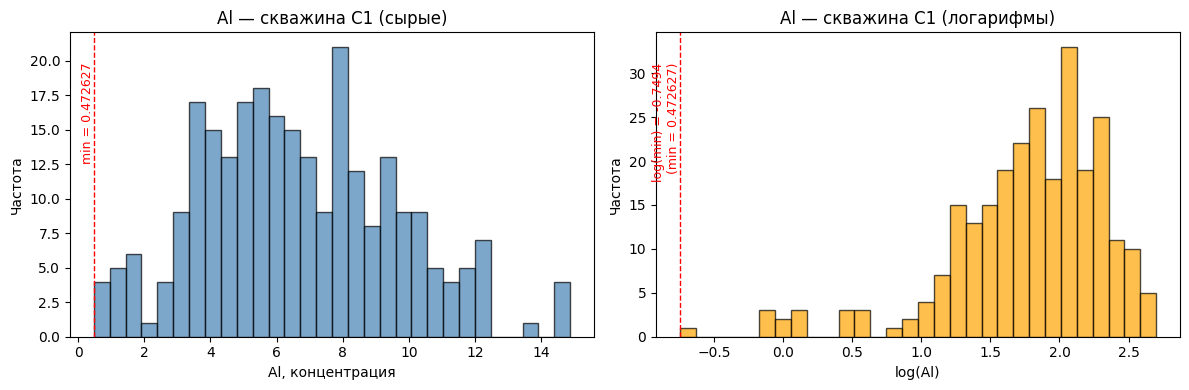

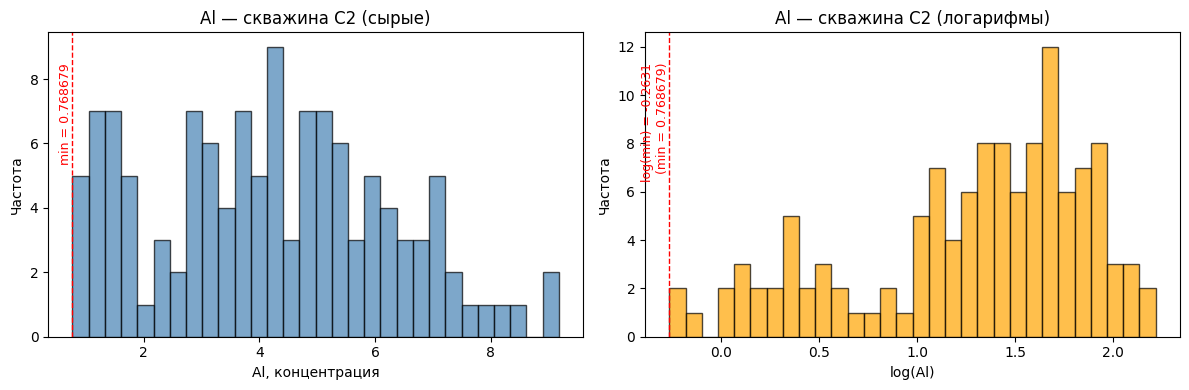

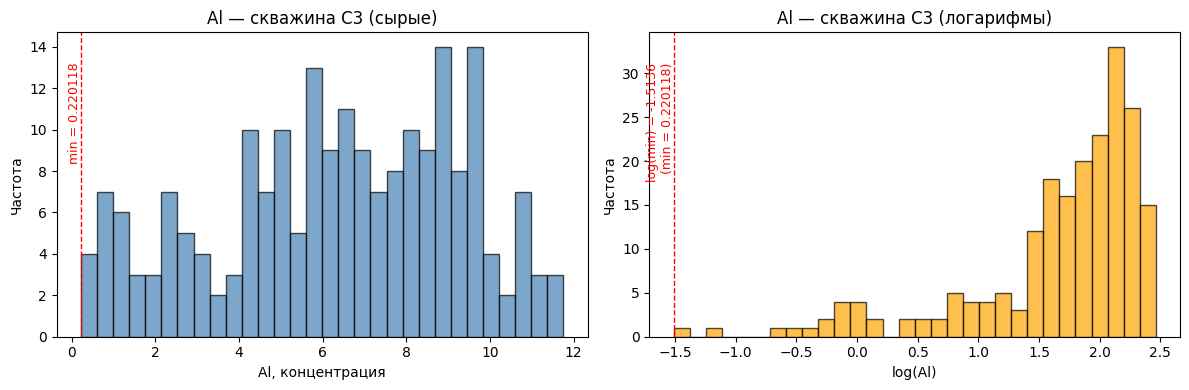

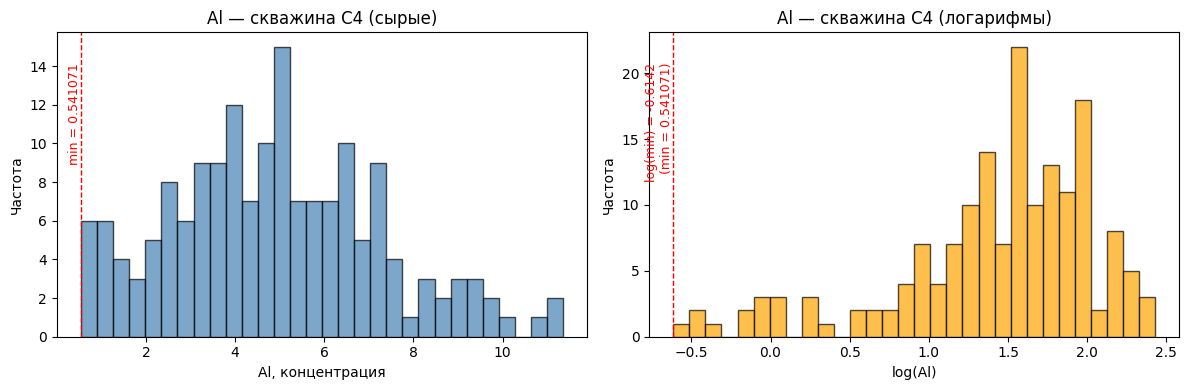

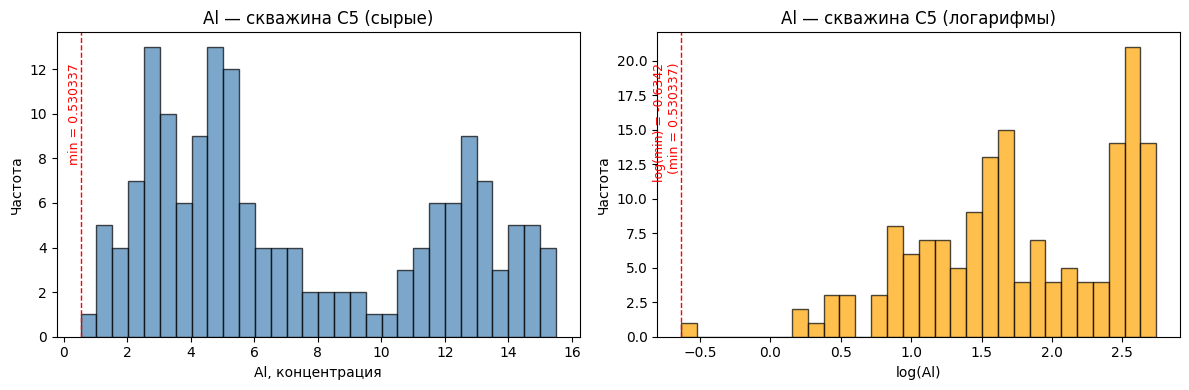

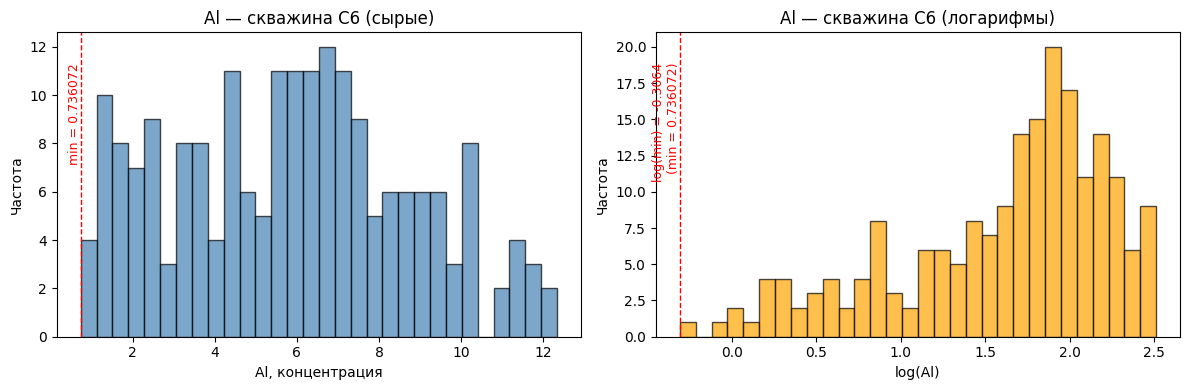

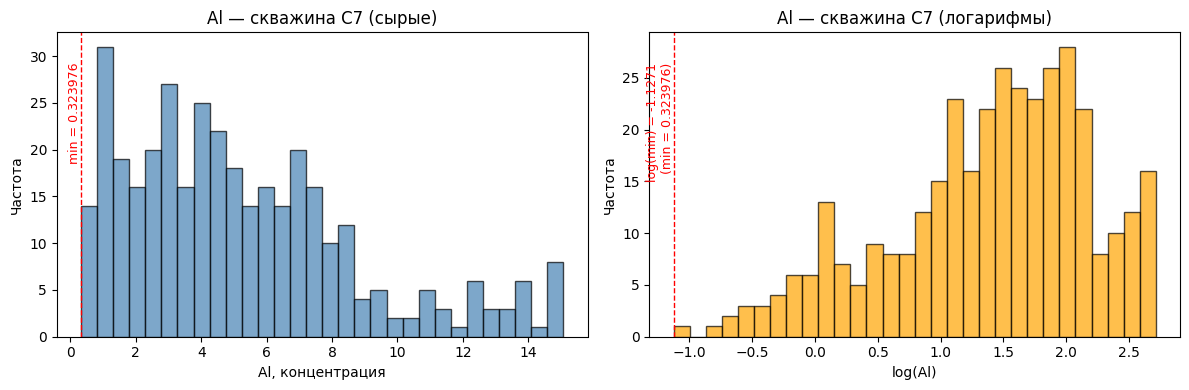

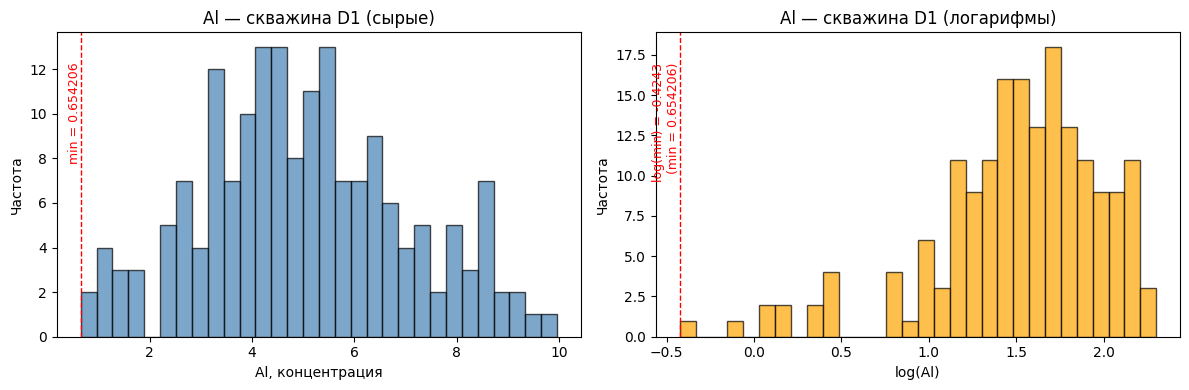

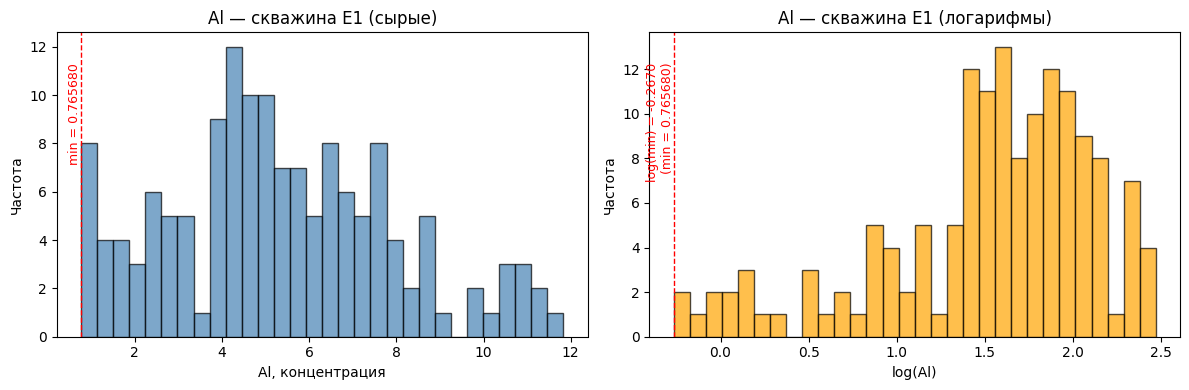


ЭЛЕМЕНТ: Si
Всего скважин: 14
Скважин с минимумом > 0: 12


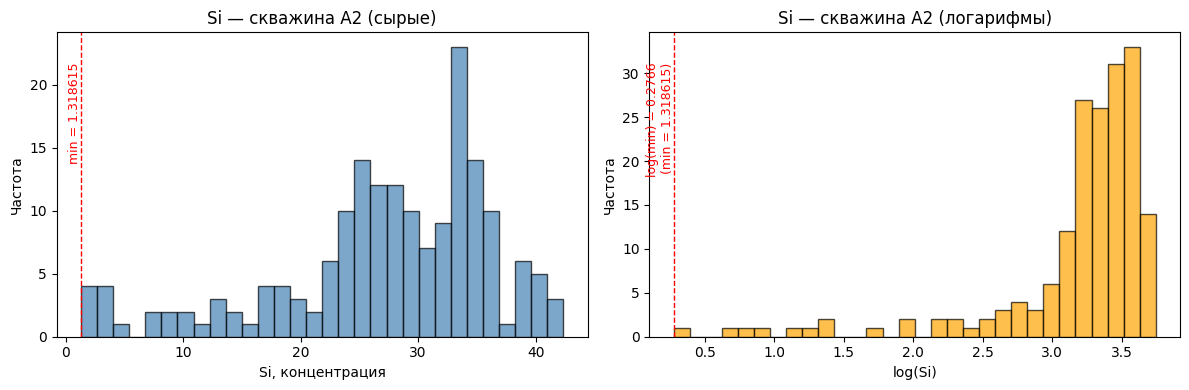

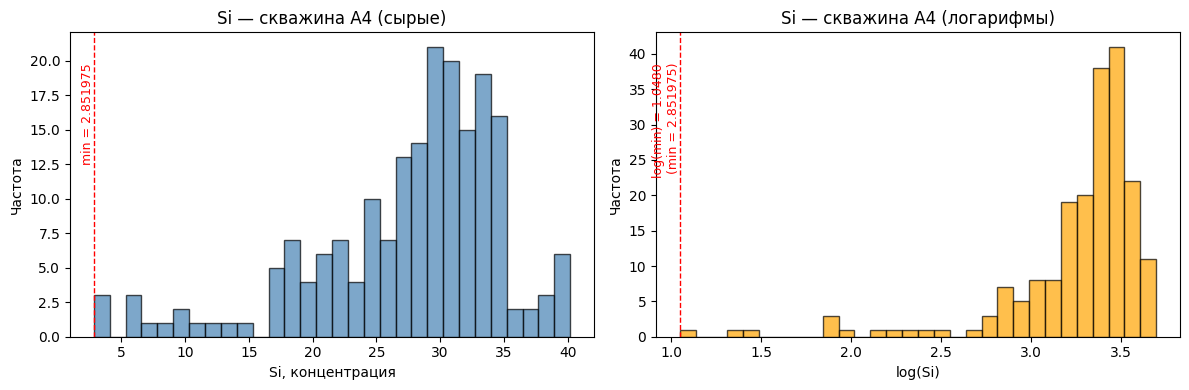

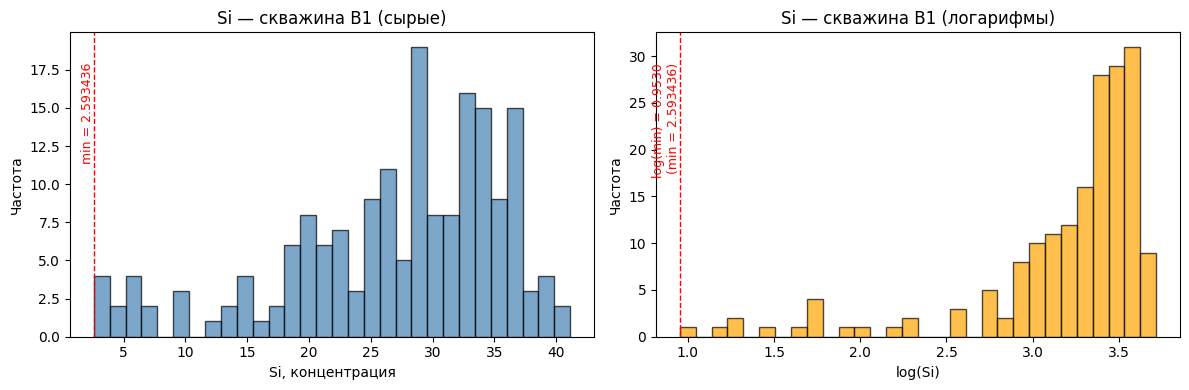

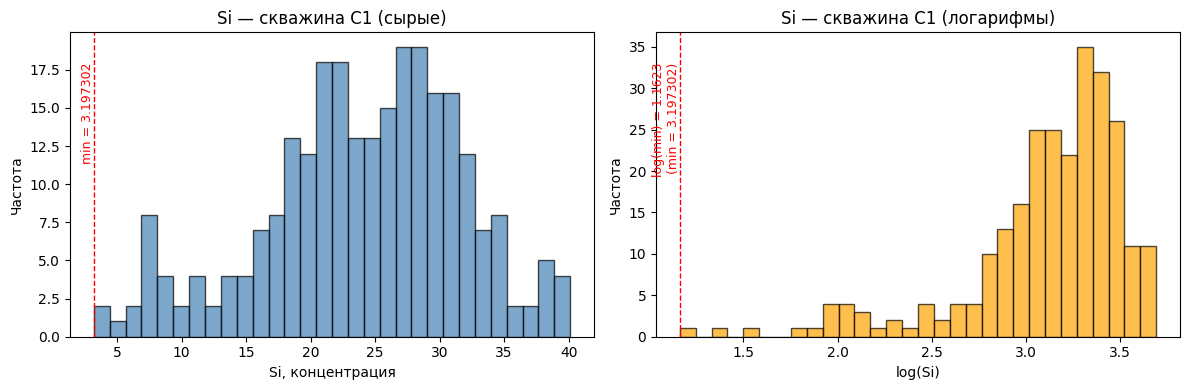

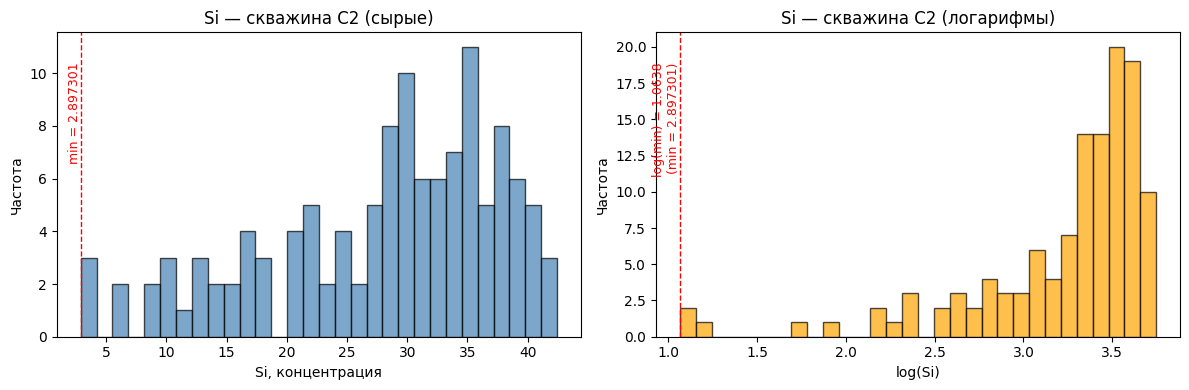

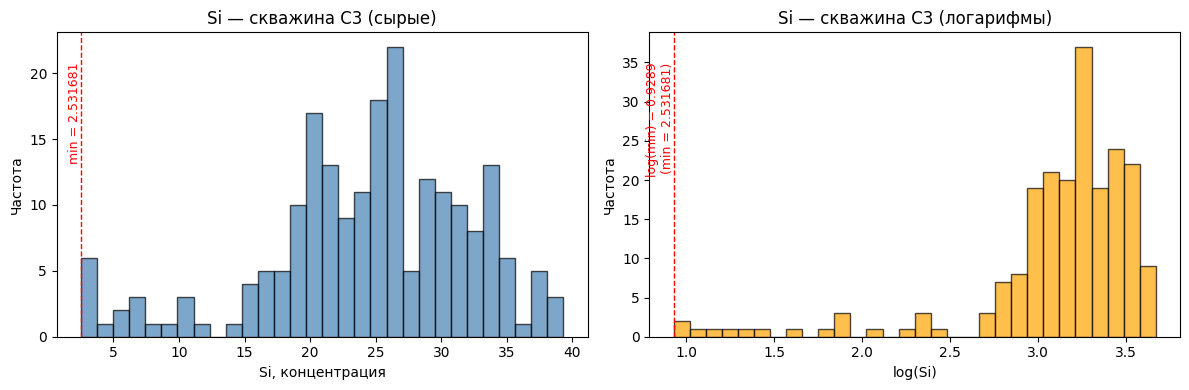

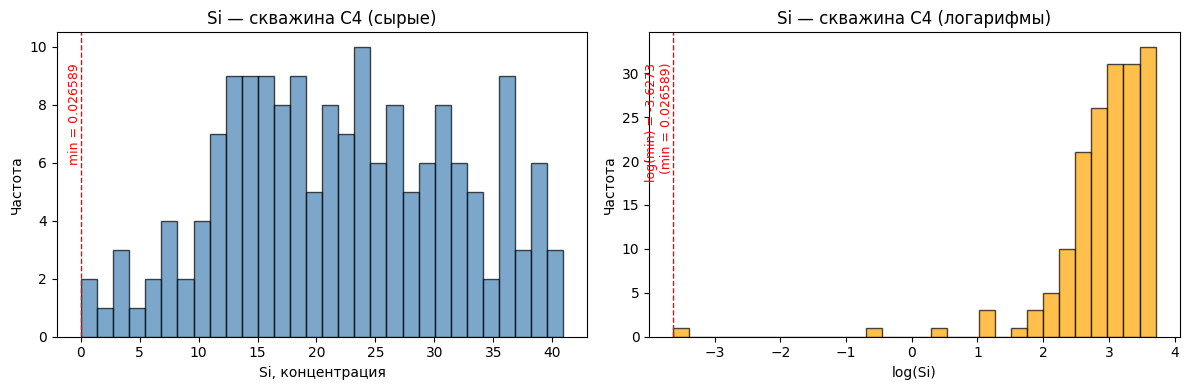

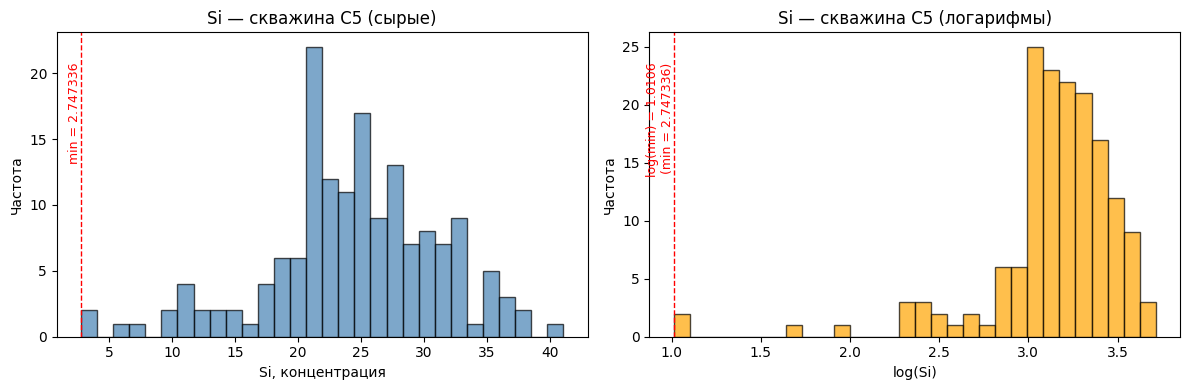

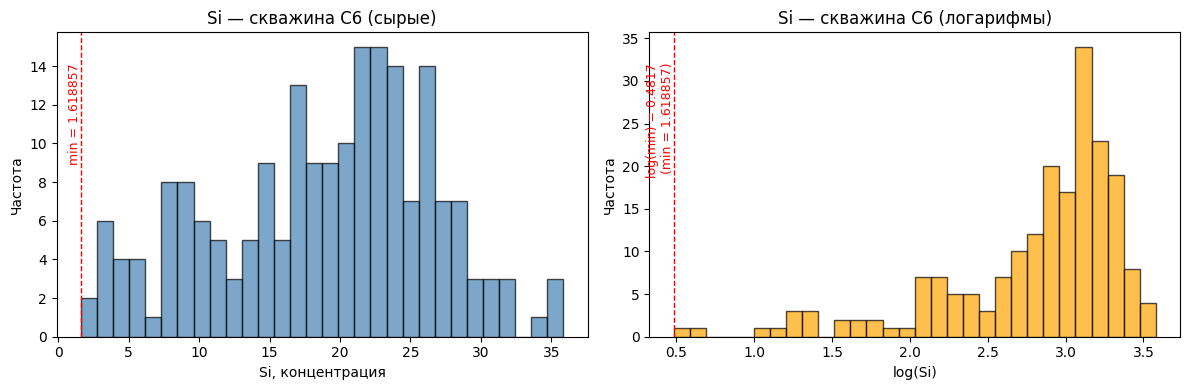

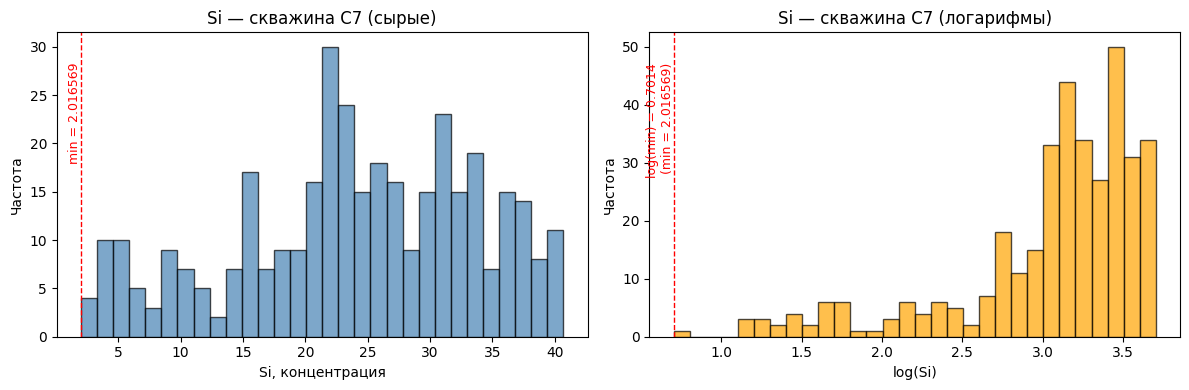

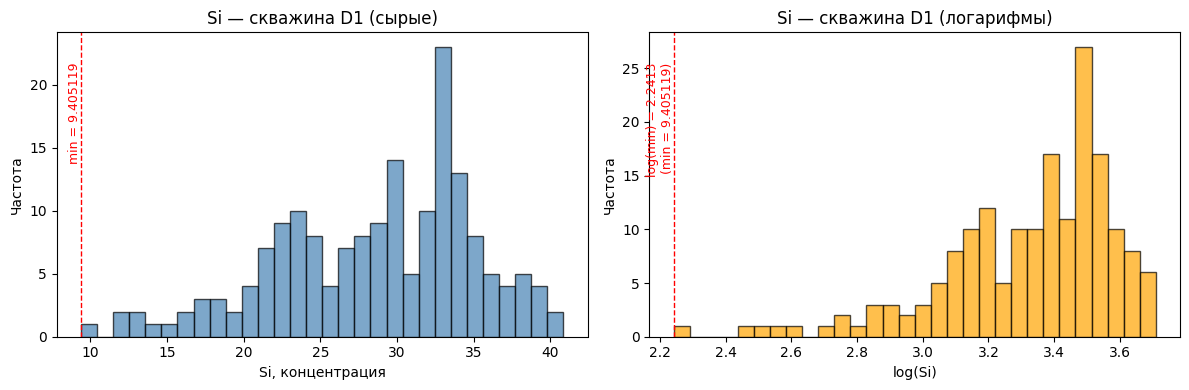

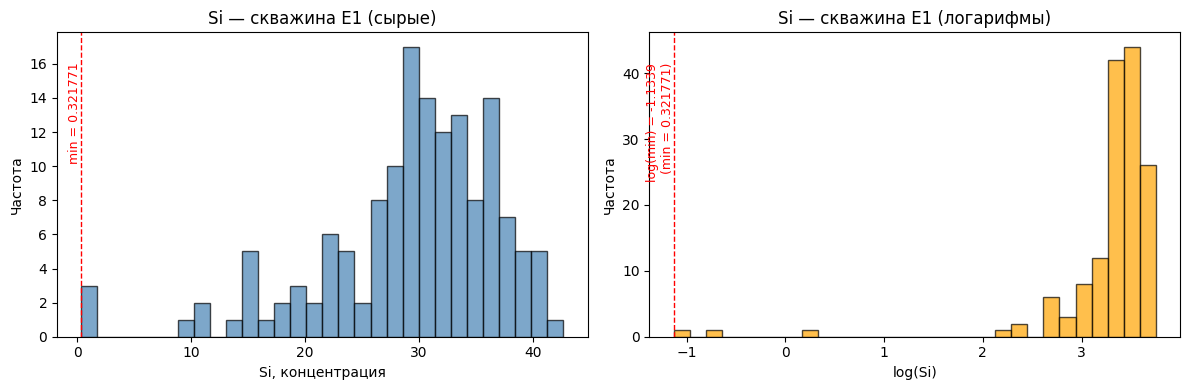


ЭЛЕМЕНТ: P
Всего скважин: 14
Скважин с минимумом > 0: 4


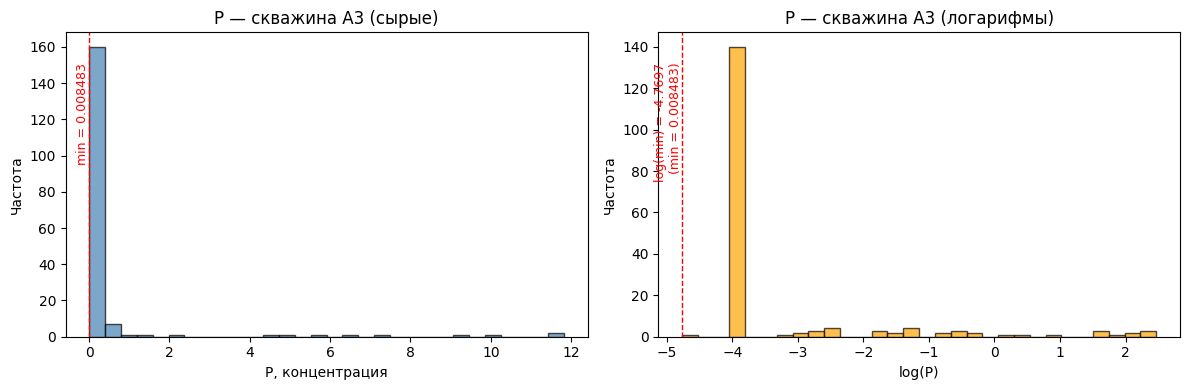

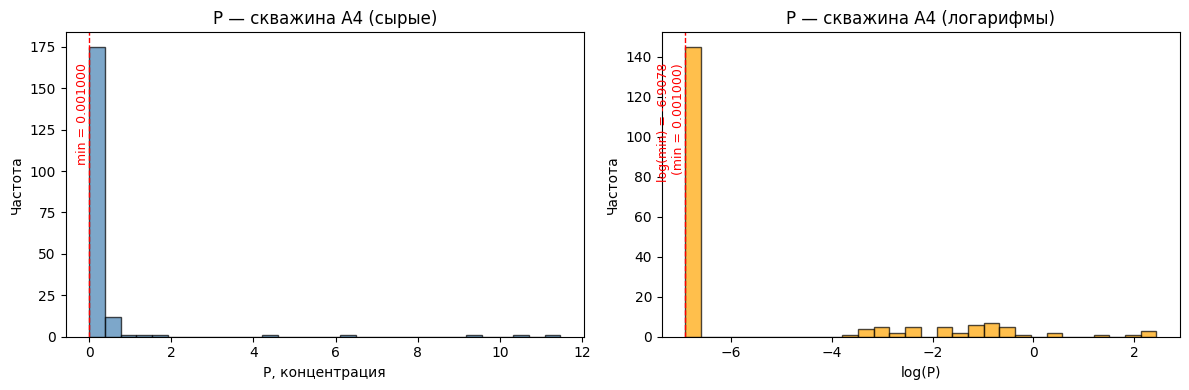

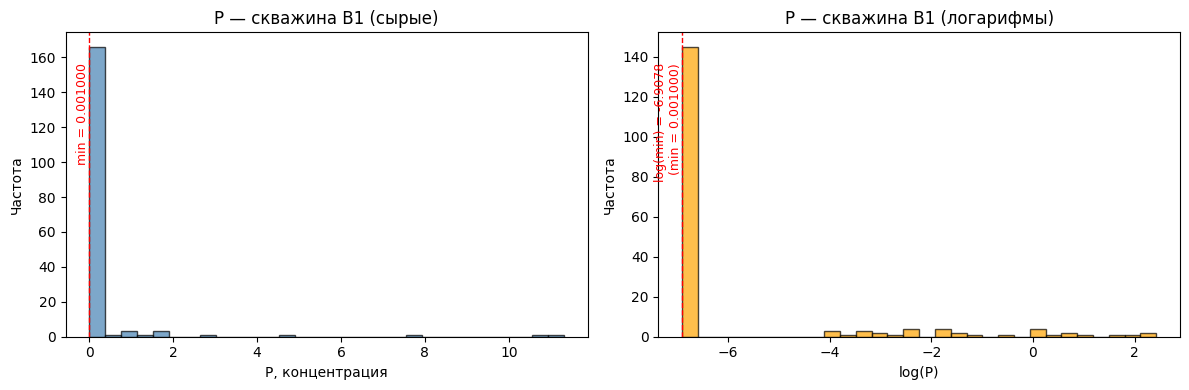

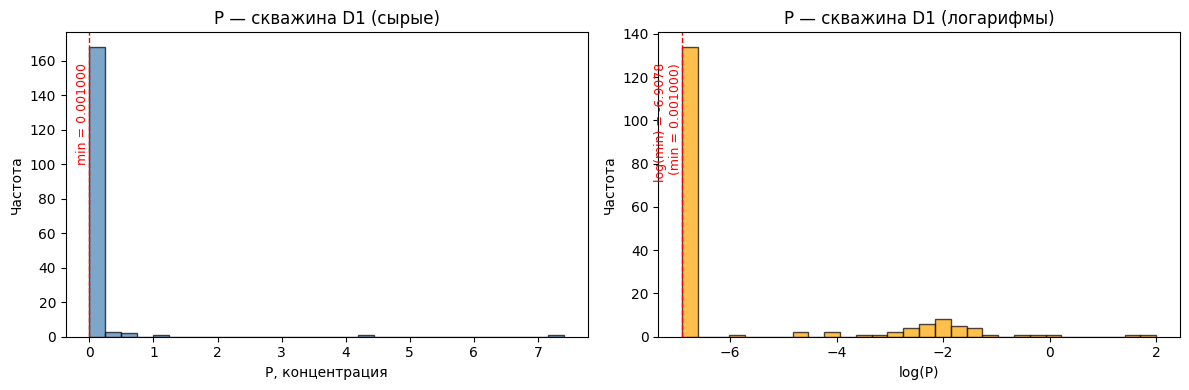


ЭЛЕМЕНТ: S
Всего скважин: 14
Скважин с минимумом > 0: 10


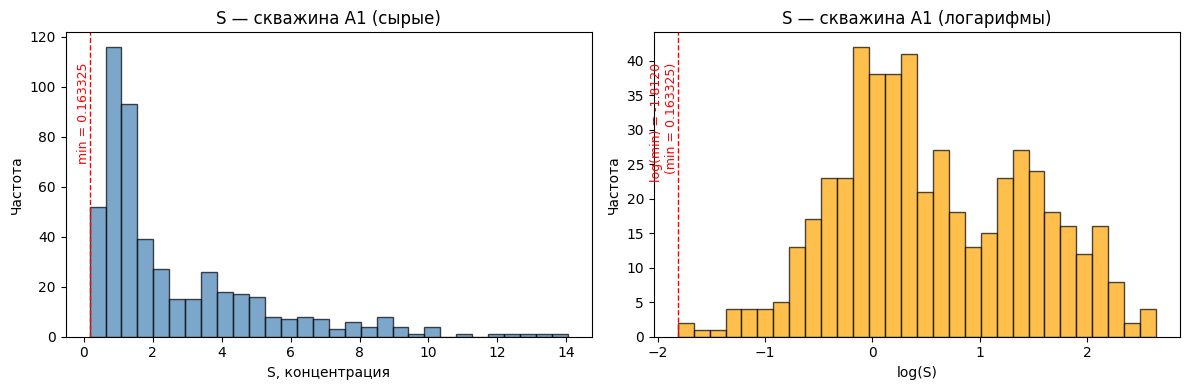

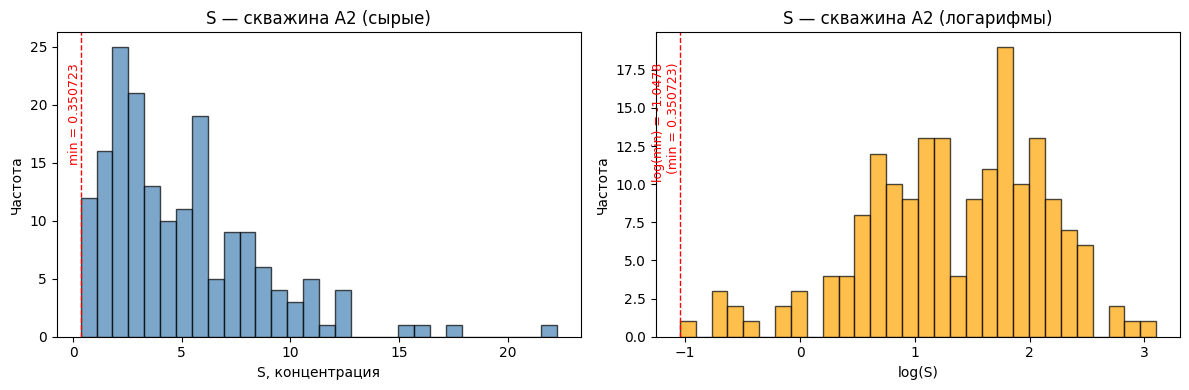

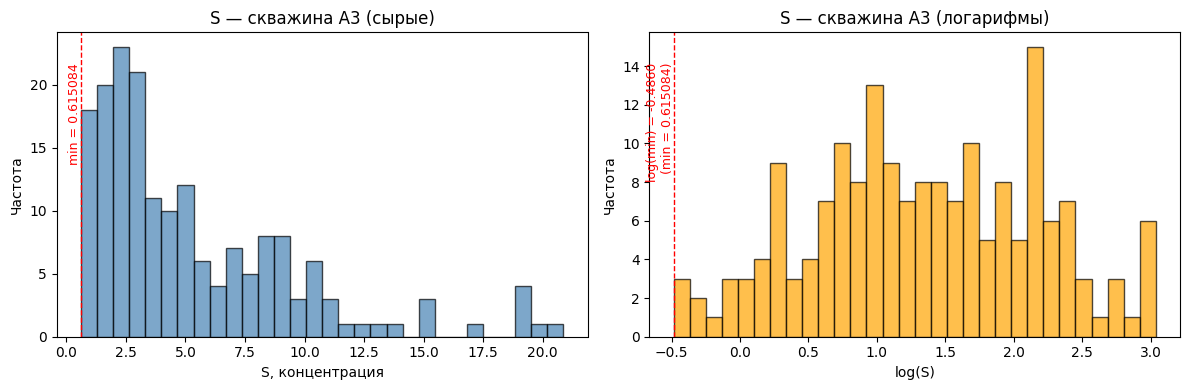

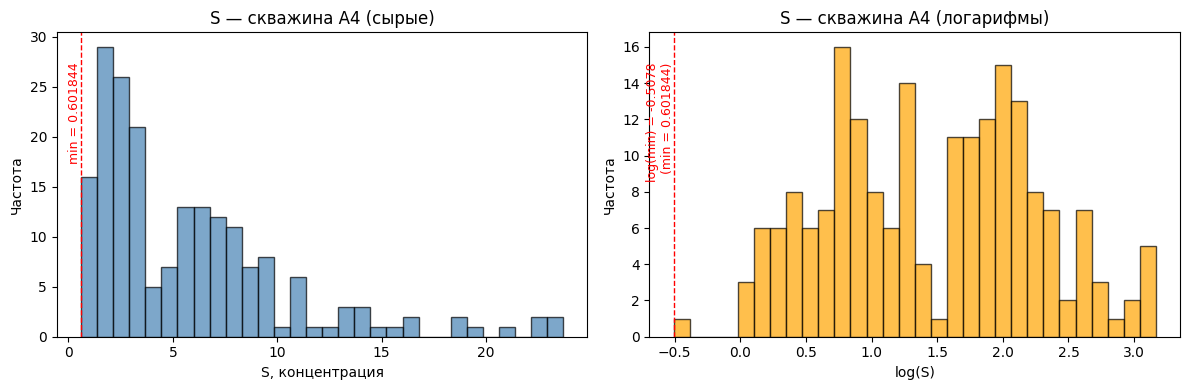

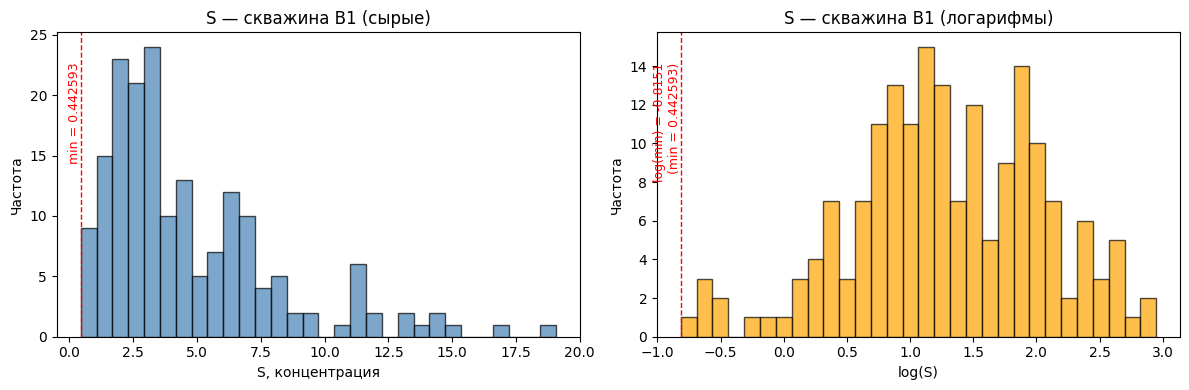

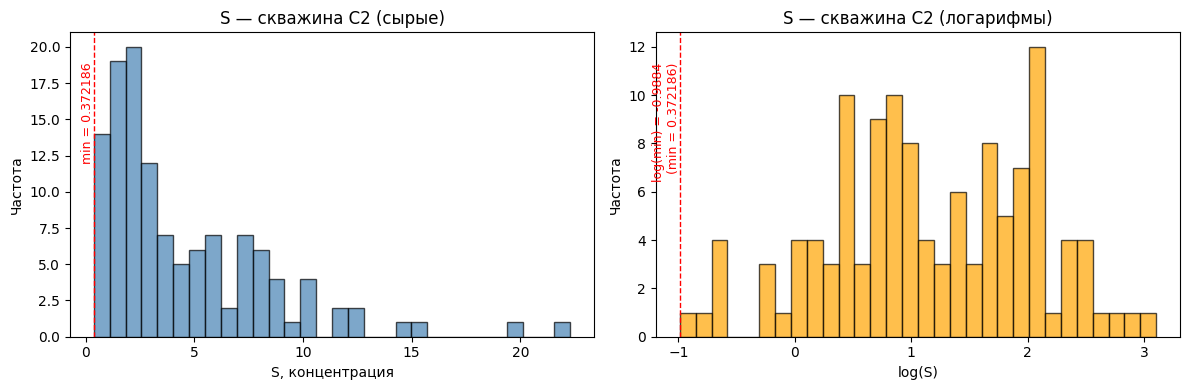

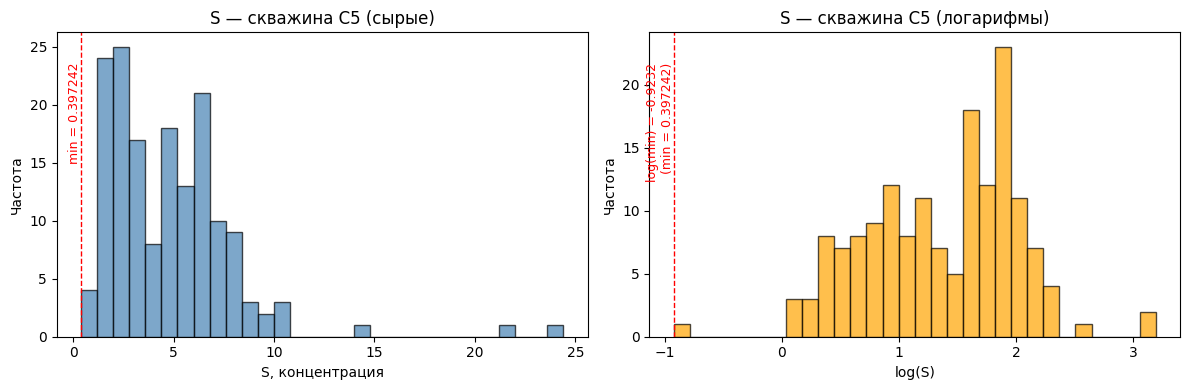

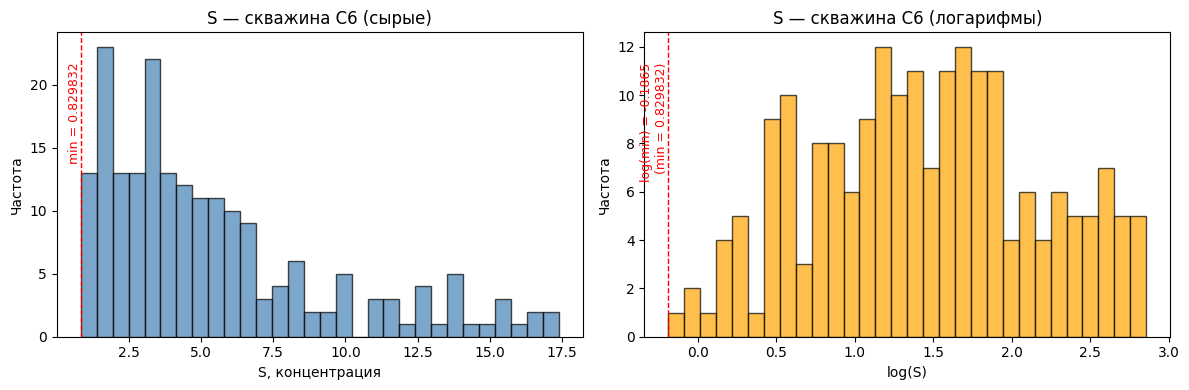

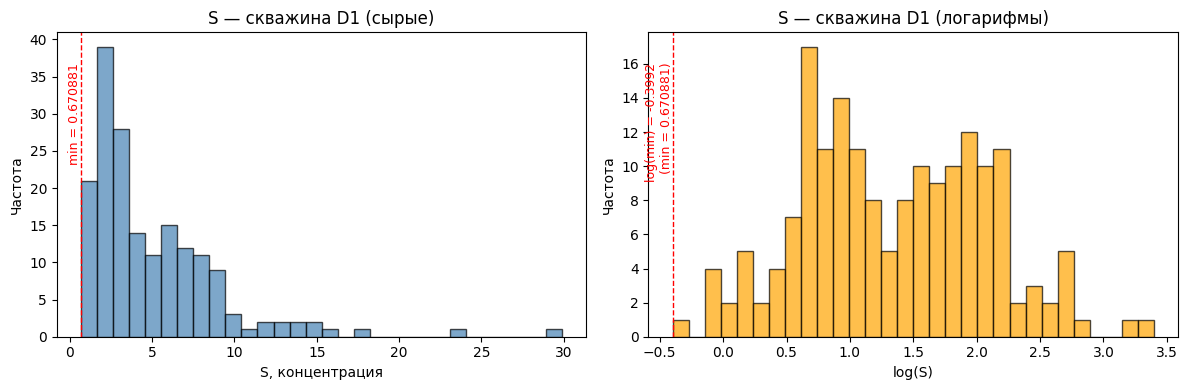

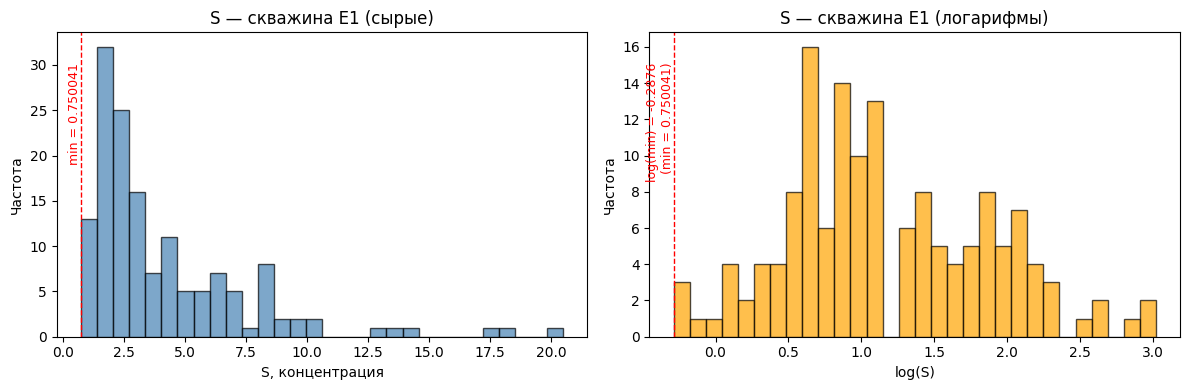


ЭЛЕМЕНТ: K
Всего скважин: 14
Скважин с минимумом > 0: 6


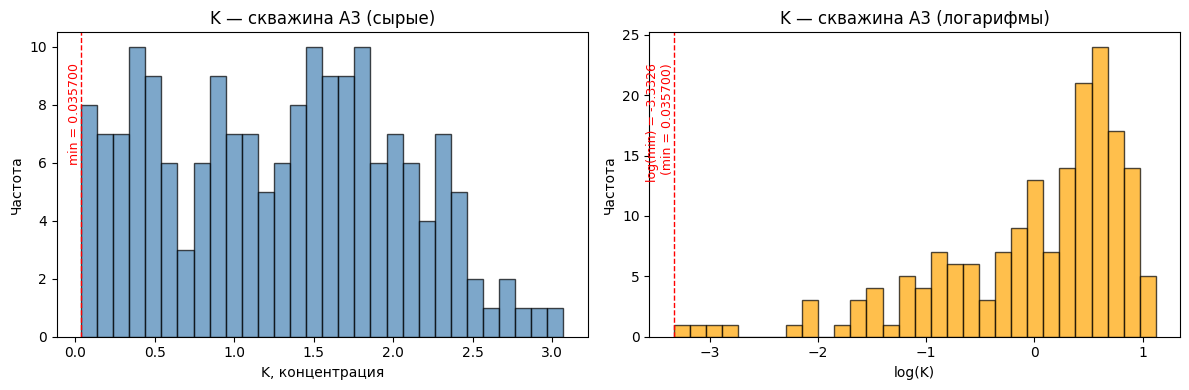

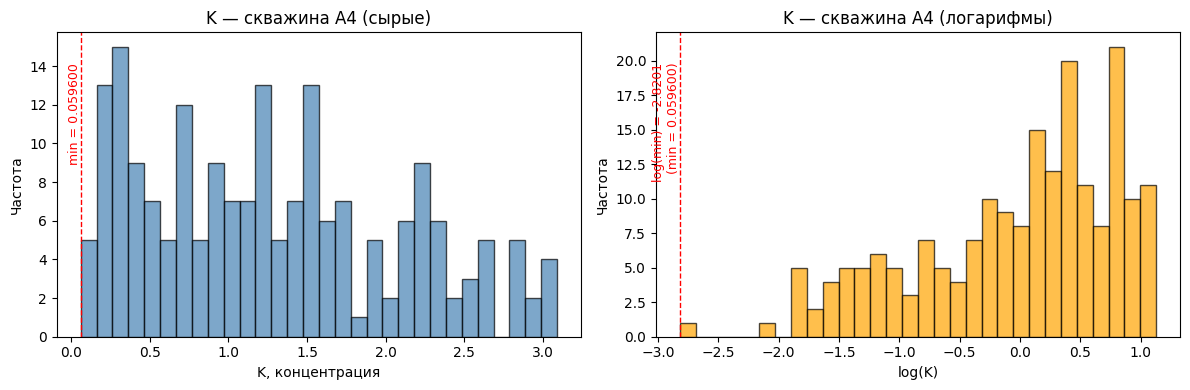

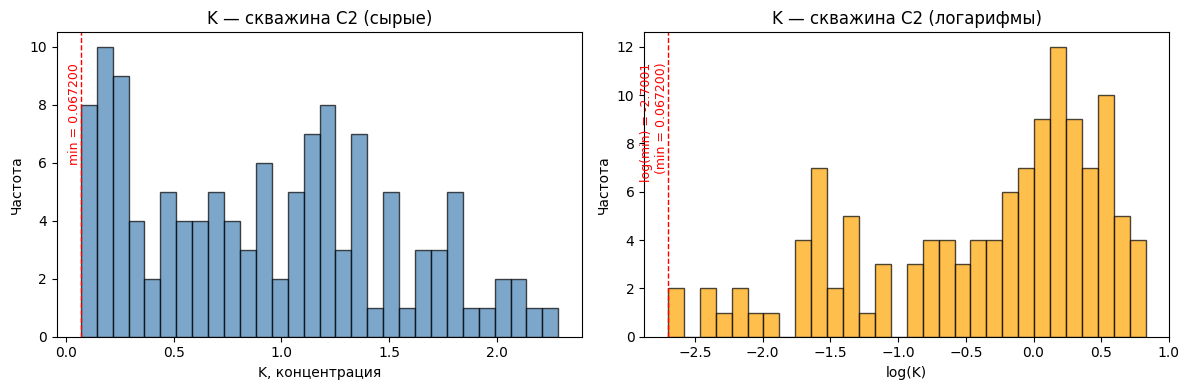

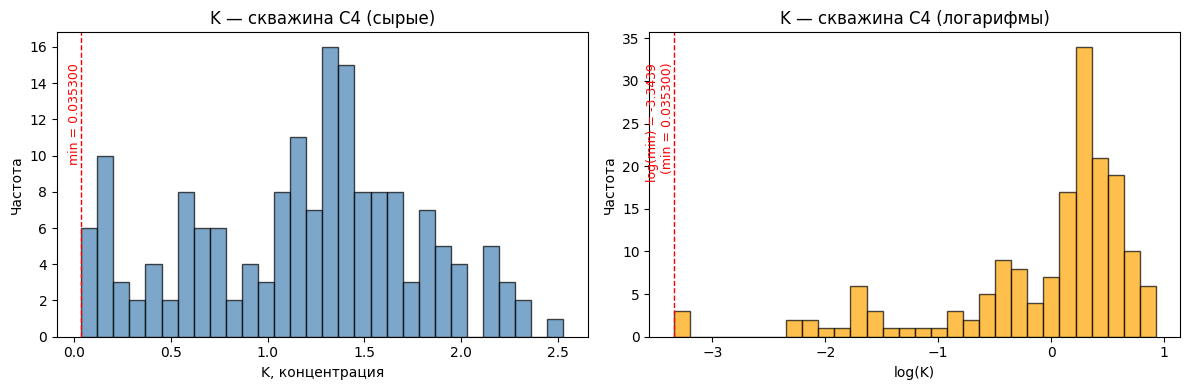

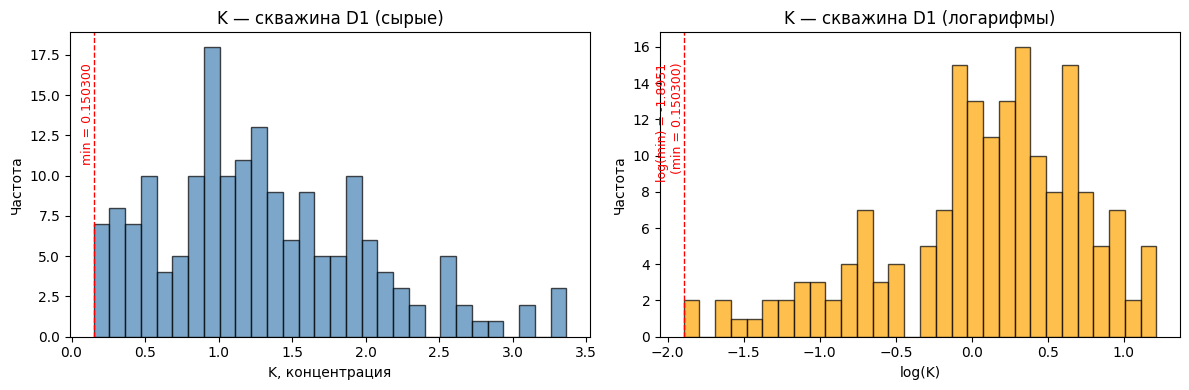

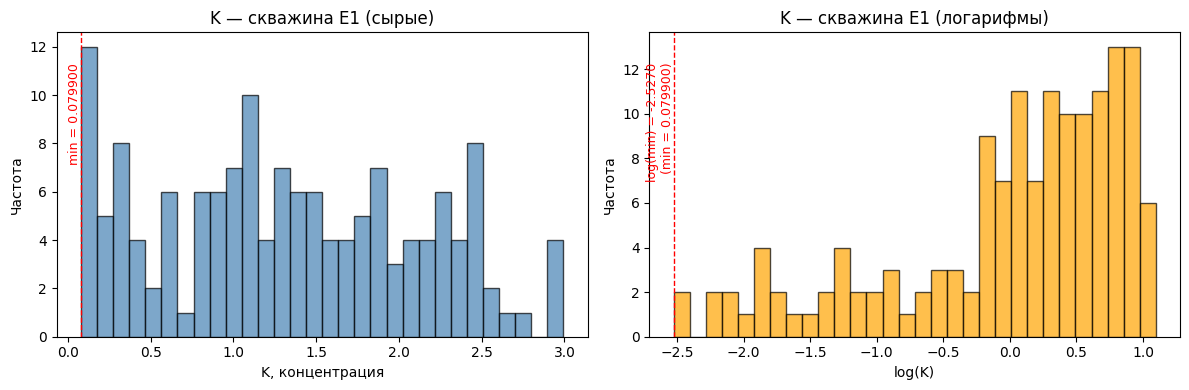


ЭЛЕМЕНТ: Ca
Всего скважин: 14
Скважин с минимумом > 0: 8


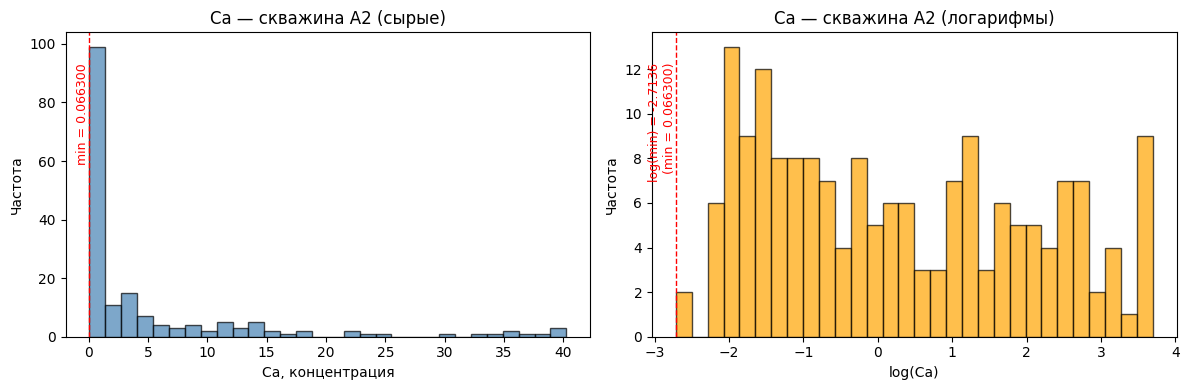

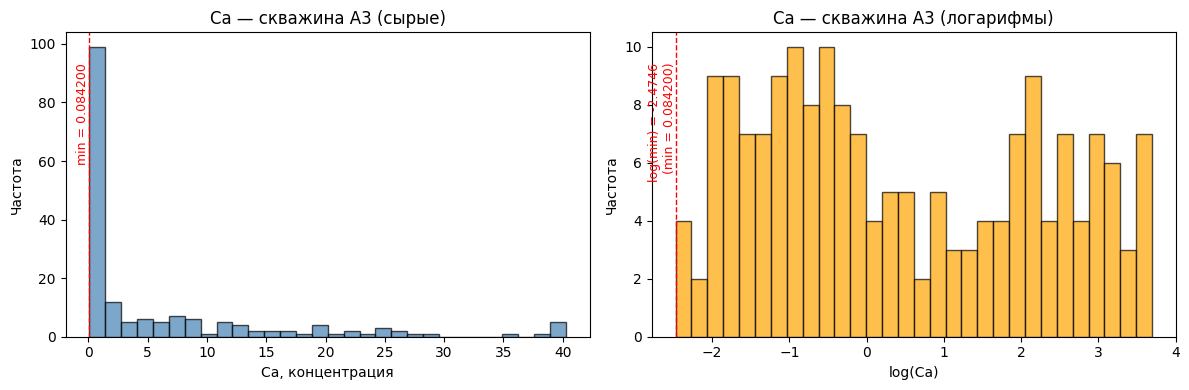

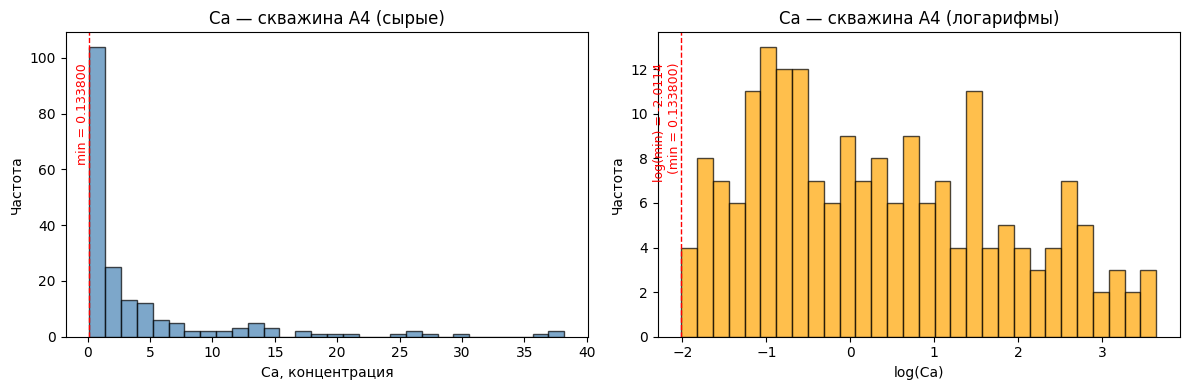

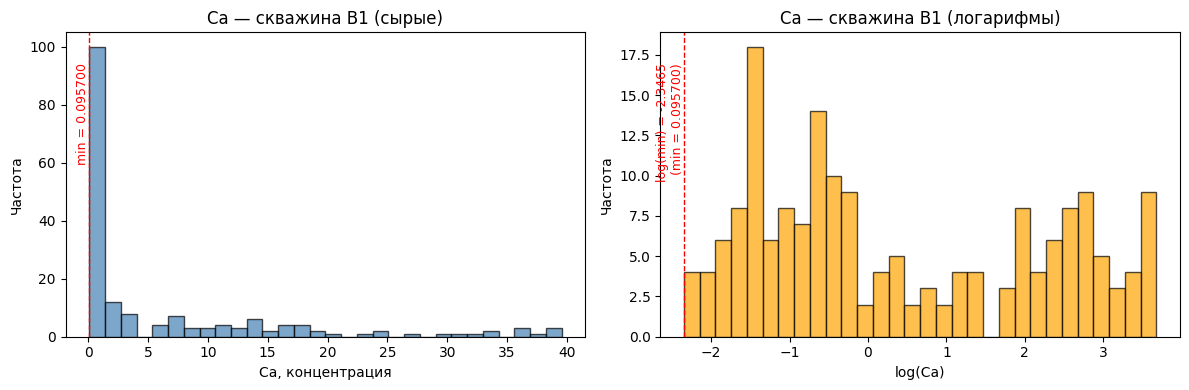

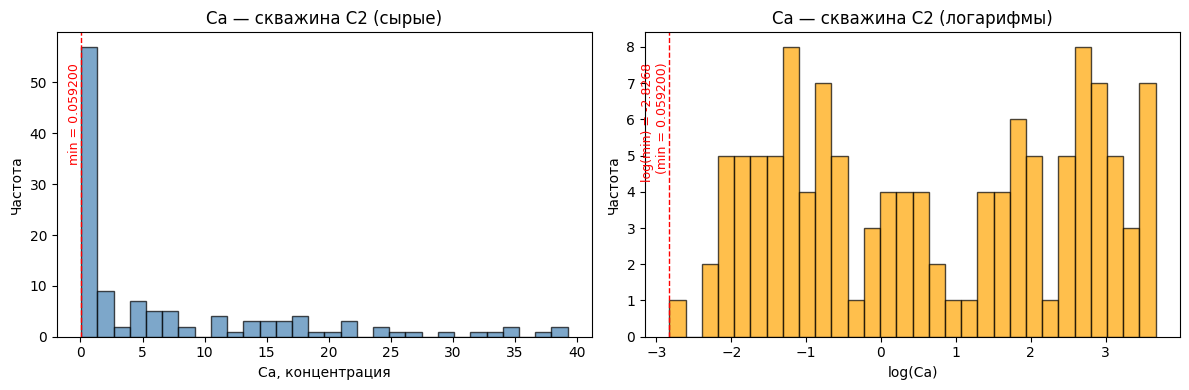

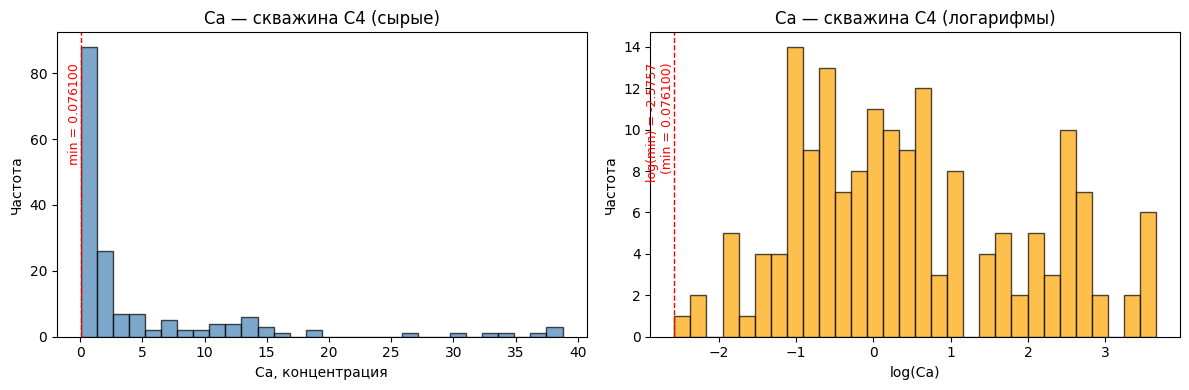

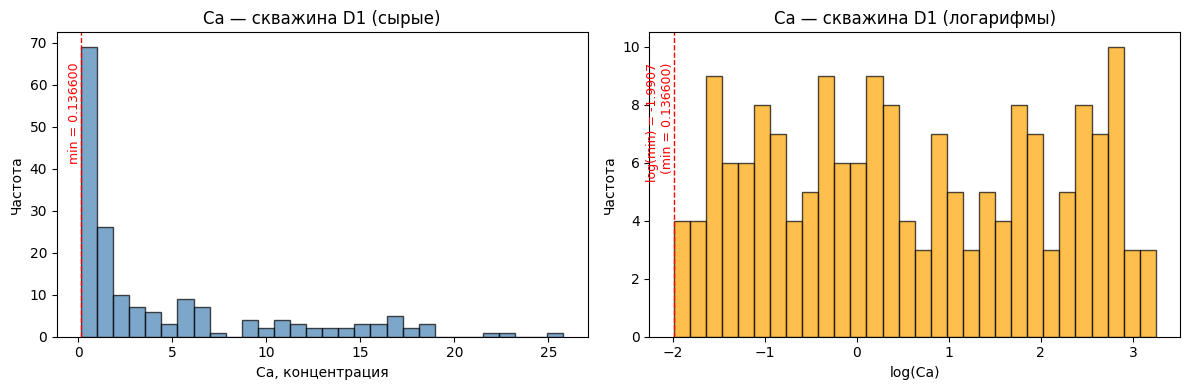

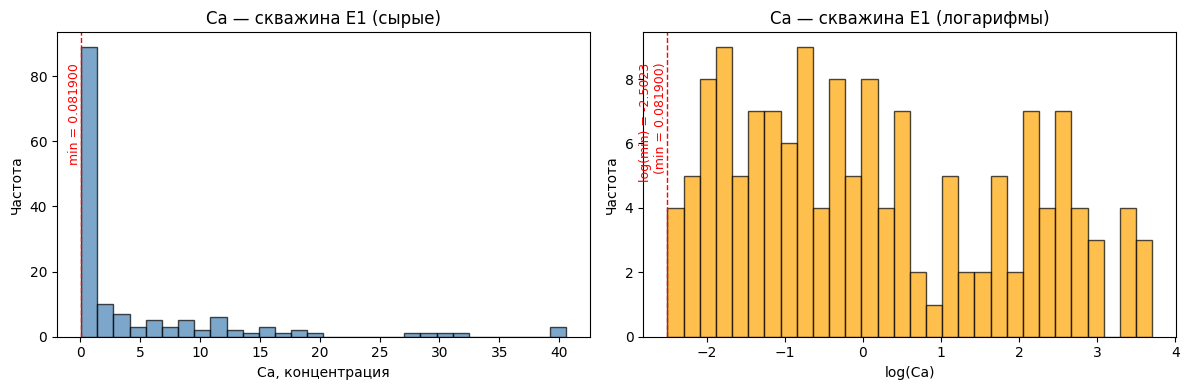


ЭЛЕМЕНТ: Ti
Всего скважин: 14
Скважин с минимумом > 0: 12


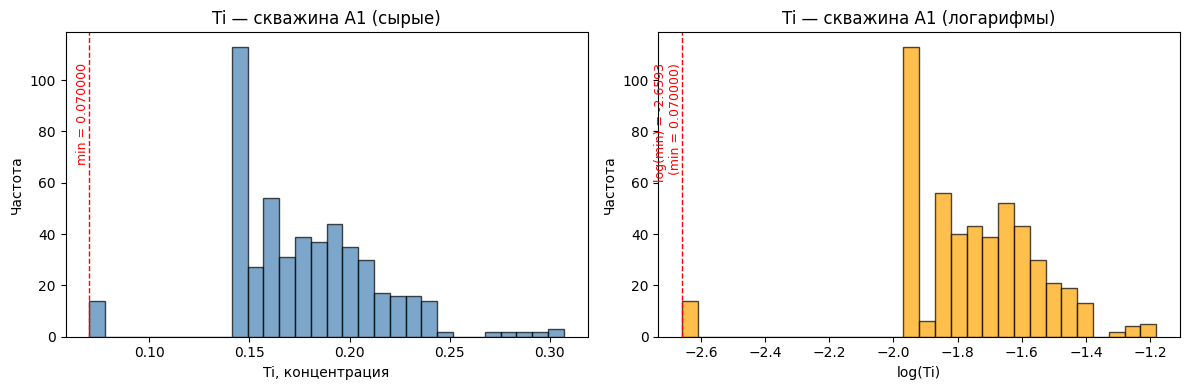

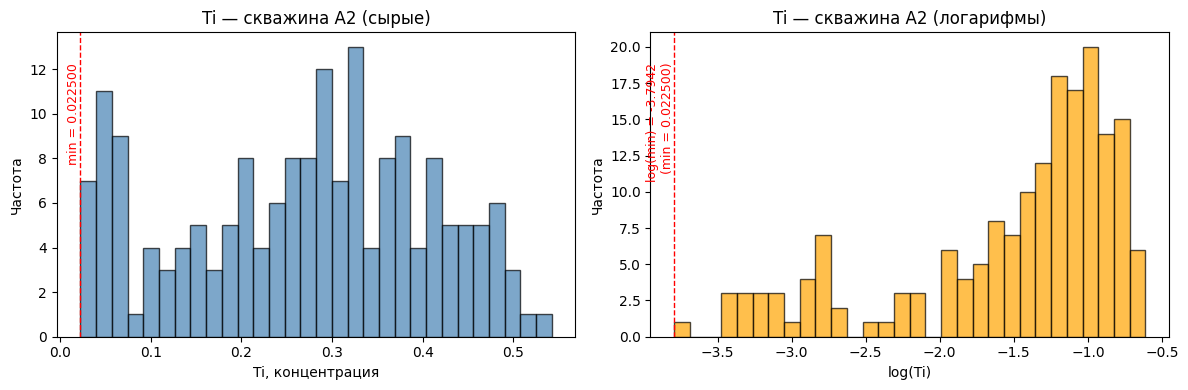

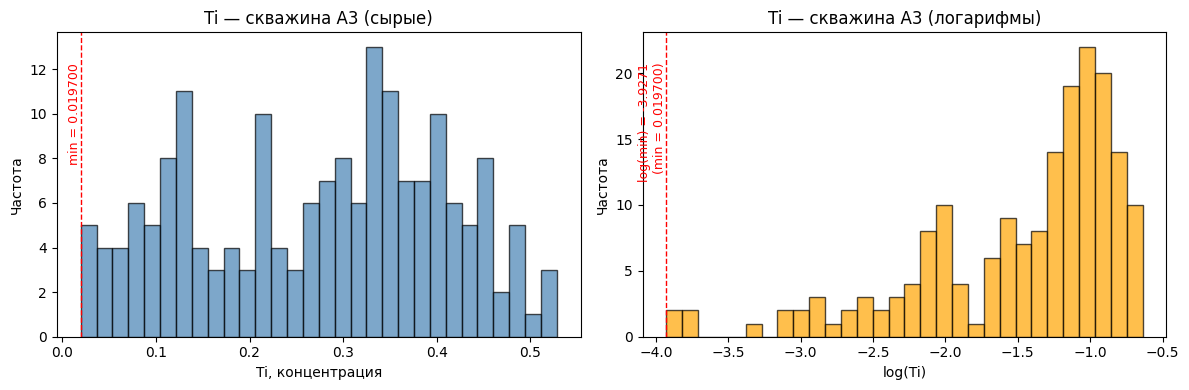

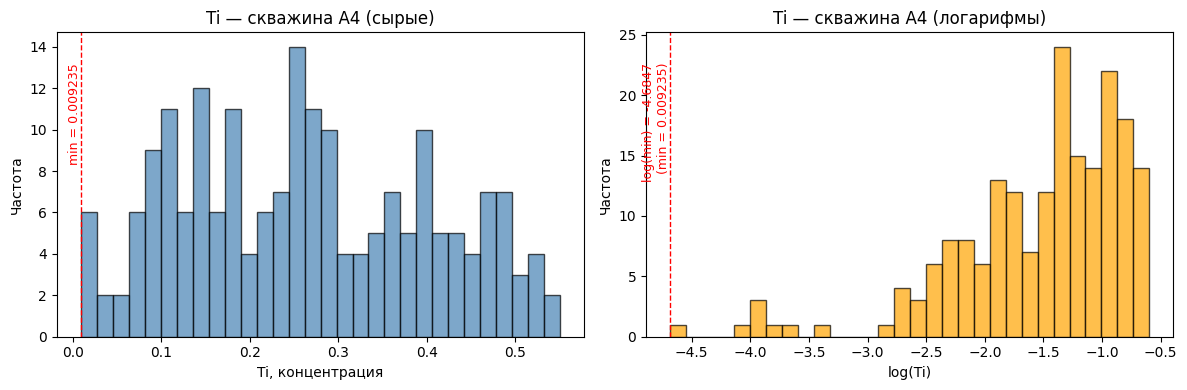

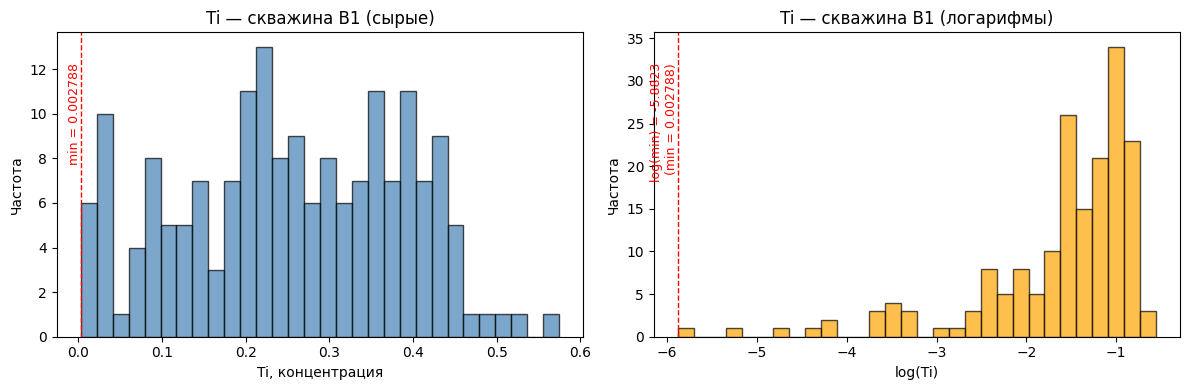

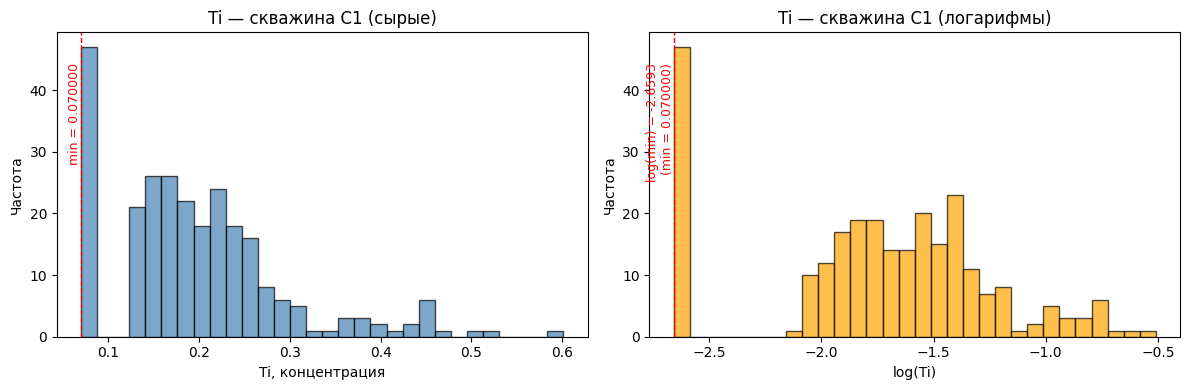

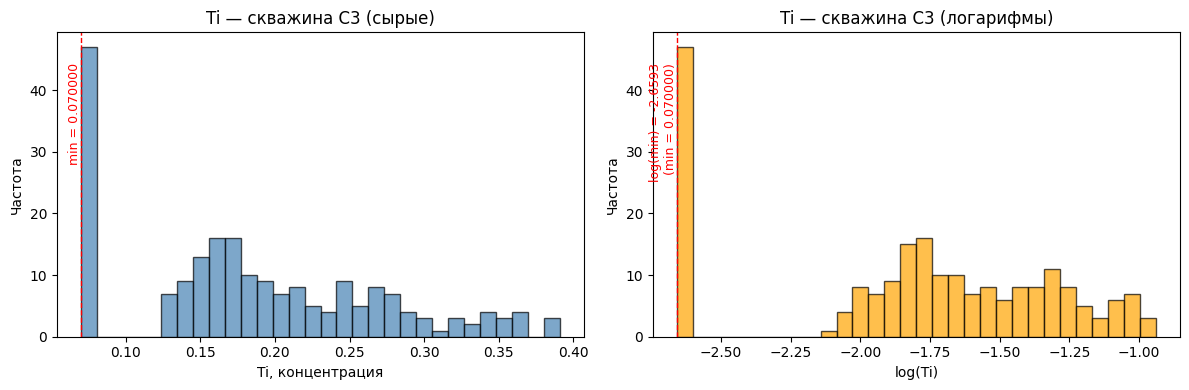

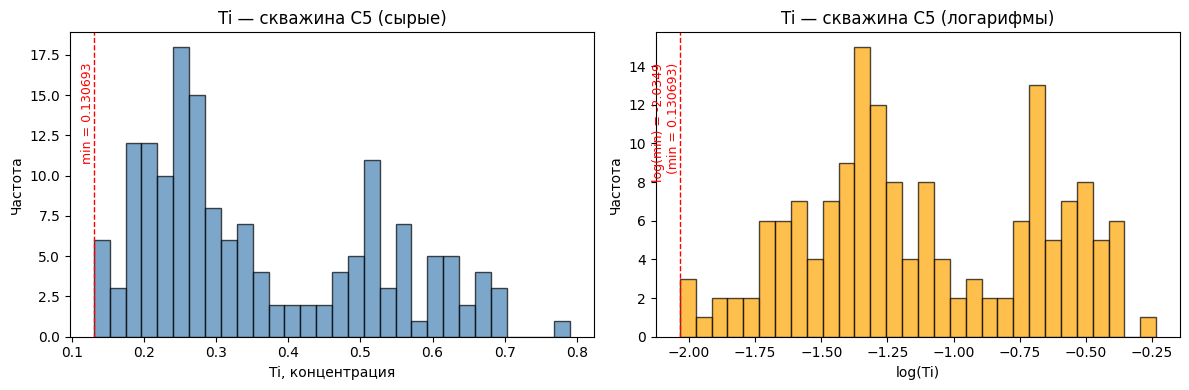

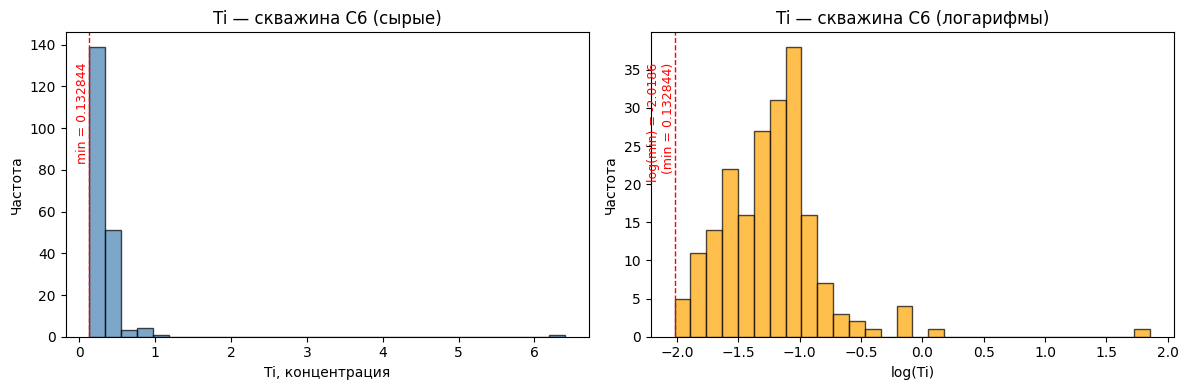

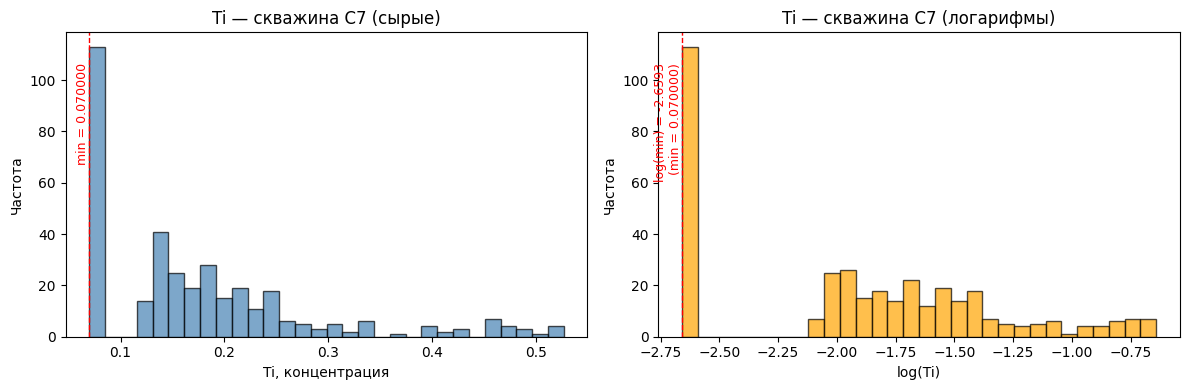

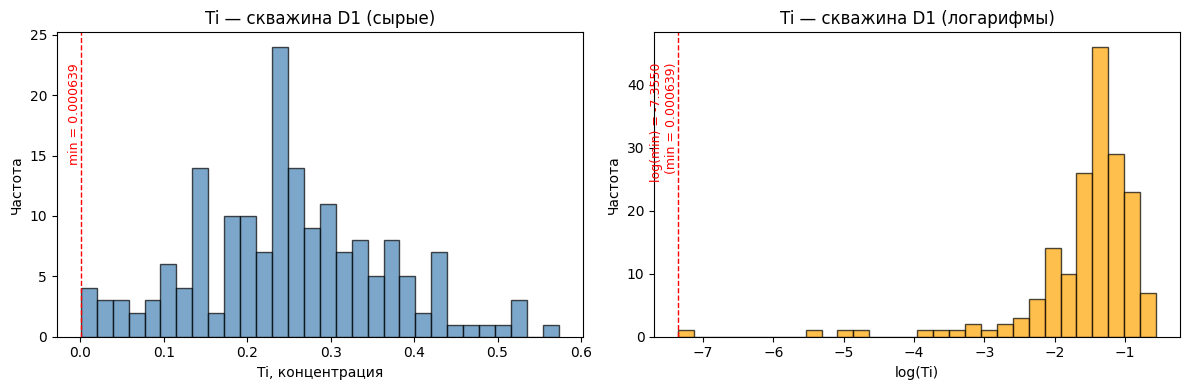

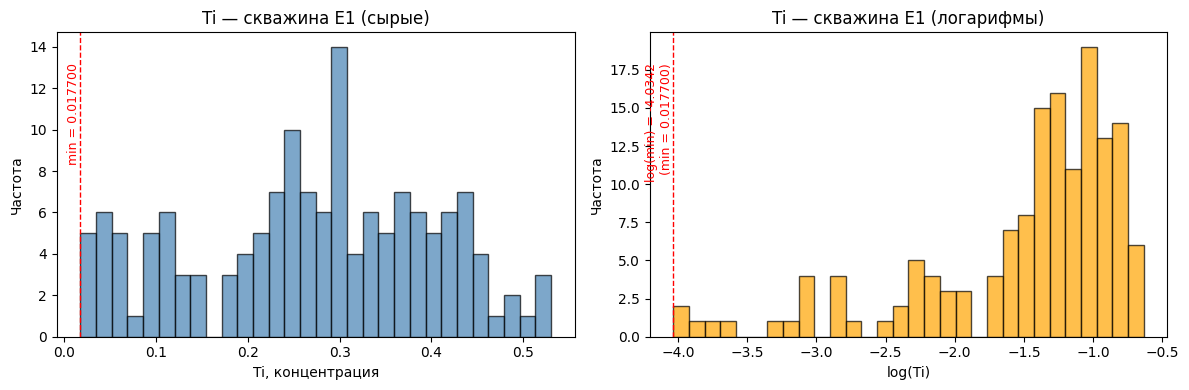


ЭЛЕМЕНТ: Mn
Всего скважин: 14
Скважин с минимумом > 0: 6


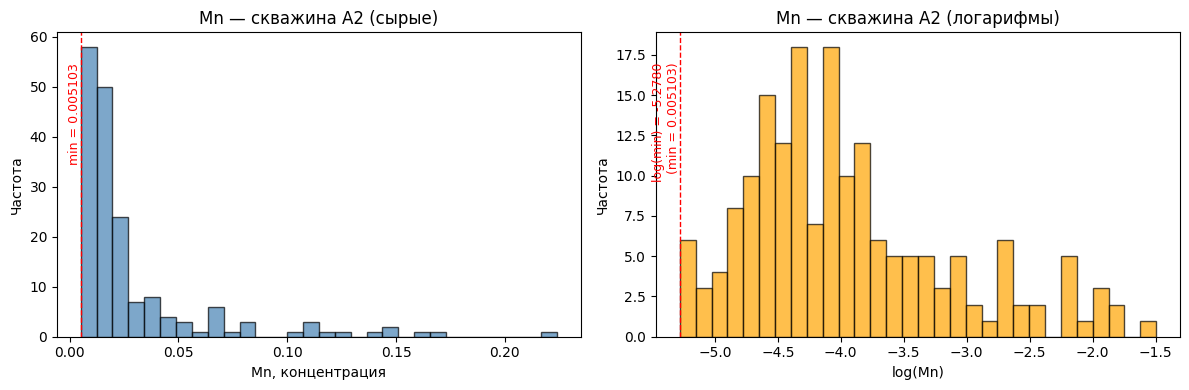

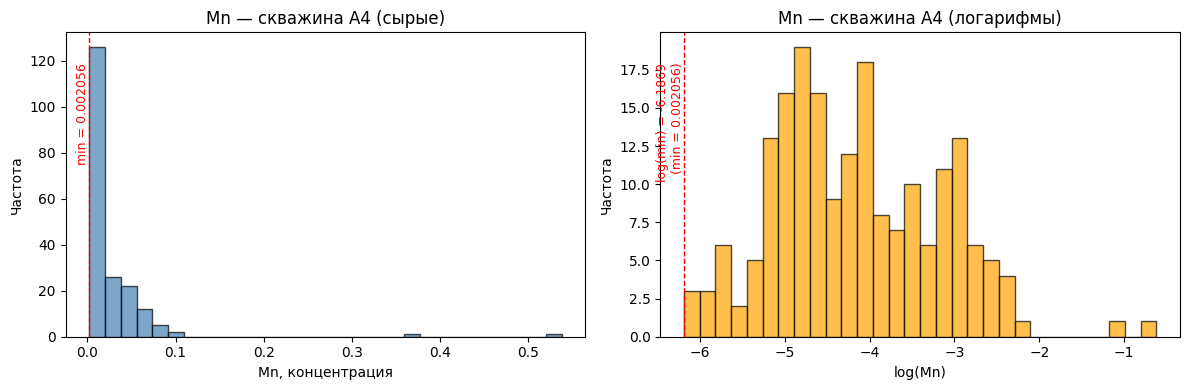

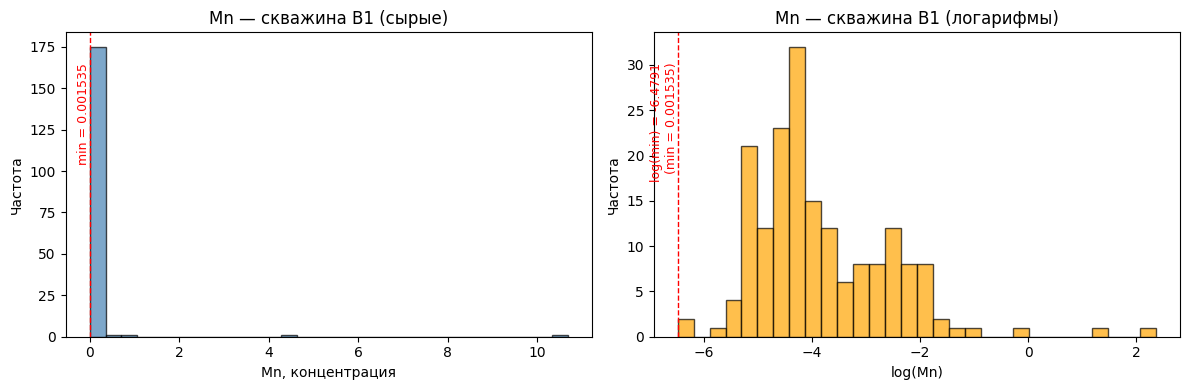

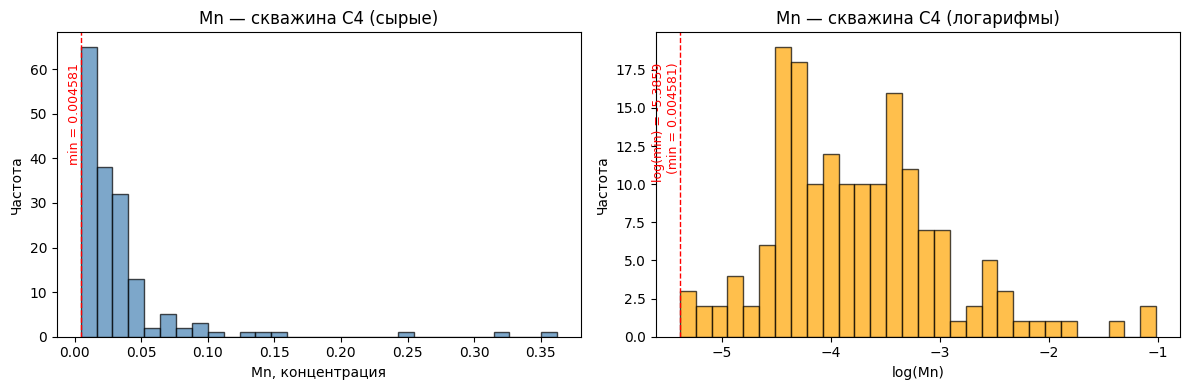

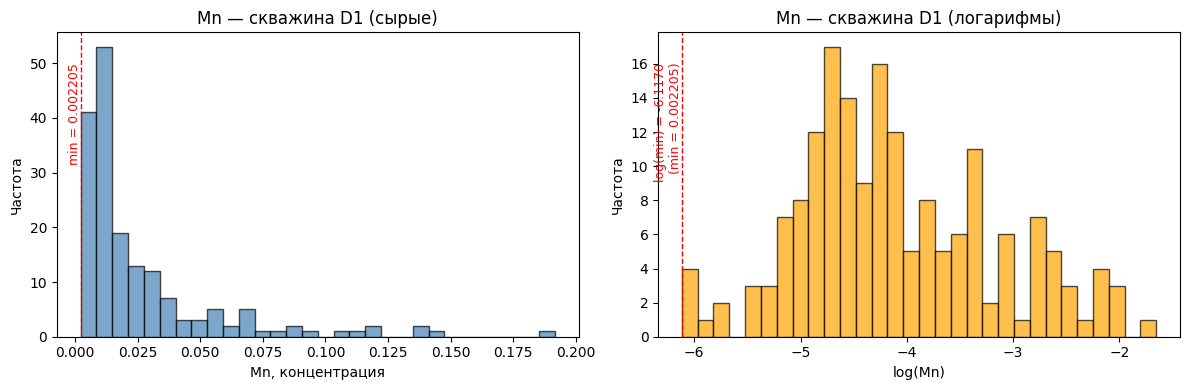

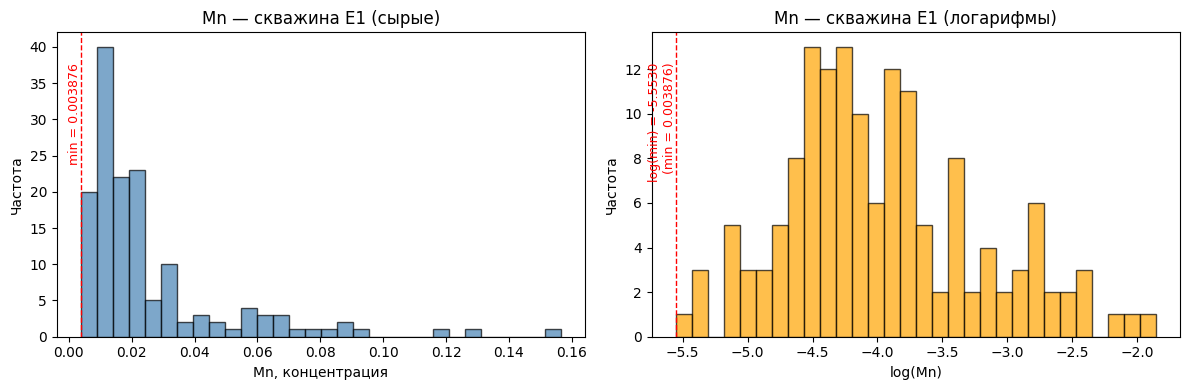


ЭЛЕМЕНТ: Fe
Всего скважин: 14
Скважин с минимумом > 0: 8


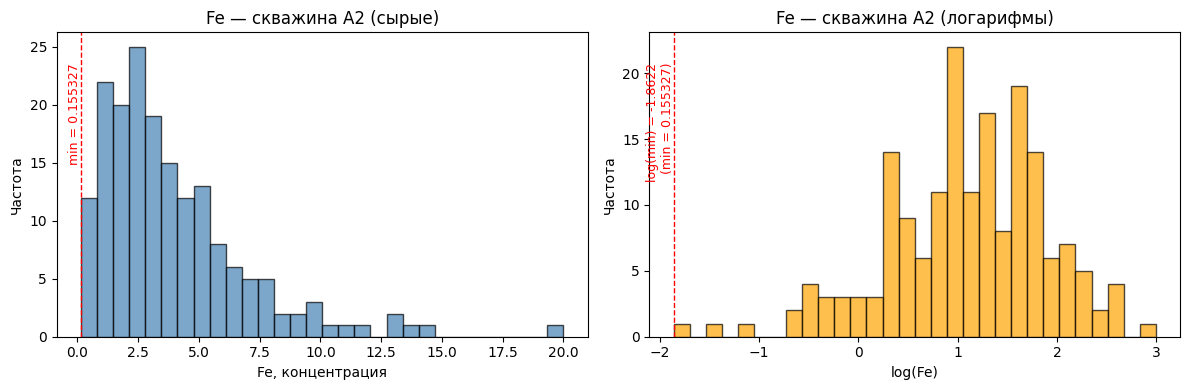

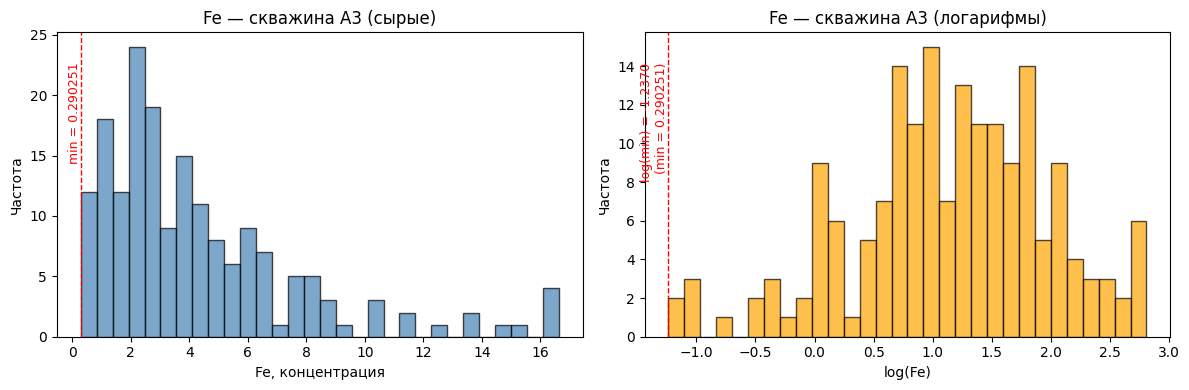

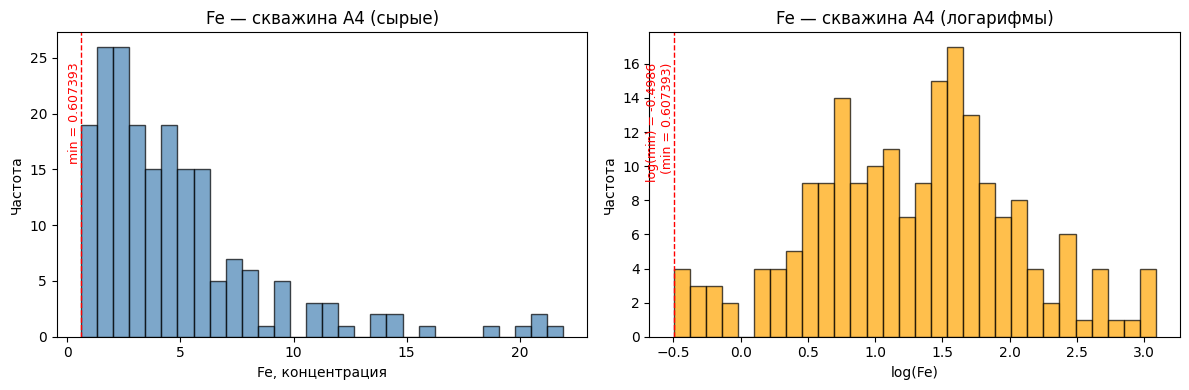

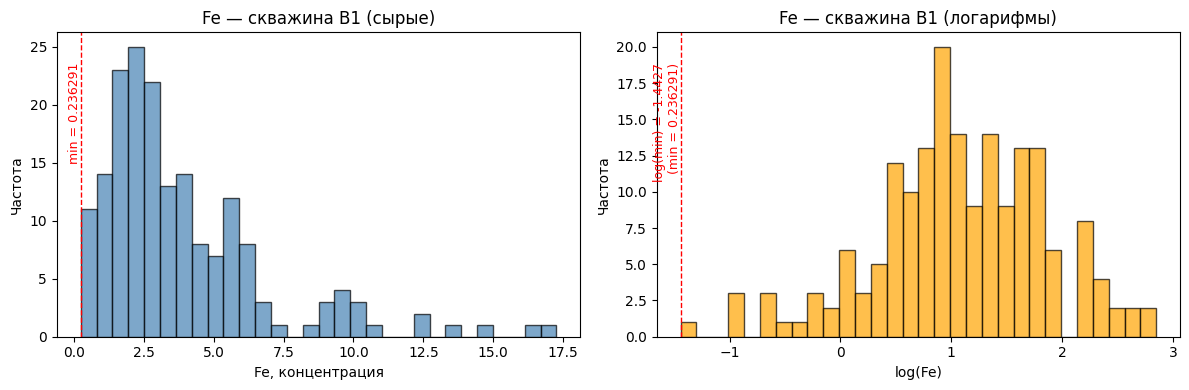

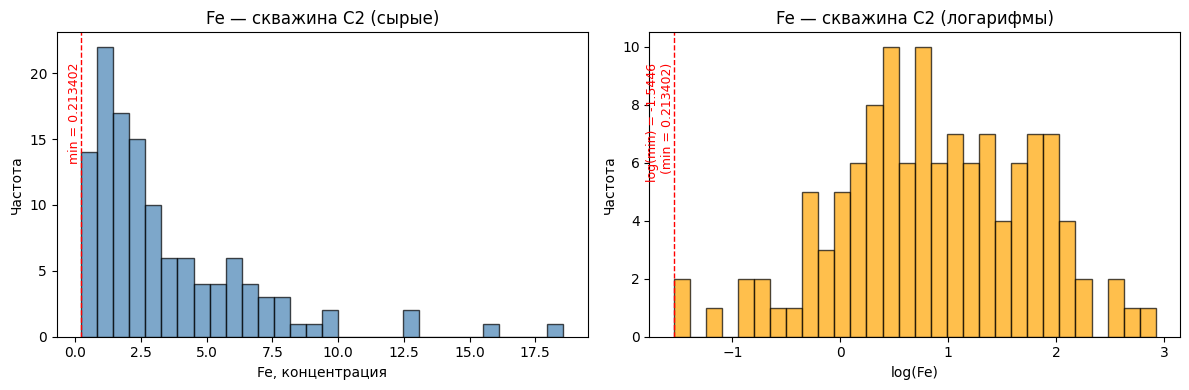

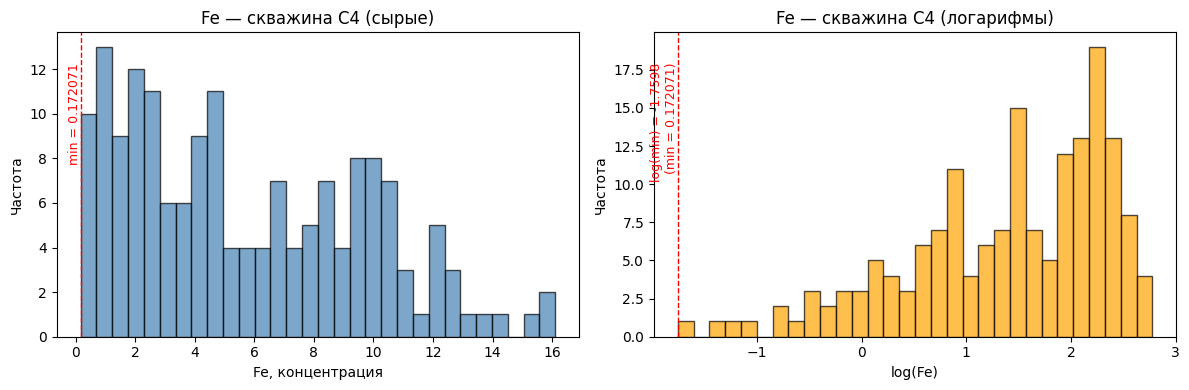

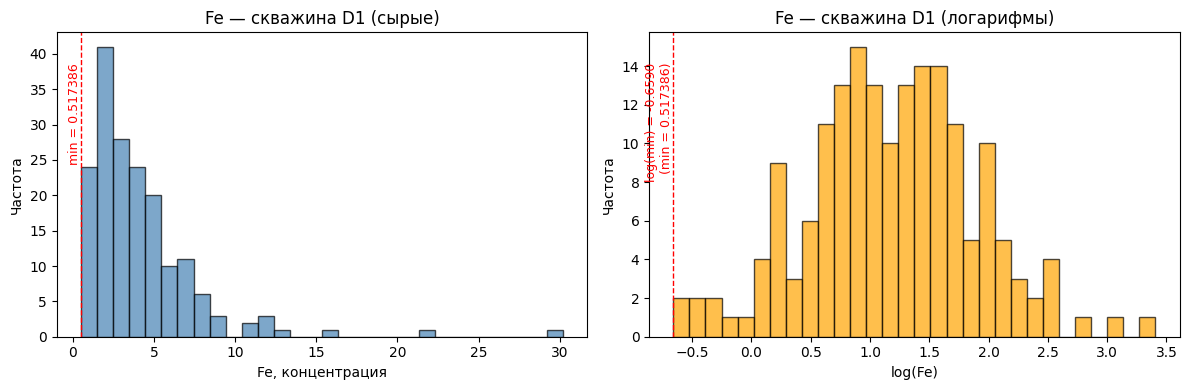

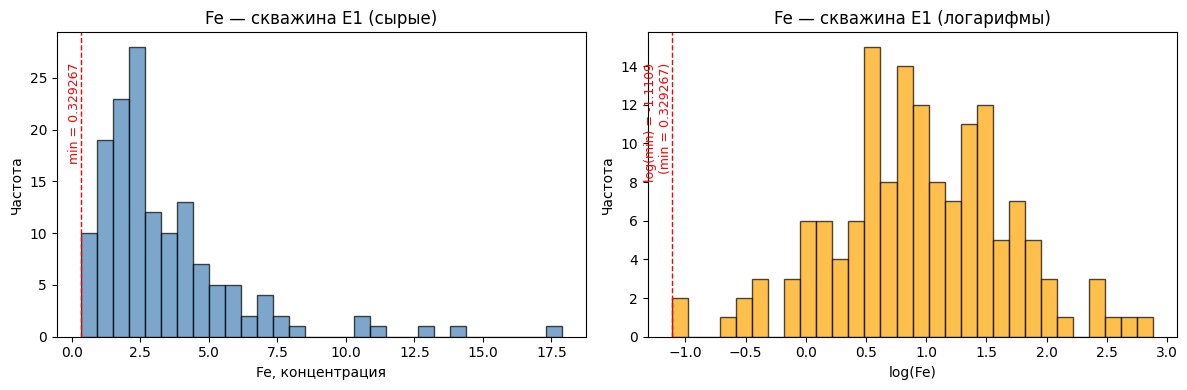


ЭЛЕМЕНТ: Ni
Всего скважин: 14
Скважин с минимумом > 0: 0
  (Все скважины имеют минимум = 0 — артефактов нет)

ЭЛЕМЕНТ: Cu
Всего скважин: 14
Скважин с минимумом > 0: 0
  (Все скважины имеют минимум = 0 — артефактов нет)

ЭЛЕМЕНТ: Zn
Всего скважин: 14
Скважин с минимумом > 0: 7


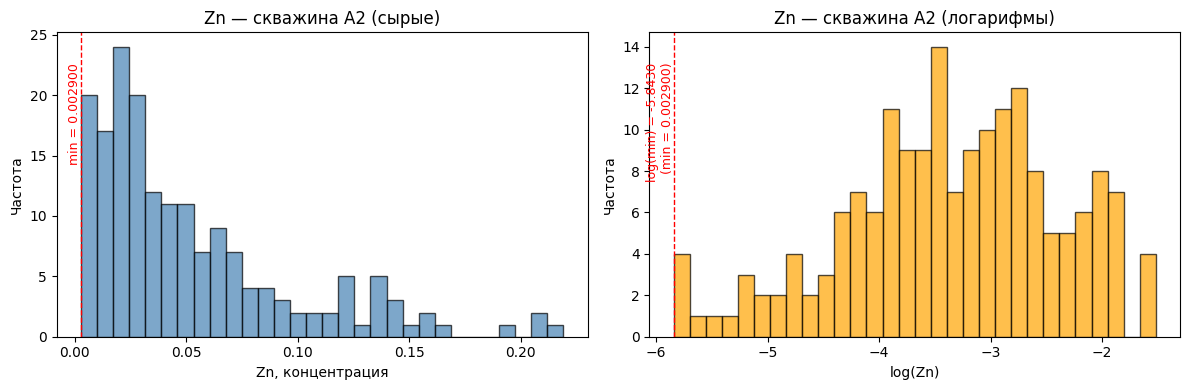

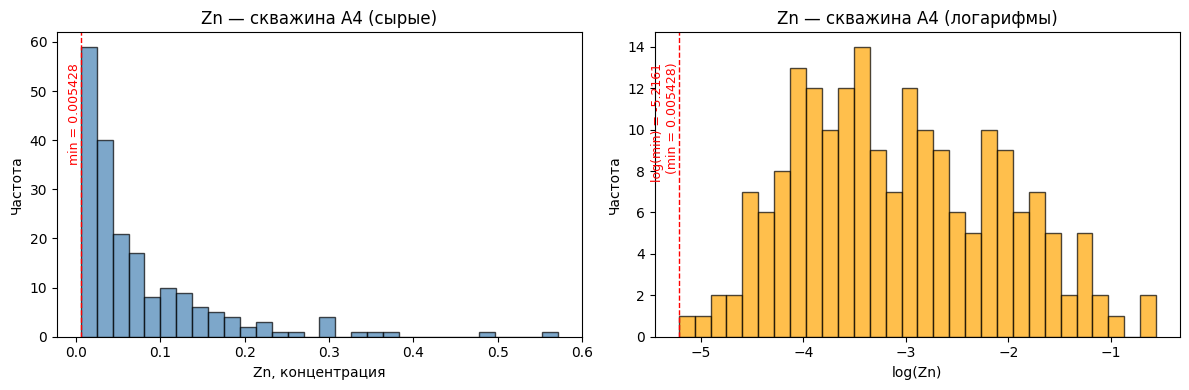

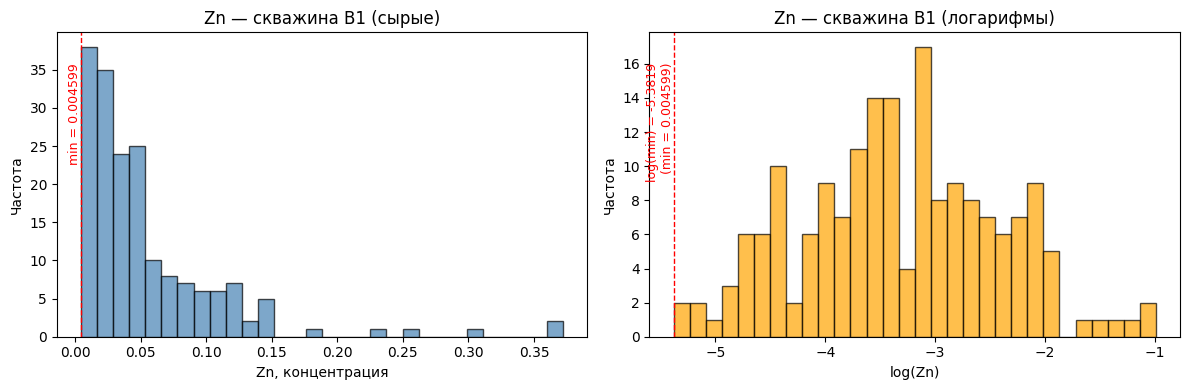

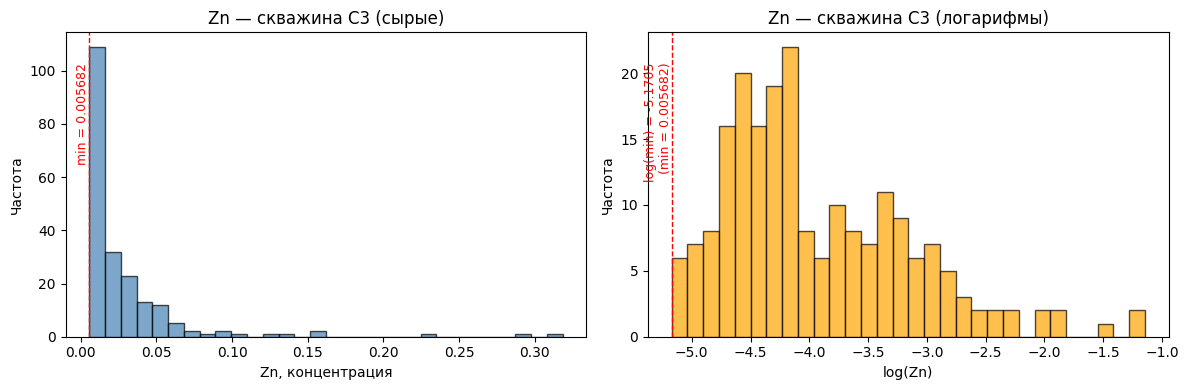

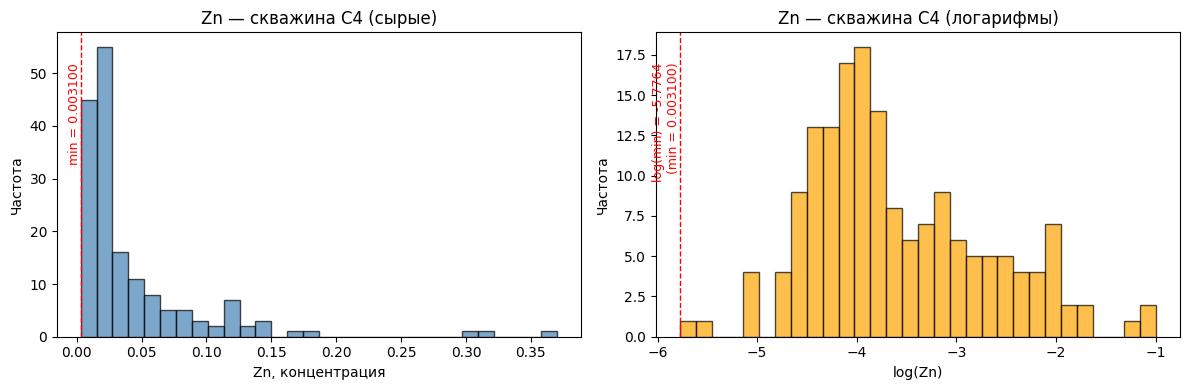

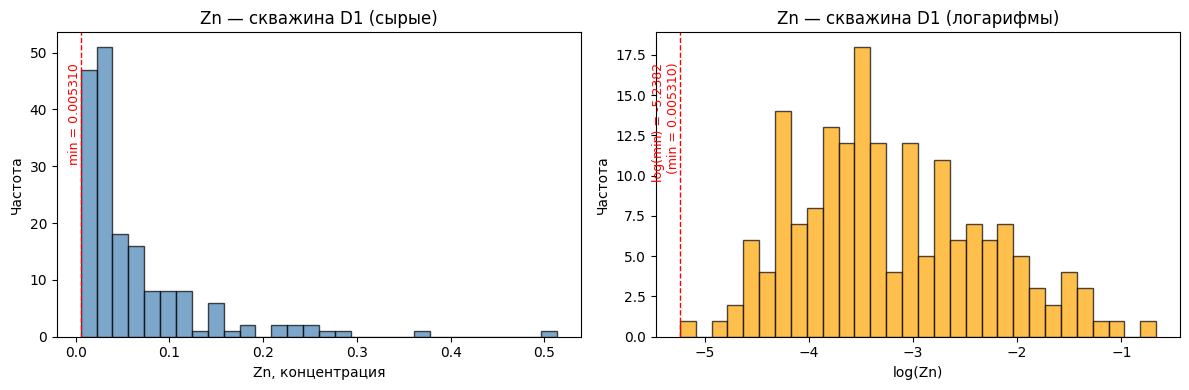

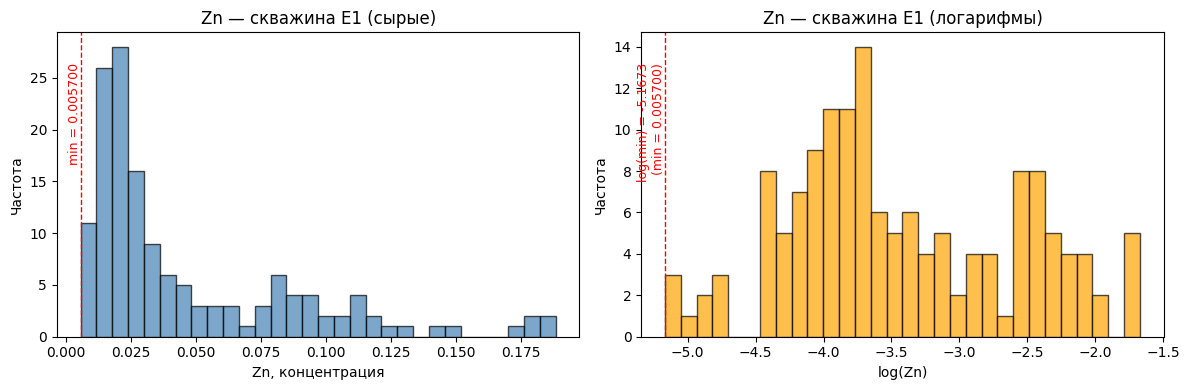


ЭЛЕМЕНТ: Se
Всего скважин: 14
Скважин с минимумом > 0: 0
  (Все скважины имеют минимум = 0 — артефактов нет)

ЭЛЕМЕНТ: Rb
Всего скважин: 14
Скважин с минимумом > 0: 2


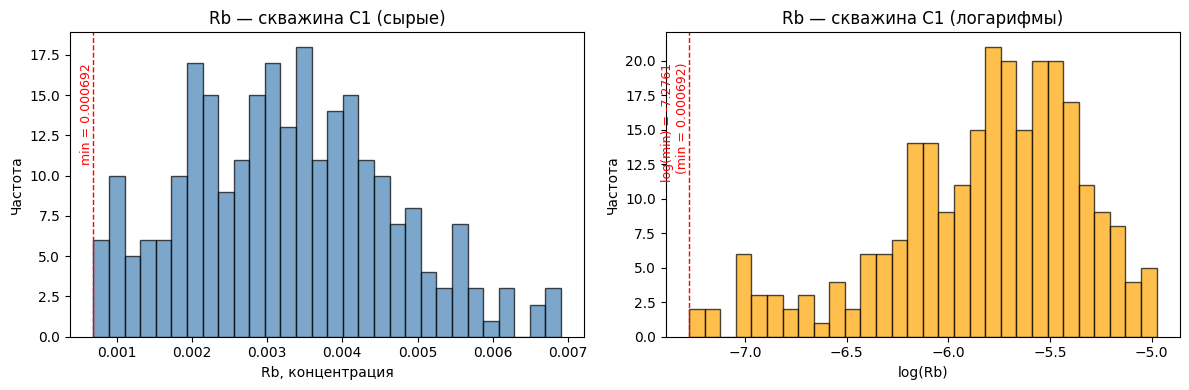

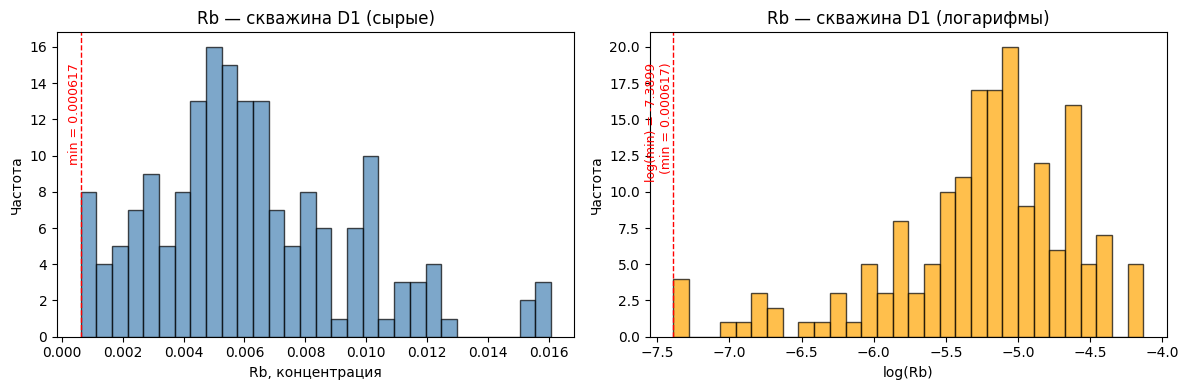


ЭЛЕМЕНТ: Sr
Всего скважин: 14
Скважин с минимумом > 0: 12


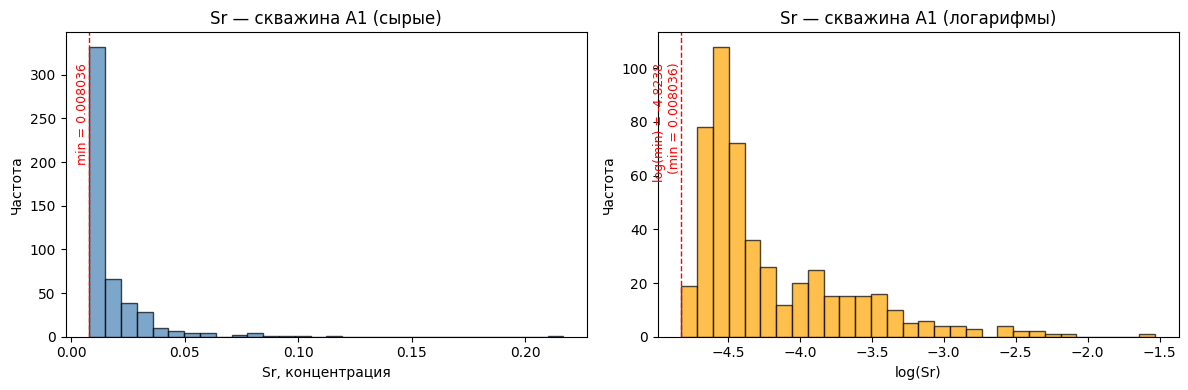

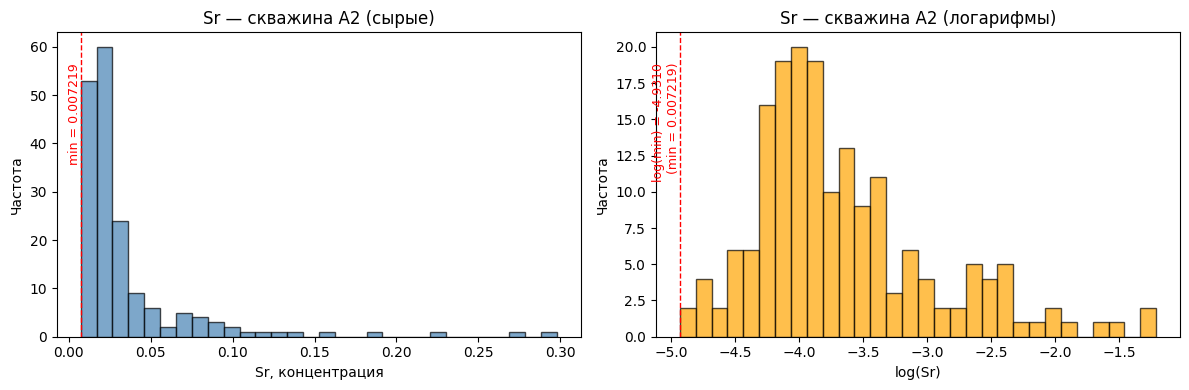

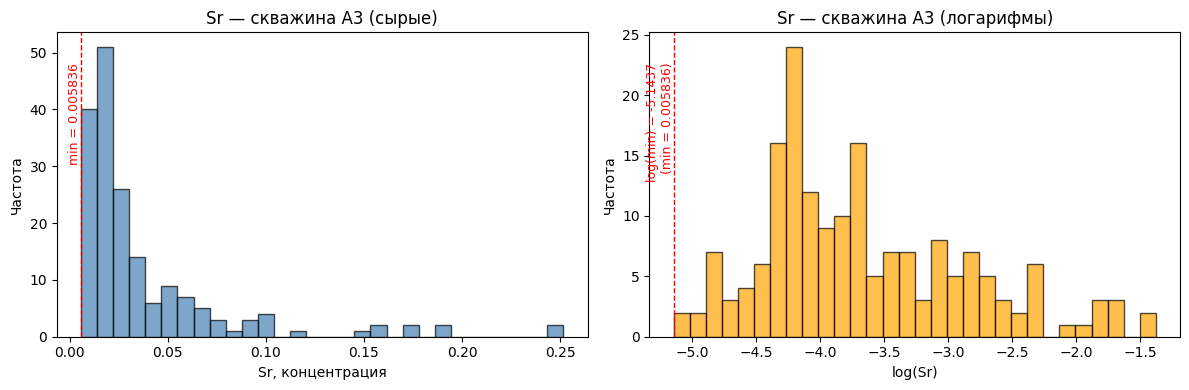

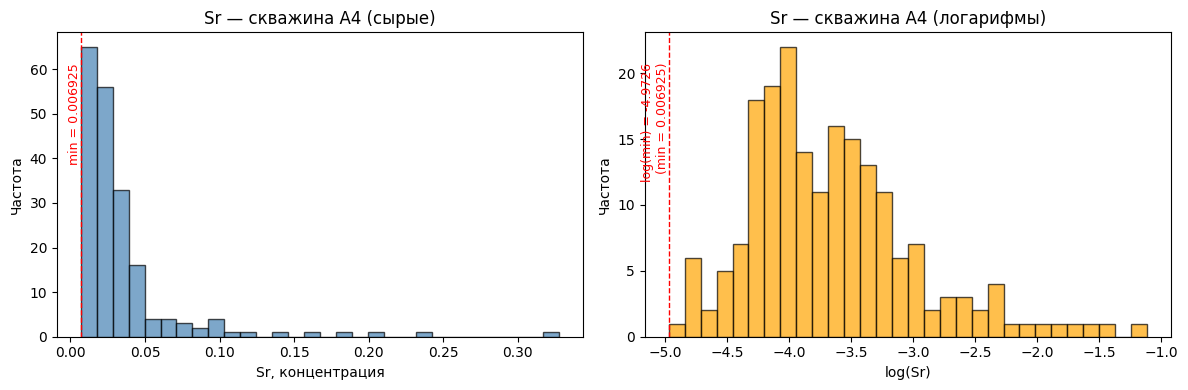

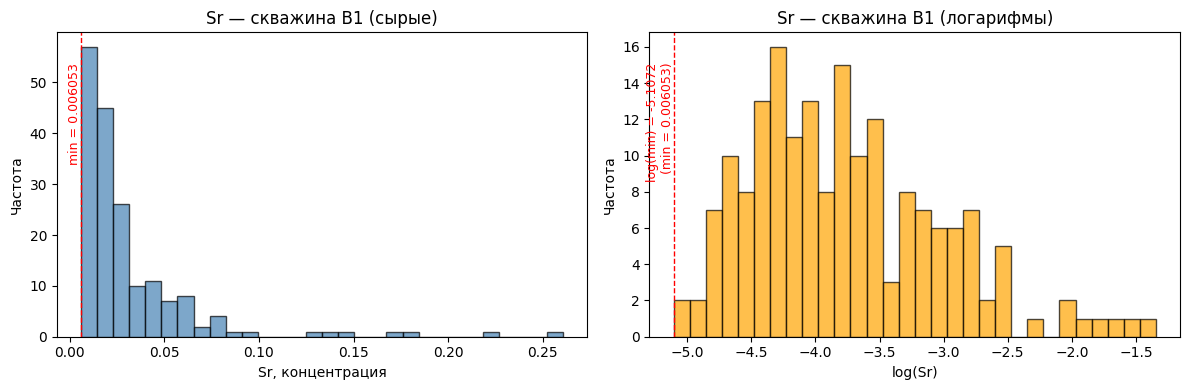

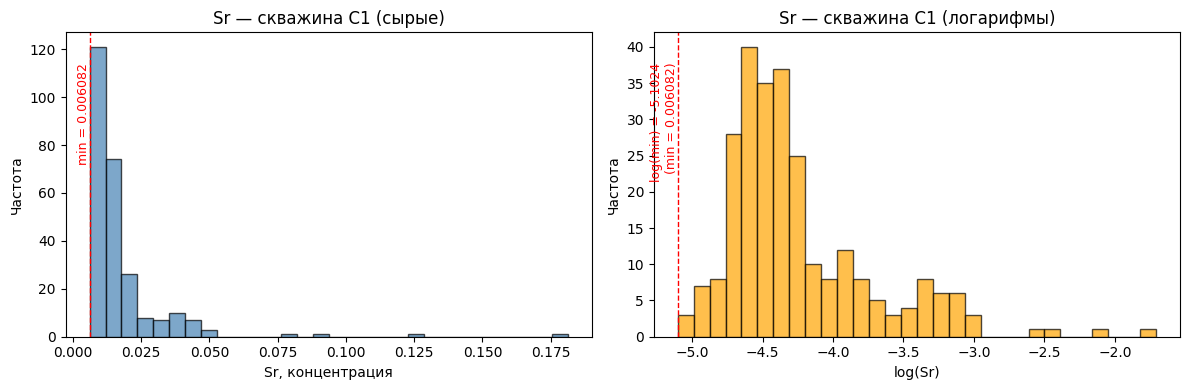

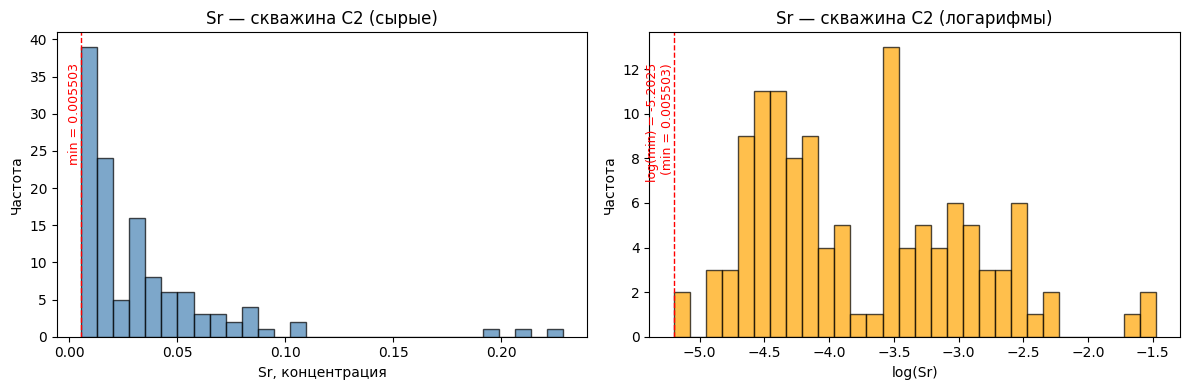

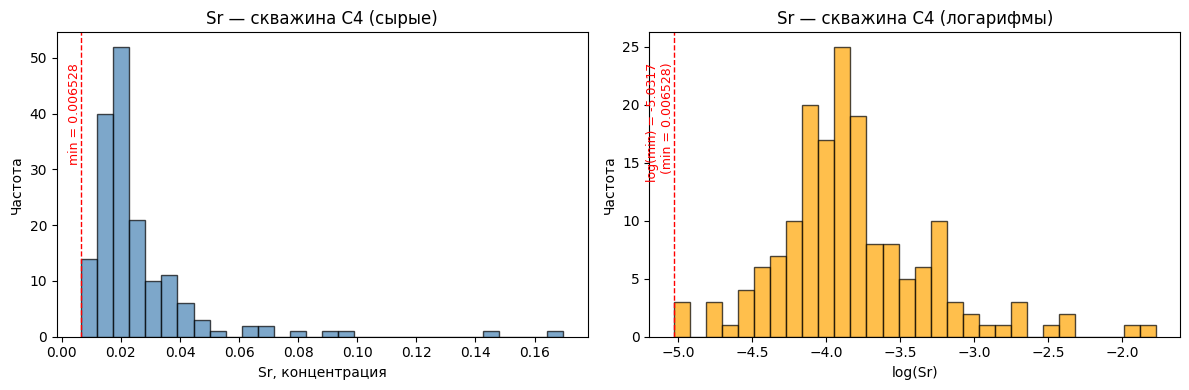

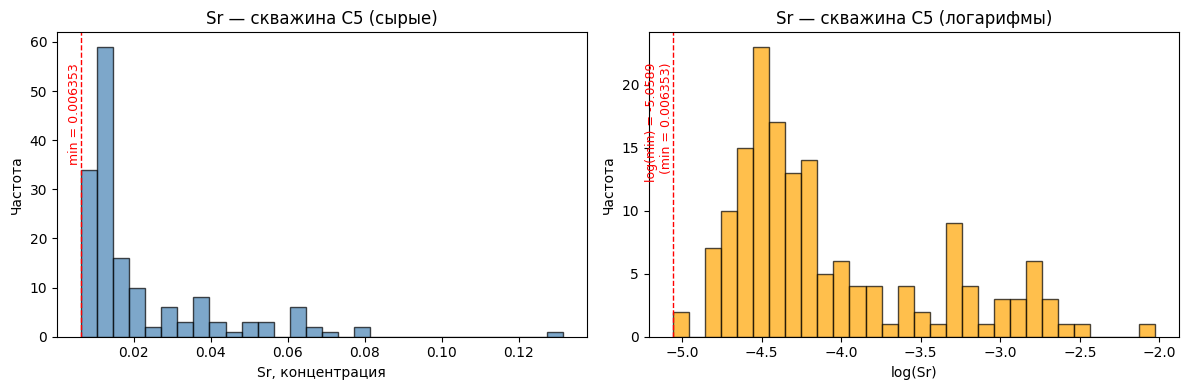

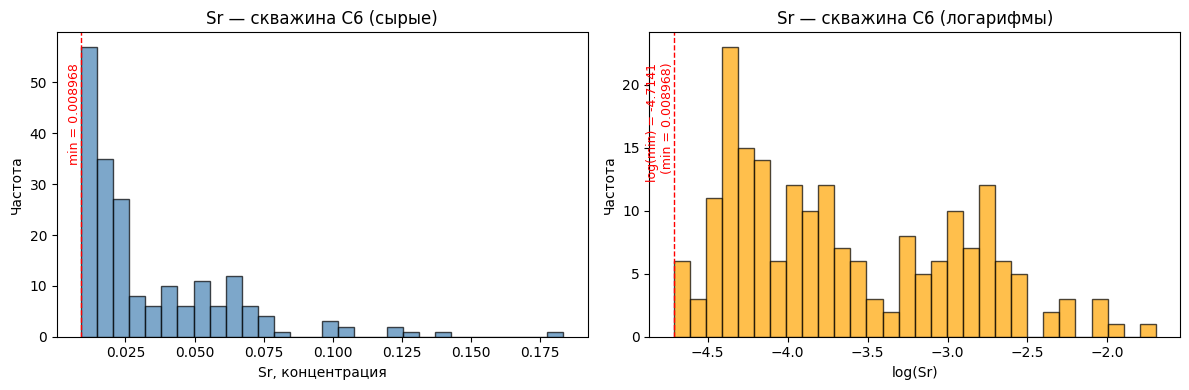

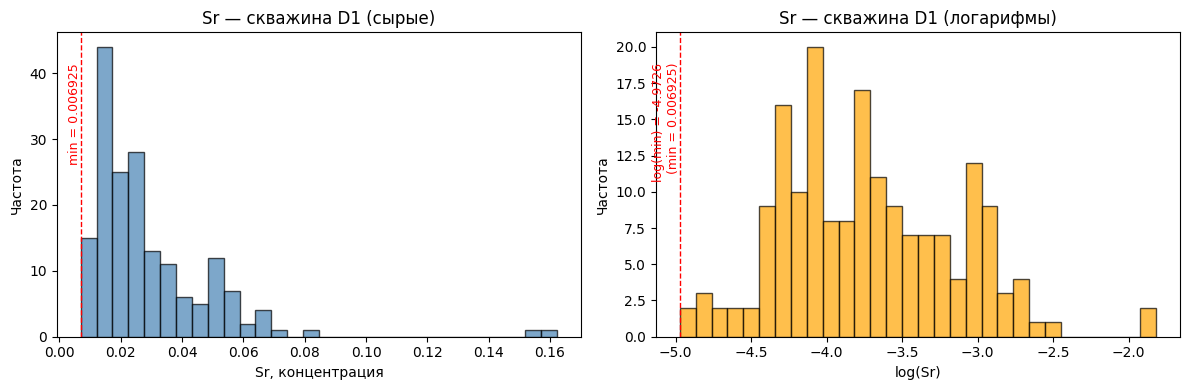

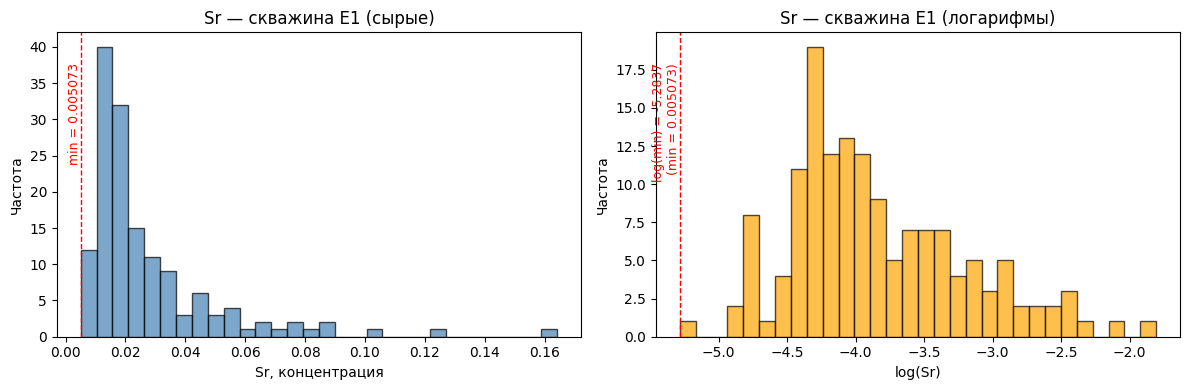


ЭЛЕМЕНТ: Zr
Всего скважин: 14
Скважин с минимумом > 0: 8


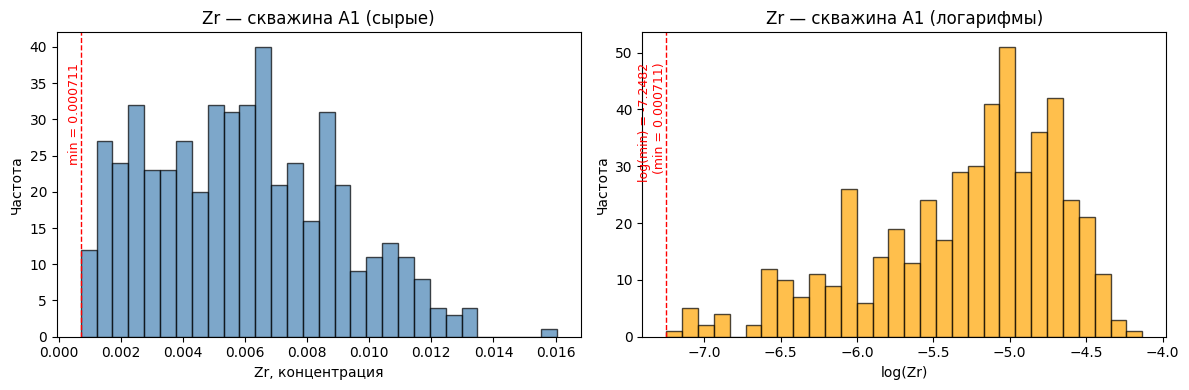

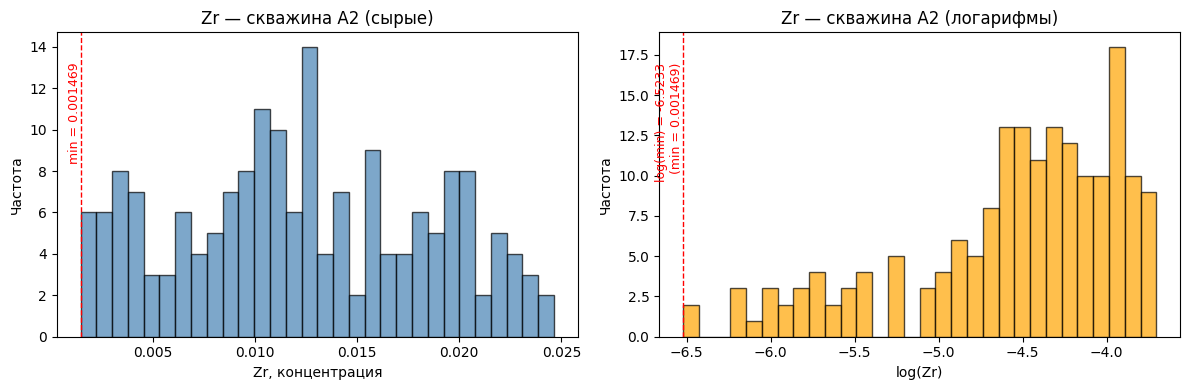

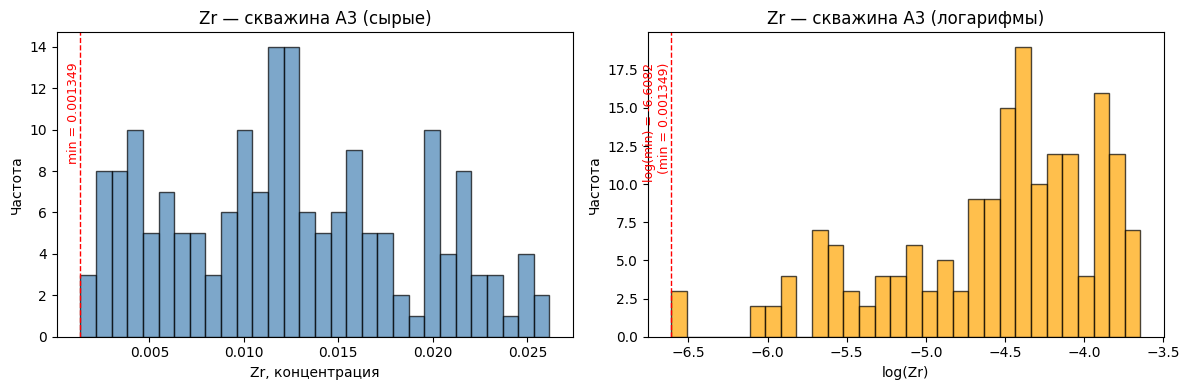

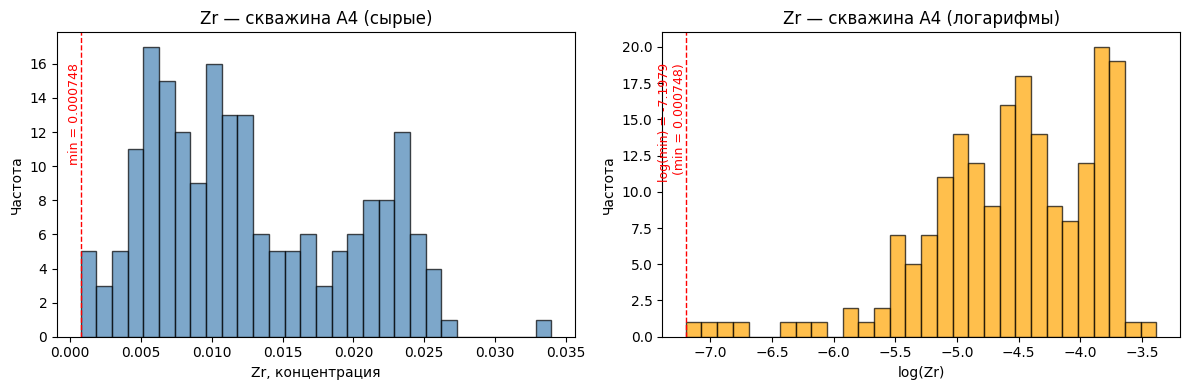

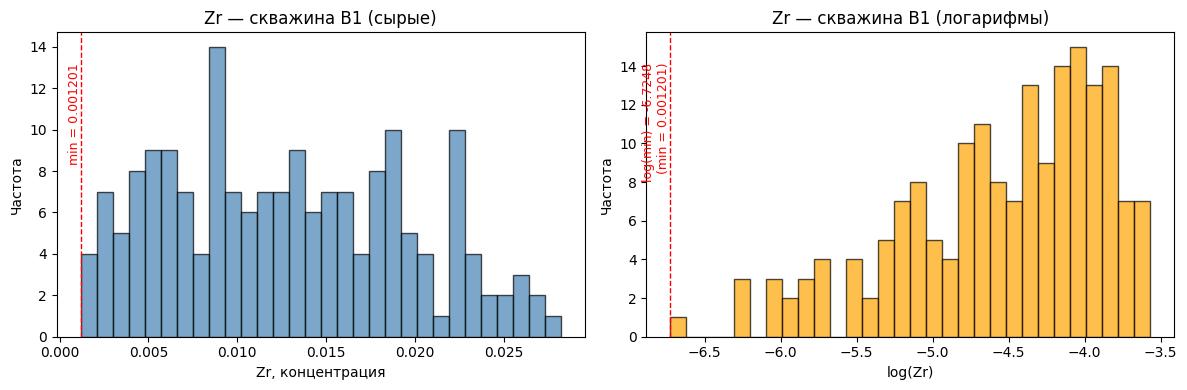

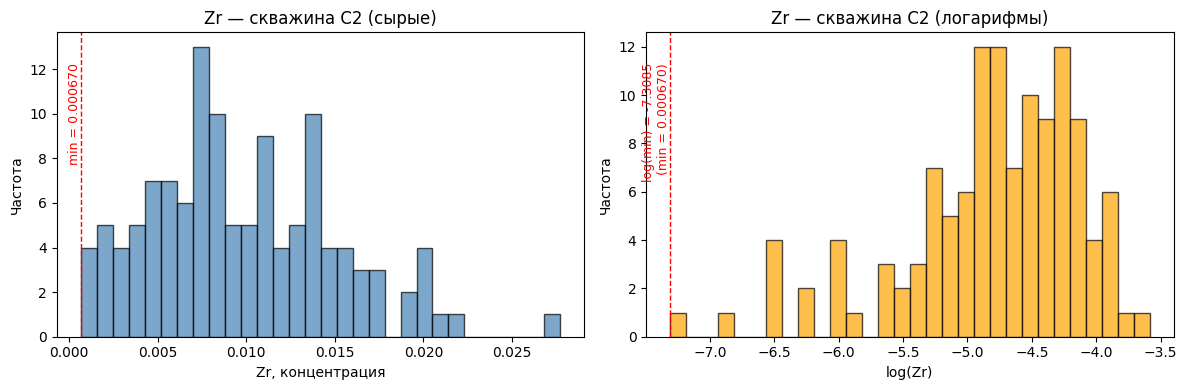

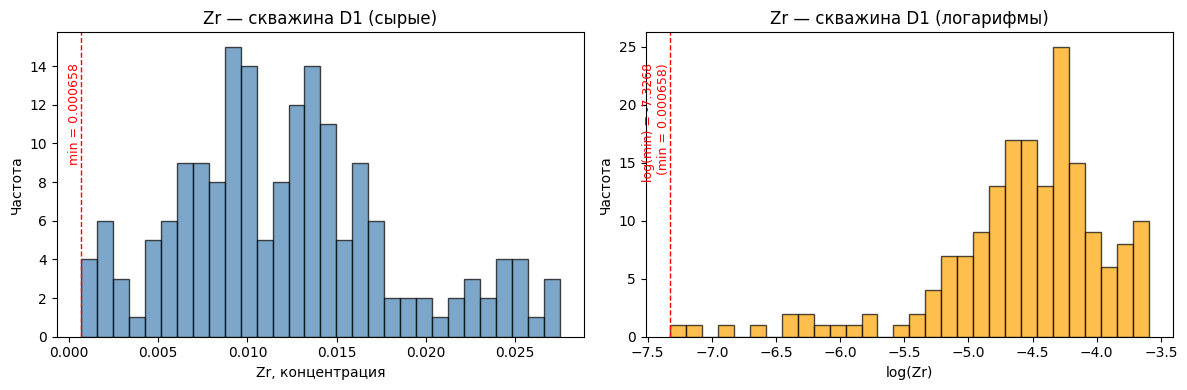

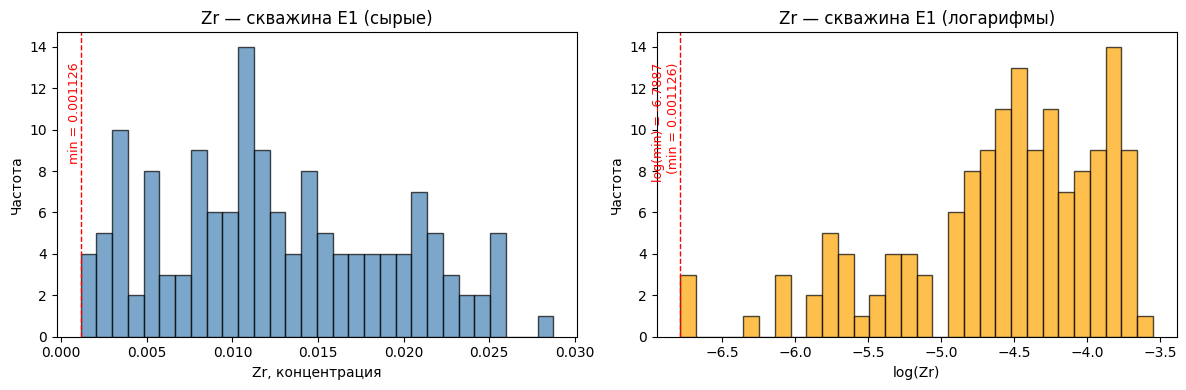


ЭЛЕМЕНТ: Mo
Всего скважин: 14
Скважин с минимумом > 0: 0
  (Все скважины имеют минимум = 0 — артефактов нет)


In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

elements = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

for element in elements:
    if element not in df_filtered.columns:
        print(f"Элемент {element} отсутствует в данных, пропускаем.")
        continue
    
    df_elem = df_filtered[['Well', element]].dropna()
    
    # Находим МИНИМУМ по каждой скважине (включая нули)
    min_by_well = df_elem.groupby('Well')[element].min()
    
    # Оставляем только те скважины, где минимум НЕ равен нулю
    min_nonzero = min_by_well[min_by_well > 0]
    
    print(f"\n{'='*60}")
    print(f"ЭЛЕМЕНТ: {element}")
    print(f"{'='*60}")
    print(f"Всего скважин: {len(min_by_well)}")
    print(f"Скважин с минимумом > 0: {len(min_nonzero)}")
    
    if len(min_nonzero) == 0:
        print(f"  (Все скважины имеют минимум = 0 — артефактов нет)")
        continue
    
    # Гистограммы для каждой скважины, где минимум не 0
    for well in min_nonzero.index:
        df_well = df_elem[df_elem['Well'] == well]
        values = df_well[element].values
        min_val = values[values > 0].min() if (values > 0).any() else np.nan
        
        # Строим гистограмму сырых значений и логарифмов
        fig, ax = plt.subplots(1, 2, figsize=(12, 4))
        
        # --- 1. Сырые значения ---
        ax[0].hist(values, bins=30, color='steelblue', edgecolor='black', alpha=0.7)
        ax[0].set_xlabel(f'{element}, концентрация')
        ax[0].set_ylabel('Частота')
        ax[0].set_title(f'{element} — скважина {well} (сырые)')
        
        # Подпись минимума (ненулевого) на гистограмме
        if not np.isnan(min_val):
            ax[0].axvline(min_val, color='red', linestyle='--', linewidth=1)
            ax[0].text(min_val, ax[0].get_ylim()[1] * 0.9,
                       f'min = {min_val:.6f}',
                       color='red', fontsize=9, rotation=90, va='top', ha='right')
        
        # --- 2. Логарифмы ---
        log_values = np.log(values)
        ax[1].hist(log_values, bins=30, color='orange', edgecolor='black', alpha=0.7)
        ax[1].set_xlabel(f'log({element})')
        ax[1].set_ylabel('Частота')
        ax[1].set_title(f'{element} — скважина {well} (логарифмы)')
        
        # Подпись минимума (в логарифмах)
        if not np.isnan(min_val) and min_val > 0:
            log_min = np.log(min_val)
            ax[1].axvline(log_min, color='red', linestyle='--', linewidth=1)
            ax[1].text(log_min, ax[1].get_ylim()[1] * 0.9,
                       f'log(min) = {log_min:.4f}\n(min = {min_val:.6f})',
                       color='red', fontsize=9, rotation=90, va='top', ha='right')
        
        plt.tight_layout()
        plt.savefig(f'hist_{element}_{well}.png', dpi=150, bbox_inches='tight')
        plt.show()
        plt.close()

In [53]:
elements_thresholds = {
    'K': -2,
    'P': -3.8,
    'Mg': -1,
    'Ti': -2,
}

for element, threshold in elements_thresholds.items():
    df_elem = df_filtered[['Well', element]].dropna()
    
    # Логарифмы
    mask_nonzero = df_elem[element] > 0
    df_nonzero = df_elem[mask_nonzero].copy()
    df_nonzero['log_val'] = np.log(df_nonzero[element])
    
    # Фильтр по порогу
    df_low = df_nonzero[df_nonzero['log_val'] < threshold].copy()
    
    print(f"ЭЛЕМЕНТ: {element} (log < {threshold})")
    
    if len(df_low) == 0:
        print(f"Нет значений с логарифмом < {threshold} для {element}")
        continue
    
    # Самые частые значения логарифмов (округление до 4 знаков)
    freq = df_low['log_val'].round(4).value_counts().sort_values(ascending=False)
    
    print(f"Самые частые значения логарифмов {element} (log < {threshold}):")
    print(freq.head(10).to_string())
    
    # Для каждого частого логарифма — список скважин и концентраций
    print(f"\nДетализация по частым значениям {element} (log < {threshold}):")
    
    for log_val, count in freq.head(5).items():
        conc = np.exp(log_val)  # обратное преобразование
        subset = df_low[np.abs(df_low['log_val'] - log_val) < 0.0001]
        
        print(f"\nlog = {log_val:.4f} → концентрация = {conc:.6f} (встречается {count} раз)")
        print(f"  Скважины: {subset['Well'].unique().tolist()}")
        print(f"  Примеры значений: {subset[element].head(5).tolist()}")
        print(f"  Всего проб: {len(subset)}")

ЭЛЕМЕНТ: K (log < -2)
Самые частые значения логарифмов K (log < -2):
log_val
-9.2103    111
-2.3026     88
-2.3752      2
-2.3965      2
-2.5360      1
-2.0585      1
-2.6014      1
-3.0066      1
-2.7907      1
-2.2437      1

Детализация по частым значениям K (log < -2):

log = -9.2103 → концентрация = 0.000100 (встречается 111 раз)
  Скважины: ['A1']
  Примеры значений: [0.0001, 0.0001, 0.0001, 0.0001, 0.0001]
  Всего проб: 111

log = -2.3026 → концентрация = 0.099999 (встречается 88 раз)
  Скважины: ['C3', 'C1', 'C7']
  Примеры значений: [0.1, 0.1, 0.1, 0.1, 0.1]
  Всего проб: 88

log = -2.3752 → концентрация = 0.092996 (встречается 2 раз)
  Скважины: ['A1', 'B1']
  Примеры значений: [0.09299618, 0.093]
  Всего проб: 2

log = -2.3965 → концентрация = 0.091036 (встречается 2 раз)
  Скважины: ['A1', 'C2']
  Примеры значений: [0.09103259, 0.09103315]
  Всего проб: 2

log = -2.5360 → концентрация = 0.079182 (встречается 1 раз)
  Скважины: ['A1']
  Примеры значений: [0.07918334]
  Всего

**Обнуление фальшивых лод**

In [54]:
artifacts = {
    'K': [
        (['A1'], 0.0001),
        (['C3', 'C1', 'C7'], 0.1),
    ],
    'Mg': [
        (['A4', 'D1', 'B1'], 0.2935),
        (['A3'], 0.3074),
    ],
    'P': [
        (['A4', 'D1', 'B1'], 0.001),
        (['C3', 'A3', 'C1', 'C2', 'C4', 'C7'], 0.02),
    ],
    'Ti': [
        (['C3', 'A1', 'C1', 'C7'], 0.07),
    ],
}

total_nulled = 0

for element, artifact_list in artifacts.items():
    if element not in df_filtered.columns:
        print(f"Элемент {element} отсутствует в данных, пропускаем.")
        continue

    print(f"ЭЛЕМЕНТ: {element}")
    
    for wells, value in artifact_list:
        # Маска: скважина из списка И значение совпадает с артефактным (с допуском)
        mask = (
            df_filtered['Well'].isin(wells) & 
            np.isclose(df_filtered[element], value, rtol=1e-4, atol=1e-8)
        )
        count = mask.sum()
        
        if count > 0:
            df_filtered.loc[mask, element] = 0
            print(f"  Скважины {wells}, значение {value}: обнулено {count} проб")
            total_nulled += count
        else:
            print(f"  Скважины {wells}, значение {value}: НЕ НАЙДЕНО (проверьте точность)")

print(f"ВСЕГО ОБНУЛЕНО: {total_nulled} проб")

ЭЛЕМЕНТ: K
  Скважины ['A1'], значение 0.0001: обнулено 111 проб
  Скважины ['C3', 'C1', 'C7'], значение 0.1: обнулено 88 проб
ЭЛЕМЕНТ: Mg
  Скважины ['A4', 'D1', 'B1'], значение 0.2935: обнулено 39 проб
  Скважины ['A3'], значение 0.3074: обнулено 26 проб
ЭЛЕМЕНТ: P
  Скважины ['A4', 'D1', 'B1'], значение 0.001: обнулено 424 проб
  Скважины ['C3', 'A3', 'C1', 'C2', 'C4', 'C7'], значение 0.02: обнулено 292 проб
ЭЛЕМЕНТ: Ti
  Скважины ['C3', 'A1', 'C1', 'C7'], значение 0.07: обнулено 221 проб
ВСЕГО ОБНУЛЕНО: 1201 проб


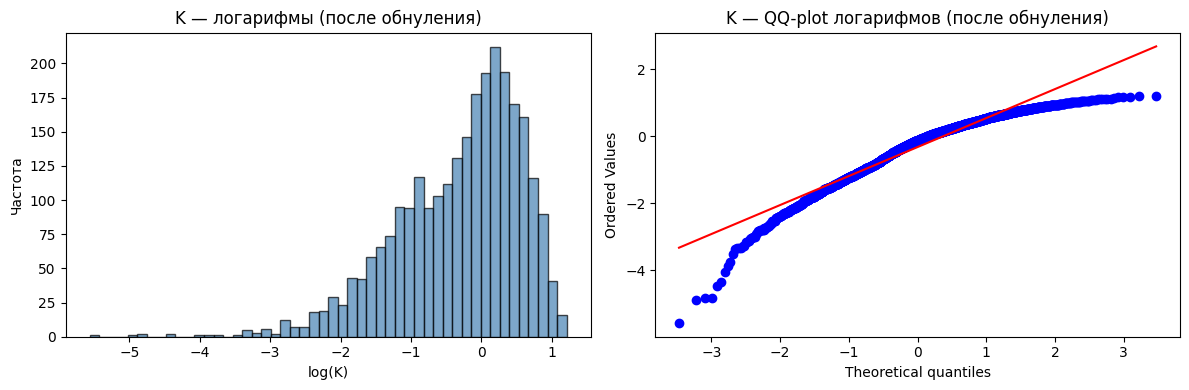

K: skew(log) = -1.01, kurt(log) = 1.50


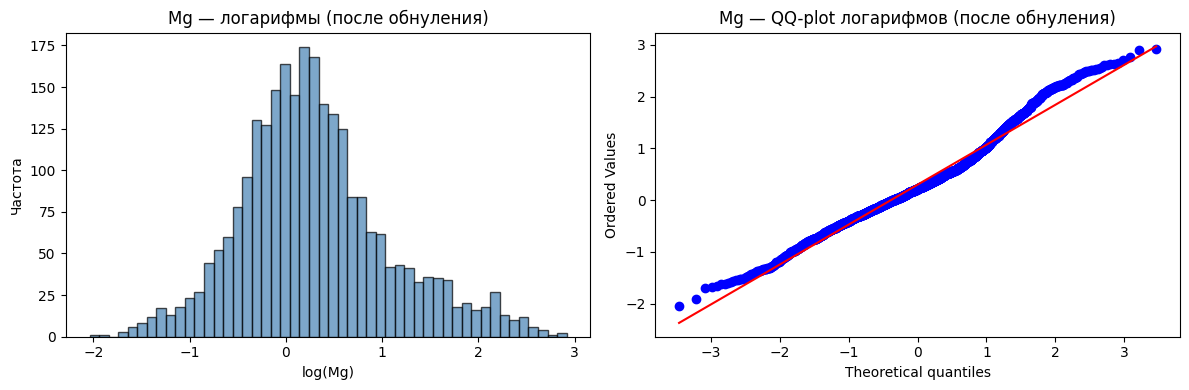

Mg: skew(log) = 0.52, kurt(log) = 0.46


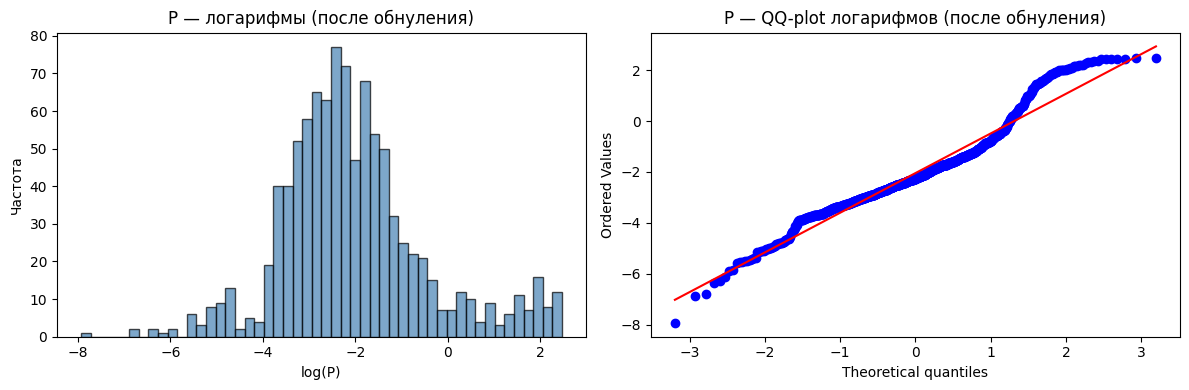

P: skew(log) = 0.59, kurt(log) = 1.07


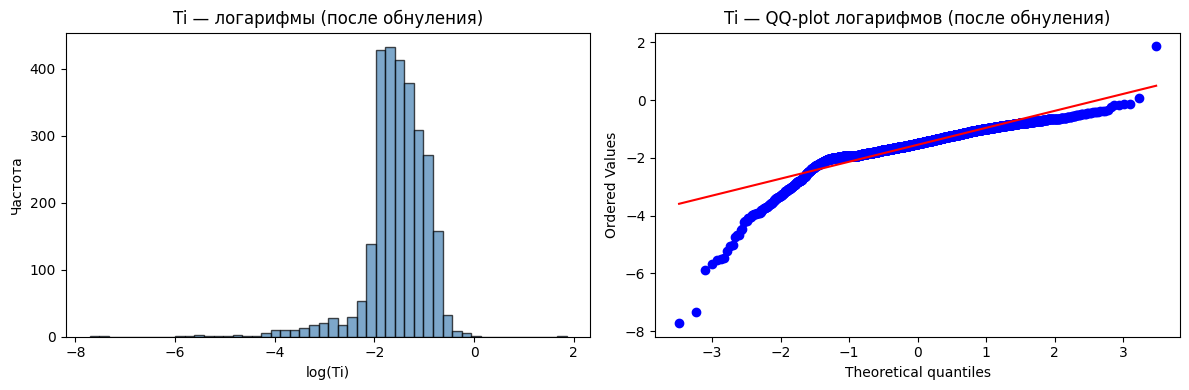

Ti: skew(log) = -2.17, kurt(log) = 11.71


In [55]:
# Элементы, для которых обнуляли артефакты
elements_check = ['K', 'Mg', 'P', 'Ti']

for element in elements_check:
    if element not in df_filtered.columns:
        continue
    
    df_elem = df_filtered[element].dropna()
    df_nonzero = df_elem[df_elem > 0]
    
    if len(df_nonzero) < 10:
        print(f"{element}: слишком мало ненулевых значений")
        continue
    
    log_values = np.log(df_nonzero)
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    # Гистограмма логарифмов
    axes[0].hist(log_values, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
    axes[0].set_xlabel(f'log({element})')
    axes[0].set_ylabel('Частота')
    axes[0].set_title(f'{element} — логарифмы (после обнуления)')
    
    # QQ-plot логарифмов
    stats.probplot(log_values, dist="norm", plot=axes[1])
    axes[1].set_title(f'{element} — QQ-plot логарифмов (после обнуления)')
    
    plt.tight_layout()
    plt.savefig(f'after_clean_{element}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    
    # Параметры скошенности
    from scipy.stats import skew, kurtosis
    print(f"{element}: skew(log) = {skew(log_values):.2f}, kurt(log) = {kurtosis(log_values):.2f}")

**Доля нулей после обнуления артефактов**

In [56]:
# Подсчёт нулей и процентов по каждому элементу
zero_counts = df_filtered[elements].isnull().sum() + (df_filtered[elements] == 0).sum()
total = len(df_filtered)

zero_table = pd.DataFrame({
    'Элемент': zero_counts.index,
    'Нулей': zero_counts.values,
    'Доля нулей, %': (zero_counts.values / total * 100).round(2)
}).sort_values('Доля нулей, %', ascending=False).reset_index(drop=True)

print("Таблица нулевых значений по элементам:")
print(zero_table.to_string(index=False))

# Общее количество
total_zeros = zero_counts.sum()
total_values = total * len(elements)
print(f"\nОбщее количество нулевых значений: {total_zeros}")
print(f"Процент нулевых значений (все элементы): {total_zeros / total_values * 100:.2f}%")

Таблица нулевых значений по элементам:
Элемент  Нулей  Доля нулей, %
      P   2037          67.29
     Mo    591          19.52
     Mn    449          14.83
     Ca    440          14.54
     Mg    409          13.51
     Cu    348          11.50
     Se    346          11.43
      K    340          11.23
     Rb    257           8.49
     Ti    223           7.37
     Ni    215           7.10
     Fe    183           6.05
     Sr     93           3.07
     Zr     26           0.86
     Zn     23           0.76
      S      5           0.17
     Si      3           0.10
     Al      0           0.00

Общее количество нулевых значений: 5988
Процент нулевых значений (все элементы): 10.99%


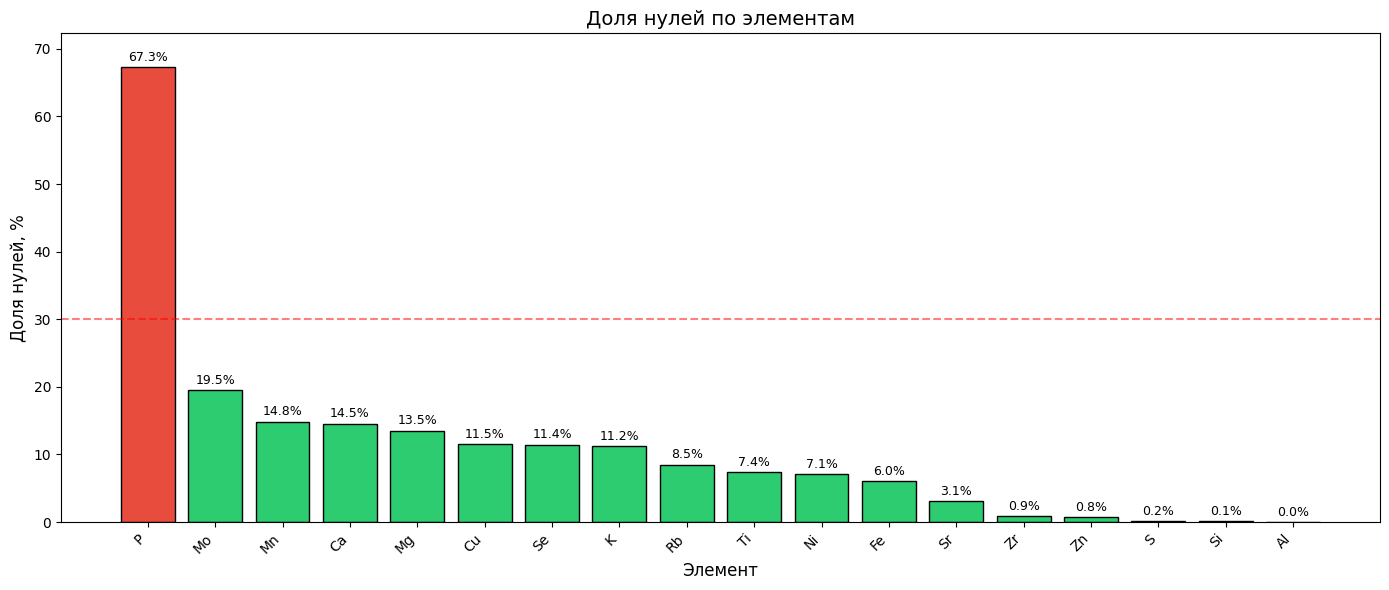

In [57]:
# График: доля нулей по элементам
fig, ax = plt.subplots(figsize=(14, 6))

# Цвета по группам 
def get_color(pct):
    if pct < 30:
        return '#2ecc71'  
    else:
        return '#e74c3c'  

colors = [get_color(p) for p in zero_table['Доля нулей, %']]

bars = ax.bar(zero_table['Элемент'], zero_table['Доля нулей, %'], color=colors, edgecolor='black')

# Подписи значений над столбцами
for bar, pct in zip(bars, zero_table['Доля нулей, %']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{pct:.1f}%', ha='center', va='bottom', fontsize=9)

# Пороговые линии
ax.axhline(y=30, color='red', linestyle='--', alpha=0.5)

ax.set_xlabel('Элемент', fontsize=12)
ax.set_ylabel('Доля нулей, %', fontsize=12)
ax.set_title('Доля нулей по элементам', fontsize=14)

ax.set_ylim(0, max(zero_table['Доля нулей, %']) + 5)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Подсчет значений ниже LOD**

In [58]:
# LOD для каждого элемента
lod = {
    'Mg': 0.1848625,
    'Al': 0.0927875,
    'Si': 0.2984125,
    'Ca': 0.077025,
    'S': 0.3082,
    'K': 0.0271375,
    'Ti': 0.003,
    'Mn': 0.0024375,
    'Fe': 0.09165,
    'Ni': 0.0032625,
    'Cu': 0.00335,
    'Zn': 0.0022375,
    'Rb': 0.0003125,
    'Sr': 0.0013125,
    'Zr': 0.00065,
    'Mo': 0.00105,
    'P': 0.016325,
    'Se': 0.0002375
}


In [59]:
below_lod = pd.Series({e: ((df_filtered[e] > 0) & (df_filtered[e] < lod[e])).sum() for e in elements})

print("Количество значений ниже LOD (без нулей):")
print(below_lod)

print(f"\nВсего ниже LOD: {below_lod.sum()}")
print(f"Процент: {(below_lod.sum() / (len(df_filtered) * len(elements))) * 100:.2f}%")


Количество значений ниже LOD (без нулей):
Mg      3
Al      3
Si      2
P      55
S      20
K       9
Ca    127
Ti      3
Mn     72
Fe     44
Ni    490
Cu     98
Zn      0
Se    494
Rb      0
Sr      0
Zr     34
Mo    246
dtype: int64

Всего ниже LOD: 1700
Процент: 3.12%


**Поиск минимальных значений по элементам**

In [60]:
min_values = pd.Series({e: df_filtered.loc[df_filtered[e] > 0, e].min() for e in elements})

print("Минимальные значения (исключая 0):")
print(min_values)

Минимальные значения (исключая 0):
Mg    0.130200
Al    0.013244
Si    0.026589
P     0.000358
S     0.075067
K     0.003822
Ca    0.000877
Ti    0.000446
Mn    0.001031
Fe    0.002603
Ni    0.000112
Cu    0.002408
Zn    0.002500
Se    0.000005
Rb    0.000489
Sr    0.005073
Zr    0.000092
Mo    0.000663
dtype: float64


**Минимальное или LOD, если он меньше**

In [61]:
result = pd.Series({e: min(min_values[e], lod[e]) for e in elements})

print("Минимум (меньше из минимального значения и LOD):")
print(result)

Минимум (меньше из минимального значения и LOD):
Mg    0.130200
Al    0.013244
Si    0.026589
P     0.000358
S     0.075067
K     0.003822
Ca    0.000877
Ti    0.000446
Mn    0.001031
Fe    0.002603
Ni    0.000112
Cu    0.002408
Zn    0.002237
Se    0.000005
Rb    0.000313
Sr    0.001313
Zr    0.000092
Mo    0.000663
dtype: float64


**Создание доп признака P_above_LOD**

**Замена нулей на LOD/корень из 2**

In [62]:
lod_values = {
    'Mg': 0.130200,
    'Al': 0.013244,
    'Si': 0.026589,
    'P':  0.000358,
    'S':  0.075067,
    'K':  0.003822,
    'Ca': 0.000877,
    'Ti': 0.000446,
    'Mn': 0.001031,
    'Fe': 0.002603,
    'Ni': 0.000112,
    'Cu': 0.002408,
    'Zn': 0.002237,
    'Se': 0.000005,
    'Rb': 0.000313,
    'Sr': 0.001313,
    'Zr': 0.000092,
    'Mo': 0.000663,
}

# Бинарный признак P_above_LOD
df_filtered['P_above_LOD'] = (df_filtered['P'] > 0).astype(int)

print("Распределение P_above_LOD:")
print(df_filtered['P_above_LOD'].value_counts())
print(f"Доля проб с P выше LOD: {df_filtered['P_above_LOD'].mean():.2%}")

# Замена нулей на LOD/√2
for el in elements:
    if el not in df_filtered.columns:
        continue
    replacement = lod_values[el] / np.sqrt(2)
    n_replaced = (df_filtered[el] == 0).sum()
    df_filtered[el] = df_filtered[el].replace(0, replacement)
    print(f"{el}: заменено {n_replaced} нулей на LOD/√2 = {replacement:.8f}")

# Проверка
print("\nНулей после замены (должно быть 0):")
print((df_filtered[elements] == 0).sum())

Распределение P_above_LOD:
P_above_LOD
0    2037
1     990
Name: count, dtype: int64
Доля проб с P выше LOD: 32.71%
Mg: заменено 409 нулей на LOD/√2 = 0.09206530
Al: заменено 0 нулей на LOD/√2 = 0.00936492
Si: заменено 3 нулей на LOD/√2 = 0.01880126
P: заменено 2037 нулей на LOD/√2 = 0.00025314
S: заменено 5 нулей на LOD/√2 = 0.05308038
K: заменено 340 нулей на LOD/√2 = 0.00270256
Ca: заменено 440 нулей на LOD/√2 = 0.00062013
Ti: заменено 223 нулей на LOD/√2 = 0.00031537
Mn: заменено 449 нулей на LOD/√2 = 0.00072903
Fe: заменено 183 нулей на LOD/√2 = 0.00184060
Ni: заменено 215 нулей на LOD/√2 = 0.00007920
Cu: заменено 348 нулей на LOD/√2 = 0.00170271
Zn: заменено 23 нулей на LOD/√2 = 0.00158180
Se: заменено 346 нулей на LOD/√2 = 0.00000354
Rb: заменено 257 нулей на LOD/√2 = 0.00022132
Sr: заменено 93 нулей на LOD/√2 = 0.00092843
Zr: заменено 26 нулей на LOD/√2 = 0.00006505
Mo: заменено 591 нулей на LOD/√2 = 0.00046881

Нулей после замены (должно быть 0):
Mg    0
Al    0
Si    0
P     

**Оценка межскважинной вариативности**

In [63]:
# Подготовка данных
elements_pca = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 
                'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

# Извлекаем матрицу концентраций (пробы × 18 элементов)
X_raw = df_filtered[elements_pca].values
wells = df_filtered['Well'].values
n_samples, D = X_raw.shape
print(f"Матрица: {n_samples} проб, {D} элементов")

Матрица: 3027 проб, 18 элементов


In [64]:
X_raw = df_filtered[elements_pca].values

print("Форма:", X_raw.shape) 
print("Нулей:", (X_raw == 0).sum())
print("NaN:", np.isnan(X_raw).sum())
print("Отрицательных:", (X_raw < 0).sum())
print("Min по элементам:")
for i, el in enumerate(elements_pca):
    print(f"  {el}: {X_raw[:, i].min():.10f}")

Форма: (3027, 18)
Нулей: 0
NaN: 0
Отрицательных: 2
Min по элементам:
  Mg: 0.0920653029
  Al: 0.0132442700
  Si: 0.0188012622
  P: 0.0002531442
  S: 0.0530803847
  K: 0.0027025621
  Ca: 0.0006201326
  Ti: 0.0003153696
  Mn: 0.0007290271
  Fe: 0.0018405990
  Ni: -0.0001104600
  Cu: 0.0017027131
  Zn: 0.0015817979
  Se: 0.0000035355
  Rb: 0.0002213244
  Sr: 0.0009284312
  Zr: 0.0000650538
  Mo: 0.0004688118


**Замена отрицательных значений Ni**

In [65]:
lod_ni = 0.000112 
df_filtered.loc[df_filtered['Ni'] < 0, 'Ni'] = lod_ni / np.sqrt(2)

ILR-матрица: (3027, 16)
Объяснённая дисперсия (PC1, PC2): 94.75%
Scores CLR: (3027, 17), Loadings CLR: (17, 16)


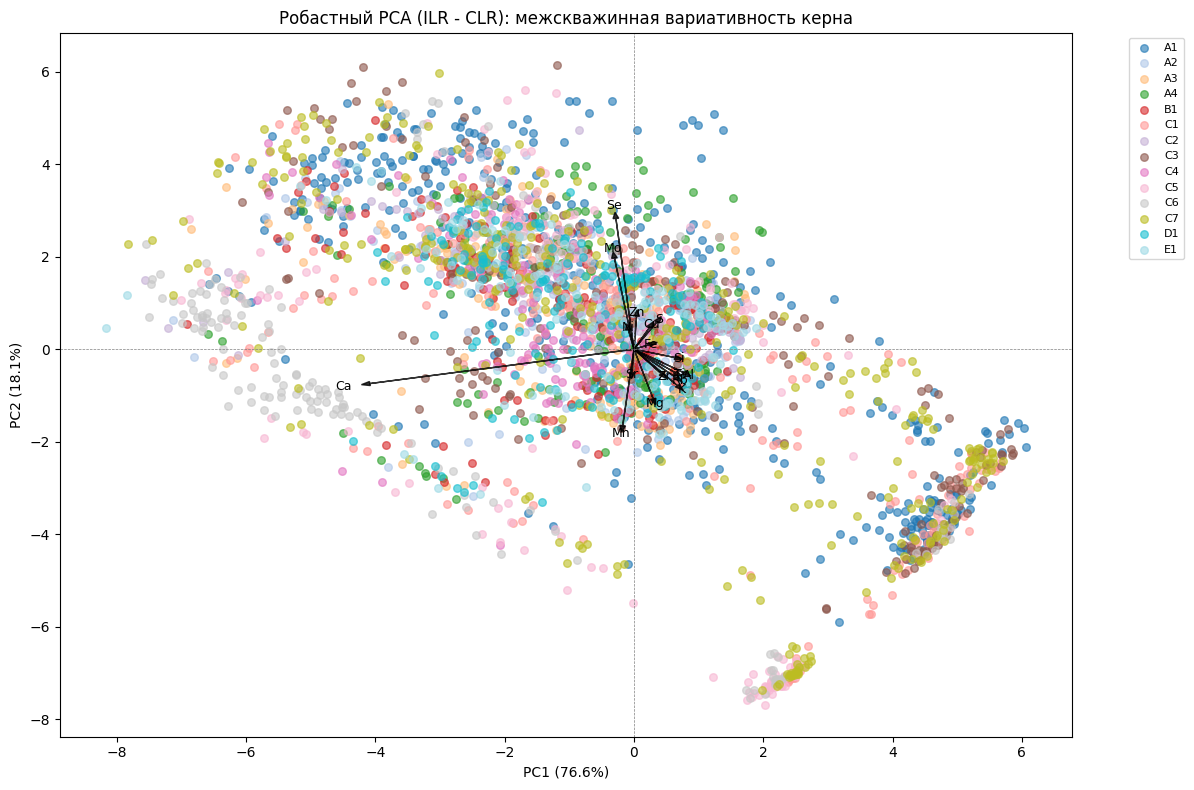

In [68]:
# Isometric Log-Ratio
def ilr_transformation(X):
    """
    ILR-преобразование
    Возвращает матрицу Z размерности (n_samples, D-1).
    """
    n, D = X.shape
    log_X = np.log(X)
    
    # Строим ортонормированный базис V (D × (D-1))
    # Формула (4) из статьи Filzmoser et al. (2009)
    V = np.zeros((D, D - 1))
    for i in range(1, D):  # i = 1, ..., D-1
        # v_i = sqrt(i/(i+1)) * (1/i, ..., 1/i, -1, 0, ..., 0)
        v = np.zeros(D)
        v[:i] = 1.0 / i
        v[i] = -1.0
        V[:, i - 1] = np.sqrt(i / (i + 1)) * v
    
    # Z = log(X) @ V  (размерность n × (D-1))
    Z = log_X @ V
    return Z, V

Z, V = ilr_transformation(X_raw)
print(f"ILR-матрица: {Z.shape}")

# РОБАСТНЫЙ PCA (через MCD-оценку ковариации)
# Оцениваем робастную ковариацию и центр
mcd = MinCovDet(random_state=42, support_fraction=0.75)
mcd.fit(Z)

# Центр и ковариационная матрица в ILR-пространстве
T_z = mcd.location_
C_z = mcd.covariance_

# Собственное разложение
U_z, S_z, Vt_z = svd(C_z)
# Сортируем по убыванию собственных значений (svd уже сортирует)
eigenvalues = S_z ** 2
explained_variance = eigenvalues / eigenvalues.sum()

print(f"Объяснённая дисперсия (PC1, PC2): {explained_variance[:2].sum():.2%}")

# Scores в ILR-пространстве (центрируем и проецируем)
Z_centered = Z - T_z
scores_ilr = Z_centered @ U_z  # (n × (D-1))

# Loadings в ILR-пространстве
loadings_ilr = U_z


# ОБРАТНОЕ ПРЕОБРАЗОВАНИЕ В CLR-ПРОСТРАНСТВО
# Формула (12) из статьи: Y* = Z* @ V^T
scores_clr = scores_ilr @ V.T  # (n × D)

# Формула (13): G_Y = V @ G_Z
loadings_clr = V @ loadings_ilr  # (D × (D-1))

print(f"Scores CLR: {scores_clr.shape}, Loadings CLR: {loadings_clr.shape}")

# Biplot с раскраской по скважинам)
fig, ax = plt.subplots(figsize=(12, 8))

# Уникальные скважины и цвета
unique_wells = np.unique(wells)
colors = plt.cm.tab20(np.linspace(0, 1, len(unique_wells)))

# Scatter plot: scores по PC1 и PC2, цвет = скважина
for i, well in enumerate(unique_wells):
    mask = wells == well
    ax.scatter(scores_clr[mask, 0], scores_clr[mask, 1], 
               label=well, alpha=0.6, s=30, color=colors[i])

# Стрелки loadings (вклад элементов)
scale_factor = 0.5 * np.max(np.abs(scores_clr[:, :2])) / np.max(np.abs(loadings_clr[:, :2]))
for j, element in enumerate(elements_pca):
    ax.arrow(0, 0, 
             loadings_clr[j, 0] * scale_factor, 
             loadings_clr[j, 1] * scale_factor,
             head_width=0.02 * scale_factor, head_length=0.03 * scale_factor,
             fc='black', ec='black', alpha=0.8)
    ax.text(loadings_clr[j, 0] * scale_factor * 1.1, 
            loadings_clr[j, 1] * scale_factor * 1.1,
            element, fontsize=9, ha='center', va='center')

ax.axhline(0, color='grey', linestyle='--', linewidth=0.5)
ax.axvline(0, color='grey', linestyle='--', linewidth=0.5)
ax.set_xlabel(f'PC1 ({explained_variance[0]:.1%})')
ax.set_ylabel(f'PC2 ({explained_variance[1]:.1%})')
ax.set_title('Робастный PCA (ILR - CLR): межскважинная вариативность керна')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.savefig('robust_pca_interwell.png', dpi=300, bbox_inches='tight')
plt.show()

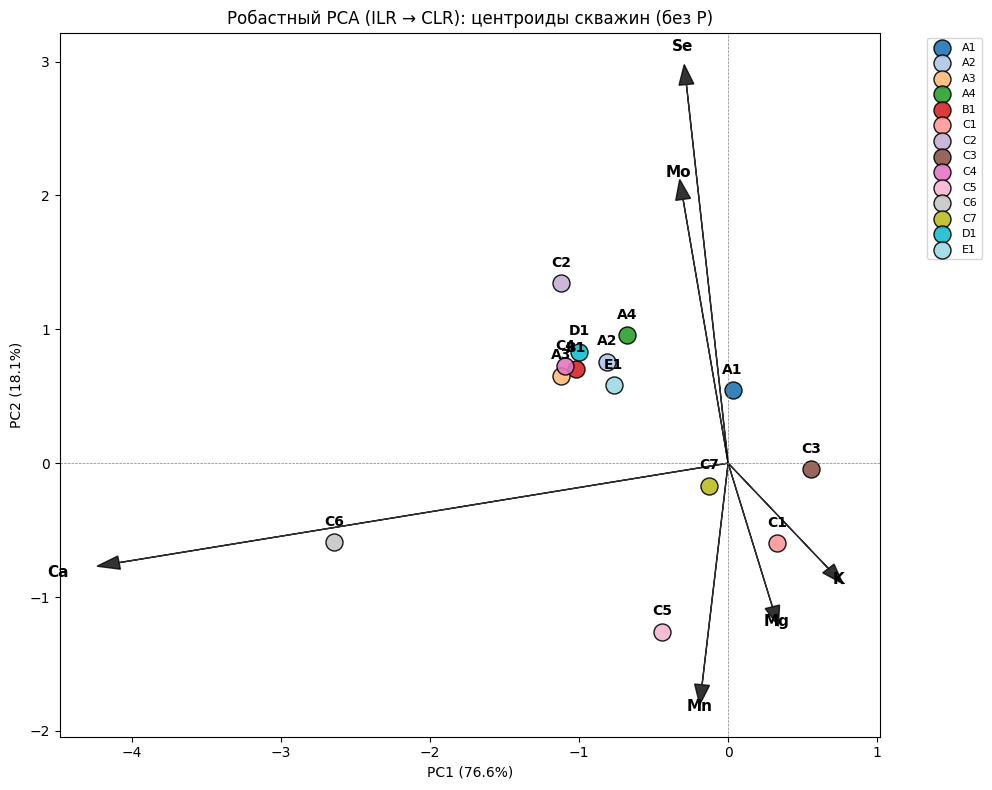

In [67]:
# Подготовка данных (БЕЗ P)
elements_pca = ['Mg', 'Al', 'Si', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 
                'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

X_raw = df_filtered[elements_pca].values.copy()
wells = df_filtered['Well'].values

# Замена отрицательных/нулей (если есть)
X_raw = np.where(X_raw <= 0, 1e-10, X_raw)

# ILR
def ilr_transformation(X):
    n, D = X.shape
    log_X = np.log(X)
    V = np.zeros((D, D - 1))
    for i in range(1, D):
        v = np.zeros(D)
        v[:i] = 1.0 / i
        v[i] = -1.0
        V[:, i - 1] = np.sqrt(i / (i + 1)) * v
    Z = log_X @ V
    return Z, V

Z, V = ilr_transformation(X_raw)

# Робастный PCA
mcd = MinCovDet(random_state=42, support_fraction=0.75)
mcd.fit(Z)
T_z = mcd.location_
C_z = mcd.covariance_
U_z, S_z, Vt_z = svd(C_z)
eigenvalues = S_z ** 2
explained_variance = eigenvalues / eigenvalues.sum()

Z_centered = Z - T_z
scores_ilr = Z_centered @ U_z
loadings_ilr = U_z

# Обратное преобразование
scores_clr = scores_ilr @ V.T
loadings_clr = V @ loadings_ilr

# Визуализация: центроиды скважин + топ-6 стрелок
fig, ax = plt.subplots(figsize=(10, 8))

# Центроиды скважин
unique_wells = np.unique(wells)
colors = plt.cm.tab20(np.linspace(0, 1, len(unique_wells)))

for i, well in enumerate(unique_wells):
    mask = wells == well
    # Центроид (среднее по скважине)
    centroid = scores_clr[mask, :2].mean(axis=0)
    ax.scatter(centroid[0], centroid[1], s=150, color=colors[i], 
               edgecolor='black', label=well, alpha=0.9)
    # Подпись скважины
    ax.text(centroid[0], centroid[1] + 0.1, well, fontsize=10, 
            ha='center', va='bottom', fontweight='bold')

# Топ-6 элементов по loadings
loadings_df = pd.DataFrame(loadings_clr[:, :2], index=elements_pca, columns=['PC1', 'PC2'])
# Топ по сумме абсолютных нагрузок
top6 = loadings_df.abs().sum(axis=1).nlargest(6).index.tolist()

scale_factor = 0.5 * np.max(np.abs(scores_clr[:, :2])) / np.max(np.abs(loadings_clr[:, :2]))
for element in top6:
    x = loadings_df.loc[element, 'PC1'] * scale_factor
    y = loadings_df.loc[element, 'PC2'] * scale_factor
    ax.arrow(0, 0, x, y, head_width=0.1, head_length=0.15, 
             fc='black', ec='black', alpha=0.8)
    ax.text(x * 1.1, y * 1.1, element, fontsize=11, 
            ha='center', va='center', fontweight='bold')

ax.axhline(0, color='grey', linestyle='--', linewidth=0.5)
ax.axvline(0, color='grey', linestyle='--', linewidth=0.5)
ax.set_xlabel(f'PC1 ({explained_variance[0]:.1%})')
ax.set_ylabel(f'PC2 ({explained_variance[1]:.1%})')
ax.set_title('Робастный PCA (ILR → CLR): центроиды скважин (без P)')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.savefig('robust_pca_interwell_centroids.png', dpi=300, bbox_inches='tight')
plt.show()

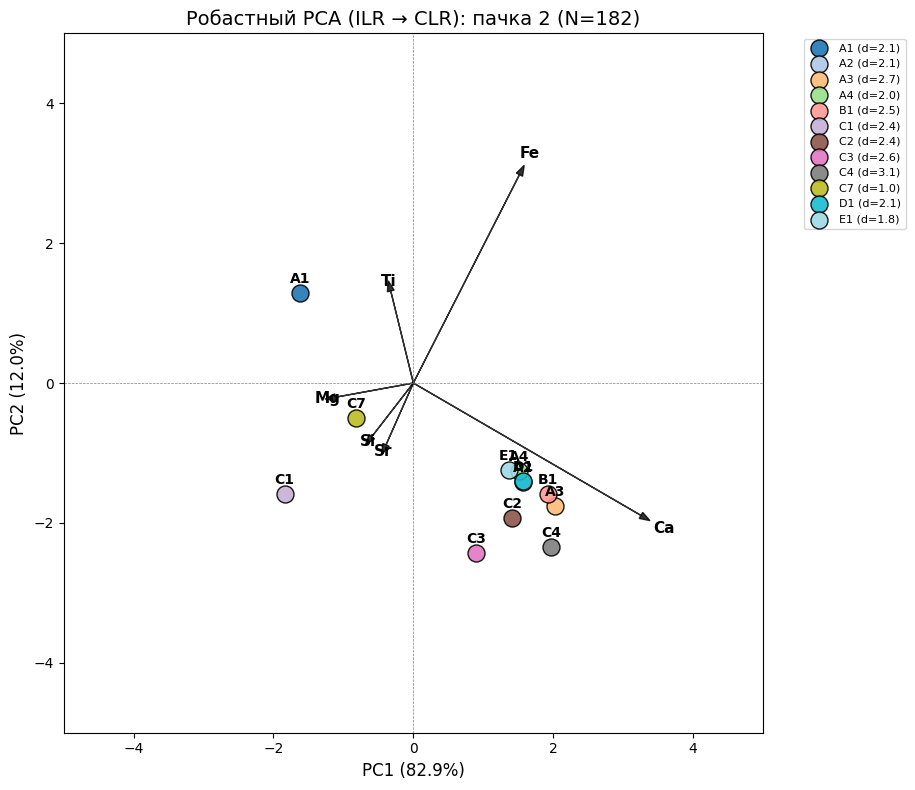

Пачка 2: N=182, среднее расстояние до нуля=2.23, среднее попарное=1.93, площадь эллипса=20.24


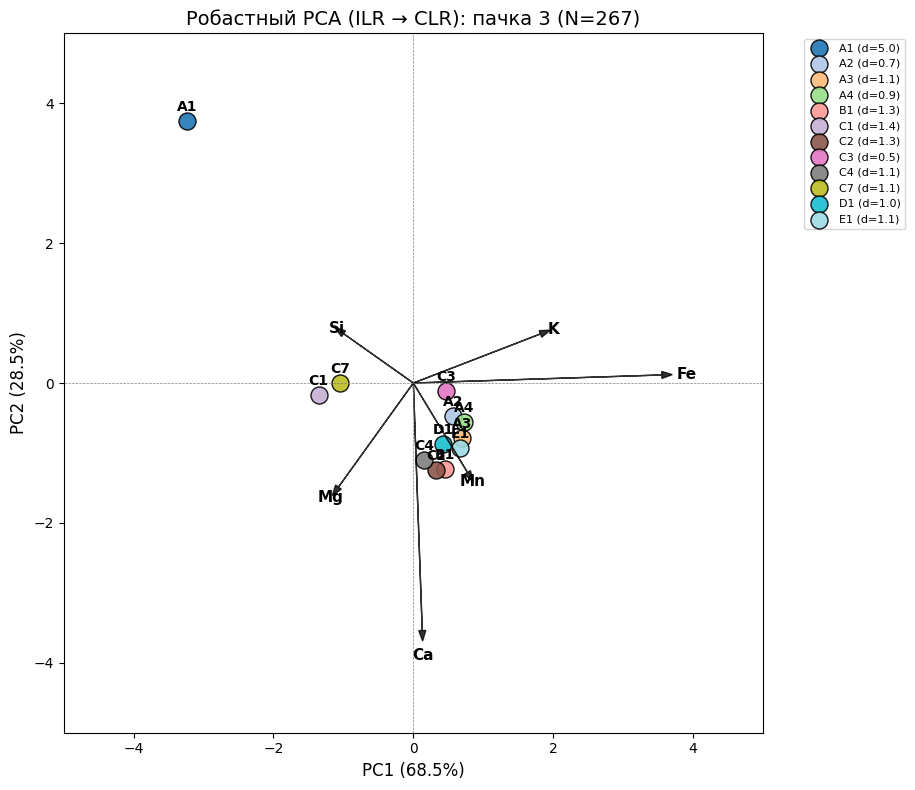

Пачка 3: N=267, среднее расстояние до нуля=1.36, среднее попарное=1.75, площадь эллипса=14.44


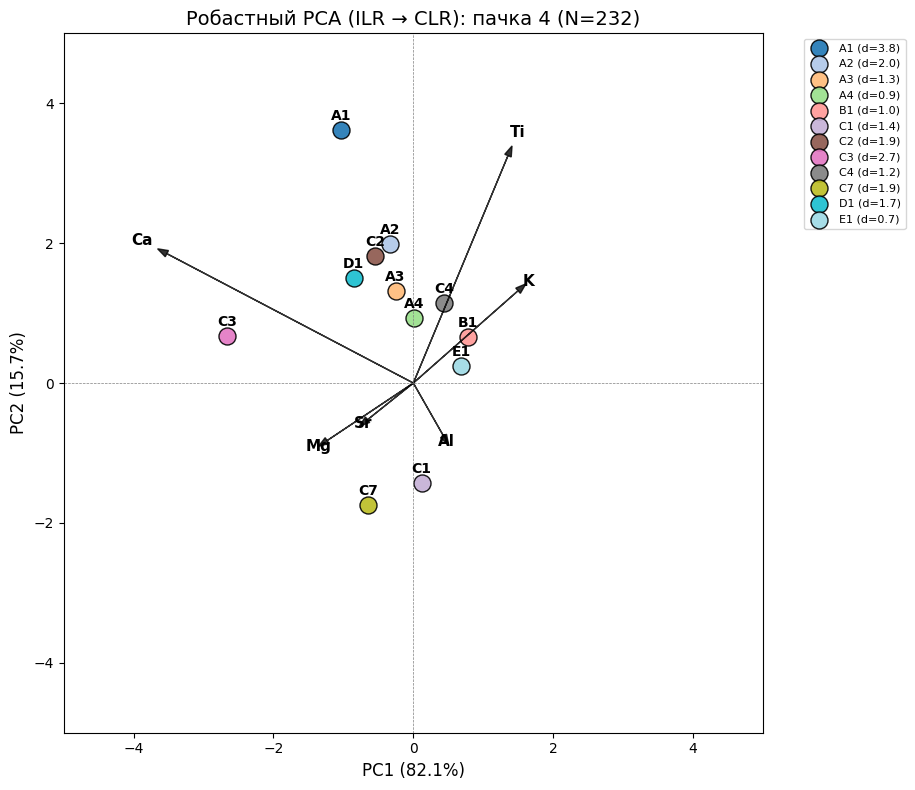

Пачка 4: N=232, среднее расстояние до нуля=1.72, среднее попарное=2.13, площадь эллипса=24.82


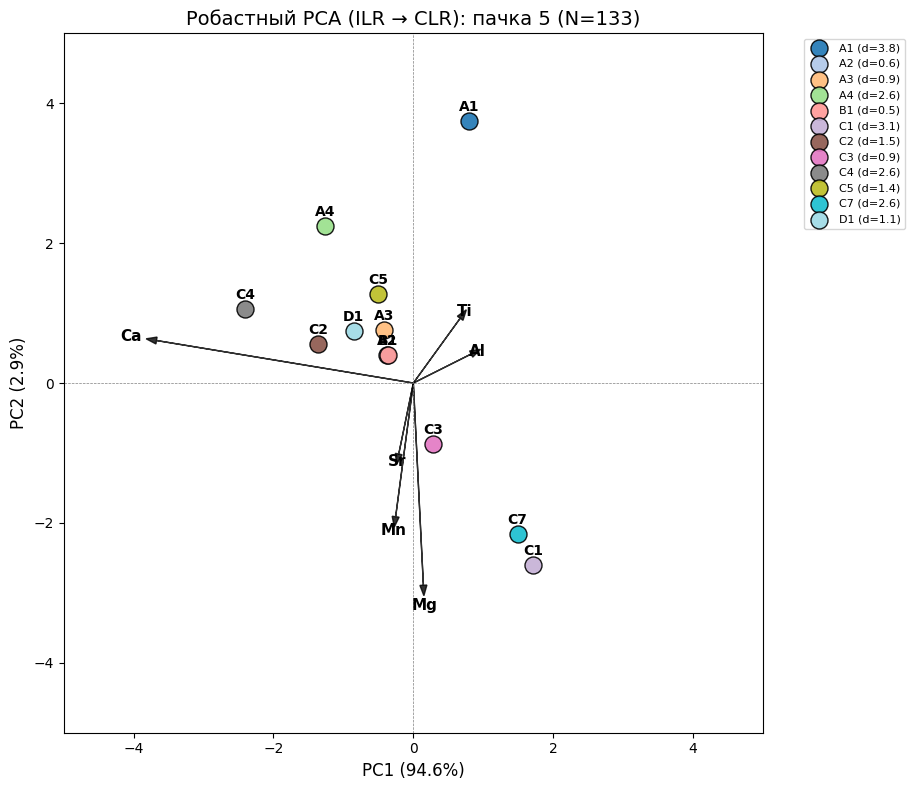

Пачка 5: N=133, среднее расстояние до нуля=1.80, среднее попарное=2.53, площадь эллипса=33.81


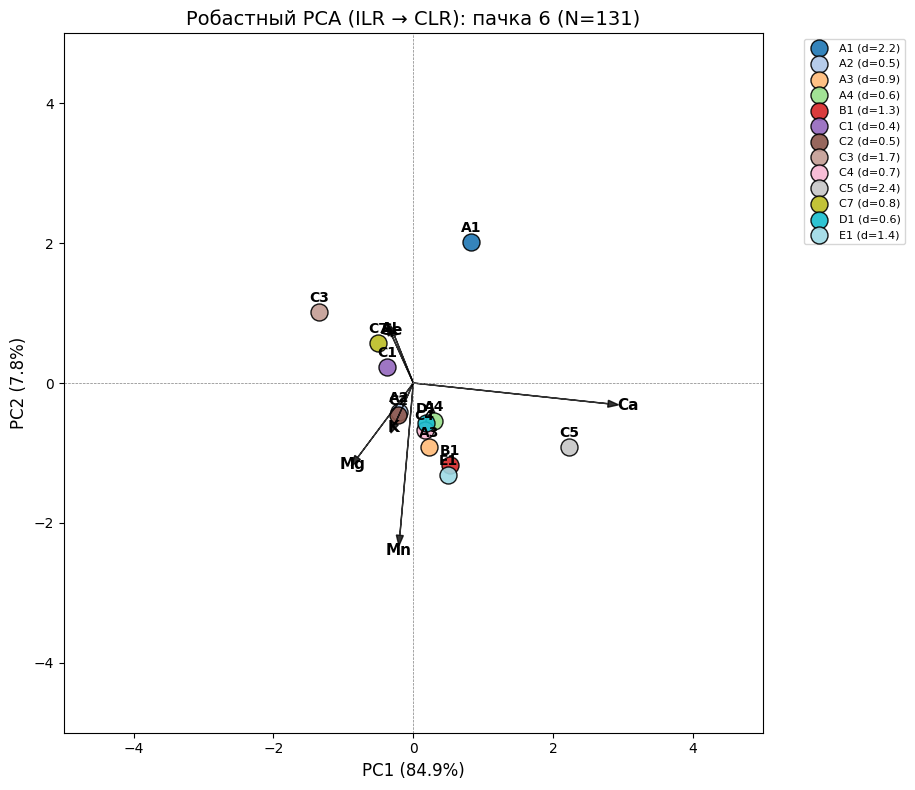

Пачка 6: N=131, среднее расстояние до нуля=1.08, среднее попарное=1.50, площадь эллипса=14.04


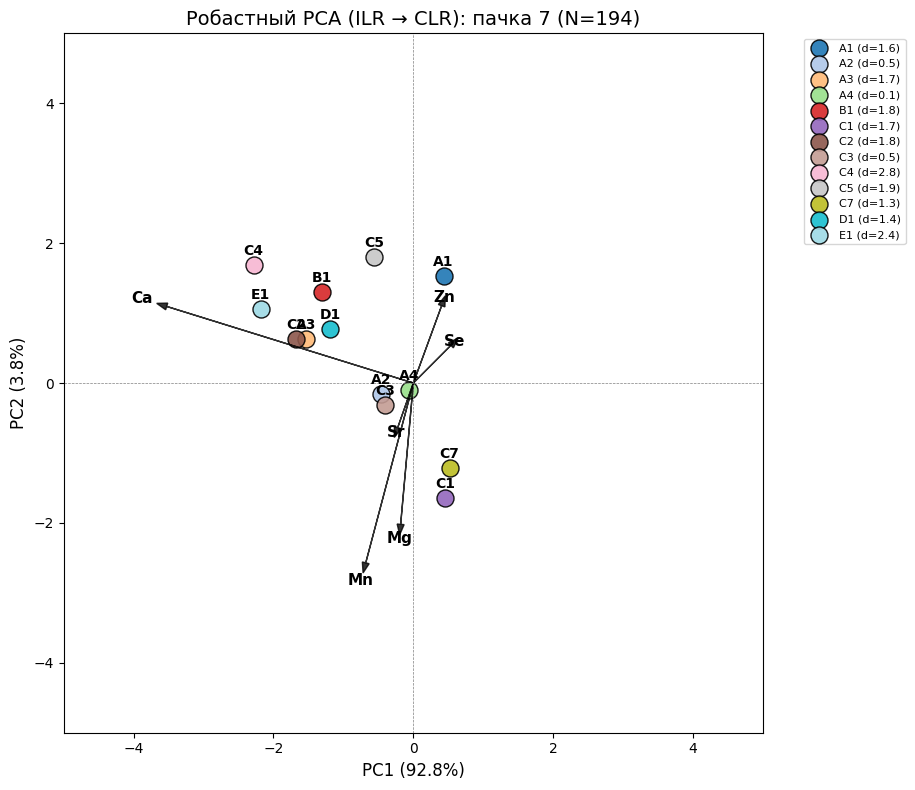

Пачка 7: N=194, среднее расстояние до нуля=1.51, среднее попарное=1.83, площадь эллипса=16.13


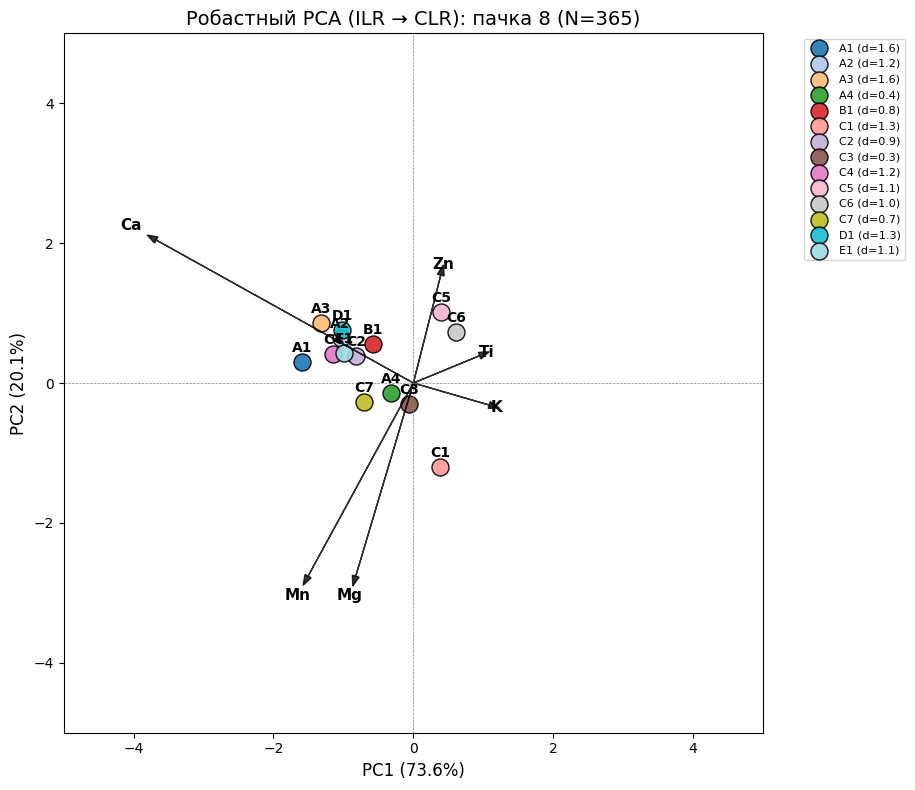

Пачка 8: N=365, среднее расстояние до нуля=1.03, среднее попарное=1.12, площадь эллипса=7.38


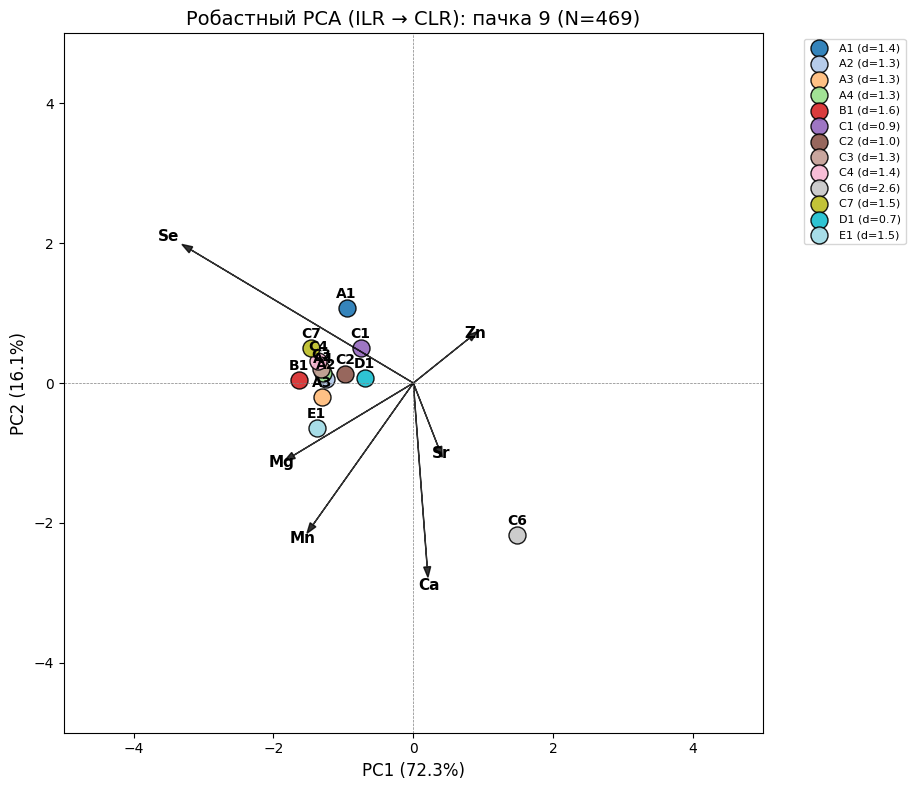

Пачка 9: N=469, среднее расстояние до нуля=1.38, среднее попарное=1.09, площадь эллипса=7.65


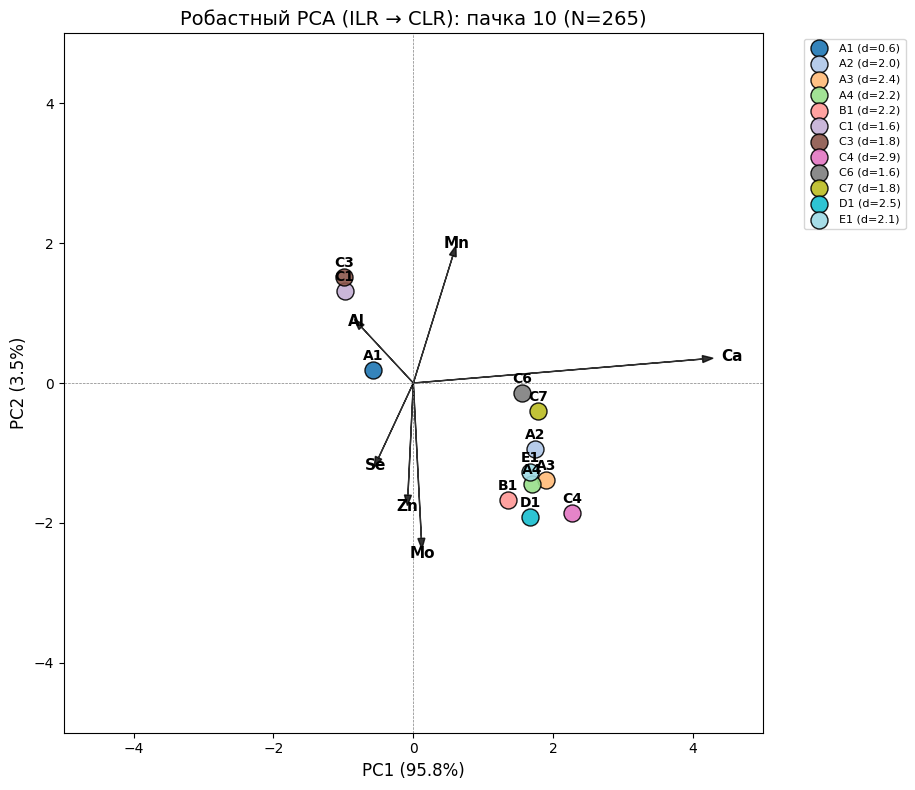

Пачка 10: N=265, среднее расстояние до нуля=1.98, среднее попарное=1.92, площадь эллипса=12.63


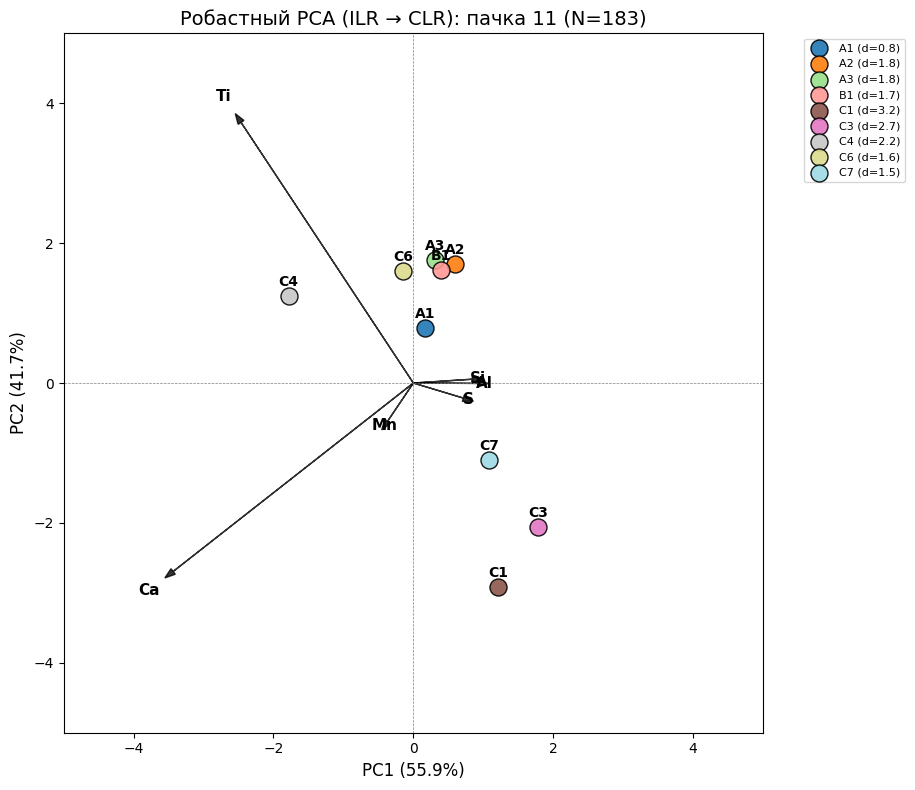

Пачка 11: N=183, среднее расстояние до нуля=1.92, среднее попарное=2.50, площадь эллипса=26.44
СВОДНАЯ ТАБЛИЦА: РАССТОЯНИЯ И КУЧНОСТЬ (PC1-PC2)
 Пачка  N проб  N скважин  Среднее расстояние до нуля  Среднее попарное расстояние  Макс. попарное расстояние  Среднее расстояние до центра облака  Площадь эллипса 95%
     5     133         12                        1.80                         2.53                       6.42                                 1.59                33.81
    11     183          9                        1.92                         2.50                       5.13                                 1.80                26.44
     4     232         12                        1.72                         2.13                       5.38                                 1.42                24.82
     2     182         12                        2.23                         1.93                       5.11                                 1.39                20.24
    10     265  

In [69]:
from scipy.spatial.distance import pdist
from scipy.stats import chi2

# Подготовка
elements_pca = ['Mg', 'Al', 'Si', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 
                'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

# Функция ILR
def ilr_transformation(X):
    n, D = X.shape
    log_X = np.log(X)
    V = np.zeros((D, D - 1))
    for i in range(1, D):
        v = np.zeros(D)
        v[:i] = 1.0 / i
        v[i] = -1.0
        V[:, i - 1] = np.sqrt(i / (i + 1)) * v
    Z = log_X @ V
    return Z, V

# Пачки (классы)
classes = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

# Накопитель для сводной таблицы
distance_results = []

for cls in classes:
    df_cls = df_filtered[df_filtered['Strat'] == cls].copy()
    
    if len(df_cls) < 50:
        print(f"Пачка {cls}: слишком мало проб ({len(df_cls)}), пропускаем.")
        continue
    
    counts = df_cls['Well'].value_counts()
    wells_ok = counts[counts >= 3].index.tolist()
    
    if len(wells_ok) < 2:
        print(f"Пачка {cls}: недостаточно скважин с ≥3 пробами, пропускаем.")
        continue
    
    df_cls = df_cls[df_cls['Well'].isin(wells_ok)]
    
    X_raw = df_cls[elements_pca].values.copy()
    wells = df_cls['Well'].values
    
    X_raw = np.where(X_raw <= 0, 1e-10, X_raw)
    
    Z, V = ilr_transformation(X_raw)
    
    # Робастный PCA
    mcd = MinCovDet(random_state=42, support_fraction=0.75)
    mcd.fit(Z)
    T_z = mcd.location_
    C_z = mcd.covariance_
    U_z, S_z, Vt_z = svd(C_z)
    eigenvalues = S_z ** 2
    explained_variance = eigenvalues / eigenvalues.sum()
    
    Z_centered = Z - T_z
    scores_ilr = Z_centered @ U_z
    loadings_ilr = U_z
    
    scores_clr = scores_ilr @ V.T
    loadings_clr = V @ loadings_ilr
    
    # Центроиды скважин
    unique_wells = np.unique(wells)
    centroids = []
    for well in unique_wells:
        mask = wells == well
        centroid = scores_clr[mask, :2].mean(axis=0)
        centroids.append(centroid)
    centroids = np.array(centroids)
    
    # Расстояние до нуля
    distances_to_zero = np.linalg.norm(centroids, axis=1)
    
    # Среднее попарное расстояние между скважинами
    pairwise = pdist(centroids, metric='euclidean')
    mean_pairwise = pairwise.mean()
    max_pairwise = pairwise.max() if len(pairwise) > 0 else 0
    
    # Среднее расстояние до центра облака (не до нуля)
    cloud_center = centroids.mean(axis=0)
    dist_to_cloud = np.linalg.norm(centroids - cloud_center, axis=1)
    mean_to_cloud = dist_to_cloud.mean()
    
    # Площадь эллипса 95% 
    if len(centroids) >= 3:
        cov = np.cov(centroids.T)
        area_95 = np.pi * chi2.ppf(0.95, df=2) * np.sqrt(np.linalg.det(cov))
    else:
        area_95 = np.nan
    
    # Сохраняем
    distance_results.append({
        'Пачка': cls,
        'N проб': len(df_cls),
        'N скважин': len(unique_wells),
        'Среднее расстояние до нуля': round(distances_to_zero.mean(), 2),
        'Среднее попарное расстояние': round(mean_pairwise, 2),
        'Макс. попарное расстояние': round(max_pairwise, 2),
        'Среднее расстояние до центра облака': round(mean_to_cloud, 2),
        'Площадь эллипса 95%': round(area_95, 2) if not np.isnan(area_95) else None,
    })
    
    # Визуализация
    fig, ax = plt.subplots(figsize=(10, 8))
    colors = plt.cm.tab20(np.linspace(0, 1, len(unique_wells)))
    
    for i, well in enumerate(unique_wells):
        mask = wells == well
        centroid = scores_clr[mask, :2].mean(axis=0)
        dist = np.linalg.norm(centroid)
        ax.scatter(centroid[0], centroid[1], s=150, color=colors[i],
                   edgecolor='black', label=f'{well} (d={dist:.1f})', alpha=0.9)
        ax.text(centroid[0], centroid[1] + 0.1, well, fontsize=10,
                ha='center', va='bottom', fontweight='bold')
    
    loadings_df = pd.DataFrame(loadings_clr[:, :2], index=elements_pca, columns=['PC1', 'PC2'])
    top6 = loadings_df.abs().sum(axis=1).nlargest(6).index.tolist()
    
    scale_factor = 0.5 * np.max(np.abs(scores_clr[:, :2])) / np.max(np.abs(loadings_clr[:, :2]))
    for element in top6:
        x = loadings_df.loc[element, 'PC1'] * scale_factor
        y = loadings_df.loc[element, 'PC2'] * scale_factor
        ax.arrow(0, 0, x, y, head_width=0.1, head_length=0.15,
                 fc='black', ec='black', alpha=0.8)
        ax.text(x * 1.1, y * 1.1, element, fontsize=11,
                ha='center', va='center', fontweight='bold')
    
    ax.axhline(0, color='grey', linestyle='--', linewidth=0.5)
    ax.axvline(0, color='grey', linestyle='--', linewidth=0.5)
    
    max_val = 5.0
    ax.set_xlim(-max_val, max_val)
    ax.set_ylim(-max_val, max_val)
    ax.set_aspect('equal', adjustable='box')
    
    ax.set_xlabel(f'PC1 ({explained_variance[0]:.1%})', fontsize=12)
    ax.set_ylabel(f'PC2 ({explained_variance[1]:.1%})', fontsize=12)
    ax.set_title(f'Робастный PCA (ILR → CLR): пачка {cls} (N={len(df_cls)})', fontsize=14)
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
    plt.tight_layout()
    plt.savefig(f'robust_pca_class_{cls}.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()
    
    print(f"Пачка {cls}: N={len(df_cls)}, "
          f"среднее расстояние до нуля={distances_to_zero.mean():.2f}, "
          f"среднее попарное={mean_pairwise:.2f}, "
          f"площадь эллипса={area_95:.2f}")

# Сводная таблица 
print("СВОДНАЯ ТАБЛИЦА: РАССТОЯНИЯ И КУЧНОСТЬ (PC1-PC2)")
distance_df = pd.DataFrame(distance_results).sort_values('Среднее попарное расстояние', ascending=False)
print(distance_df.to_string(index=False))

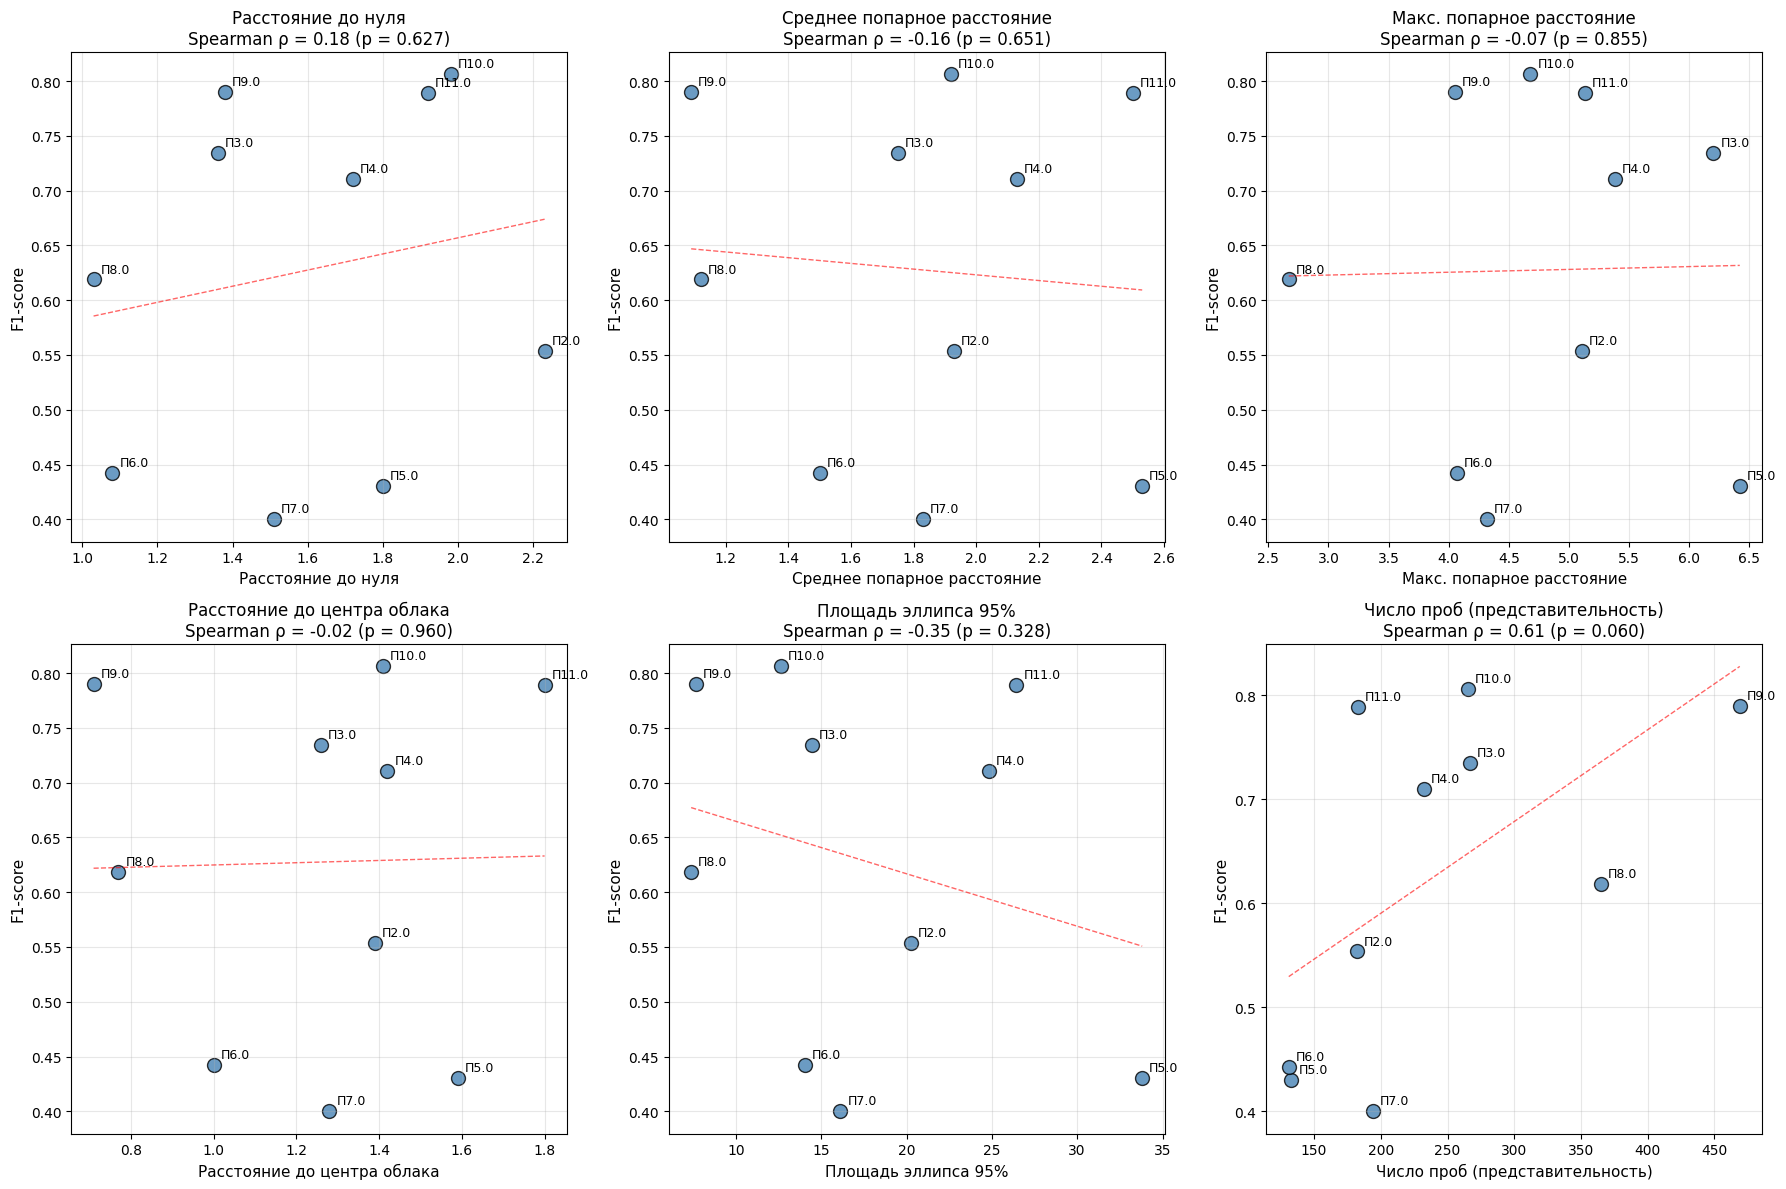

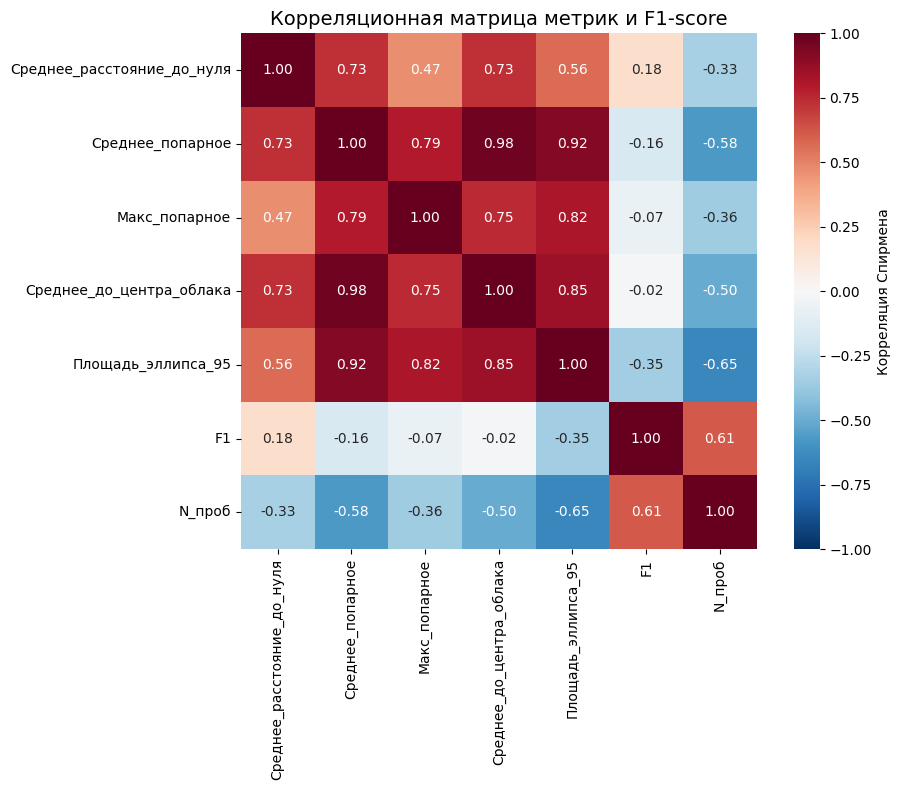

КОРРЕЛЯЦИЯ МЕТРИК С F1-SCORE (Спирмен)
Среднее_расстояние_до_нуля              : ρ = +0.176, p = 0.627
Среднее_попарное                        : ρ = -0.164, p = 0.651
Макс_попарное                           : ρ = -0.067, p = 0.855
Среднее_до_центра_облака                : ρ = -0.018, p = 0.960
Площадь_эллипса_95                      : ρ = -0.345, p = 0.328
N_проб                                  : ρ = +0.612, p = 0.060


In [70]:
# Данные (из вашей таблицы + F1)
data = {
    'Пачка': [5, 11, 4, 2, 10, 7, 3, 6, 8, 9],
    'N_проб': [133, 183, 232, 182, 265, 194, 267, 131, 365, 469],
    'N_скважин': [12, 9, 12, 12, 12, 13, 12, 13, 14, 13],
    'Среднее_расстояние_до_нуля': [1.80, 1.92, 1.72, 2.23, 1.98, 1.51, 1.36, 1.08, 1.03, 1.38],
    'Среднее_попарное': [2.53, 2.50, 2.13, 1.93, 1.92, 1.83, 1.75, 1.50, 1.12, 1.09],
    'Макс_попарное': [6.42, 5.13, 5.38, 5.11, 4.68, 4.32, 6.20, 4.07, 2.67, 4.05],
    'Среднее_до_центра_облака': [1.59, 1.80, 1.42, 1.39, 1.41, 1.28, 1.26, 1.00, 0.77, 0.71],
    'Площадь_эллипса_95': [33.81, 26.44, 24.82, 20.24, 12.63, 16.13, 14.44, 14.04, 7.38, 7.65],
    'F1': [0.4305, 0.7890, 0.7104, 0.5537, 0.8061, 0.4000, 0.7345, 0.4427, 0.6189, 0.7899]
}

df_metrics = pd.DataFrame(data)

# Корреляционная матрица (Спирмен — устойчив к выбросам)
metrics_cols = ['Среднее_расстояние_до_нуля', 'Среднее_попарное', 'Макс_попарное', 
                'Среднее_до_центра_облака', 'Площадь_эллипса_95', 'F1', 'N_проб']

corr_matrix = df_metrics[metrics_cols].corr(method='spearman')

# Scatter-plot матрица (связи между метриками и F1)
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

metrics_to_plot = [
    ('Среднее_расстояние_до_нуля', 'Расстояние до нуля'),
    ('Среднее_попарное', 'Среднее попарное расстояние'),
    ('Макс_попарное', 'Макс. попарное расстояние'),
    ('Среднее_до_центра_облака', 'Расстояние до центра облака'),
    ('Площадь_эллипса_95', 'Площадь эллипса 95%'),
    ('N_проб', 'Число проб (представительность)')
]

for i, (col, label) in enumerate(metrics_to_plot):
    ax = axes[i]
    
    # Scatter
    ax.scatter(df_metrics[col], df_metrics['F1'], s=100, c='steelblue', edgecolor='black', alpha=0.8)
    
    # Подписи пачек
    for j, row in df_metrics.iterrows():
        ax.annotate(f"П{row['Пачка']}", (row[col], row['F1']), 
                    textcoords="offset points", xytext=(5, 5), fontsize=9)
    
    # Линия тренда (если есть корреляция)
    z = np.polyfit(df_metrics[col], df_metrics['F1'], 1)
    p = np.poly1d(z)
    x_line = np.linspace(df_metrics[col].min(), df_metrics[col].max(), 100)
    ax.plot(x_line, p(x_line), 'r--', alpha=0.6, linewidth=1)
    
    # Корреляция Спирмена
    rho, p_val = spearmanr(df_metrics[col], df_metrics['F1'])
    ax.set_xlabel(label, fontsize=11)
    ax.set_ylabel('F1-score', fontsize=11)
    ax.set_title(f'{label}\nSpearman ρ = {rho:.2f} (p = {p_val:.3f})', fontsize=12)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('metrics_vs_f1_scatter.png', dpi=300, bbox_inches='tight')
plt.show()

# Корреляционная матрица (heatmap)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0, 
            vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={'label': 'Корреляция Спирмена'})
ax.set_title('Корреляционная матрица метрик и F1-score', fontsize=14)
plt.tight_layout()
plt.savefig('metrics_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

# Сводная таблица корреляций с F1
print("КОРРЕЛЯЦИЯ МЕТРИК С F1-SCORE (Спирмен)")
for col in metrics_cols:
    if col == 'F1':
        continue
    rho, p_val = spearmanr(df_metrics[col], df_metrics['F1'])
    print(f"{col:40s}: ρ = {rho:+.3f}, p = {p_val:.3f}")

**Керн+Шлам**

Отсутствуют в керне: []
Отсутствуют в шламе: []
Керн: 3027 проб, Шлам: 8644 проб, Всего: 11671


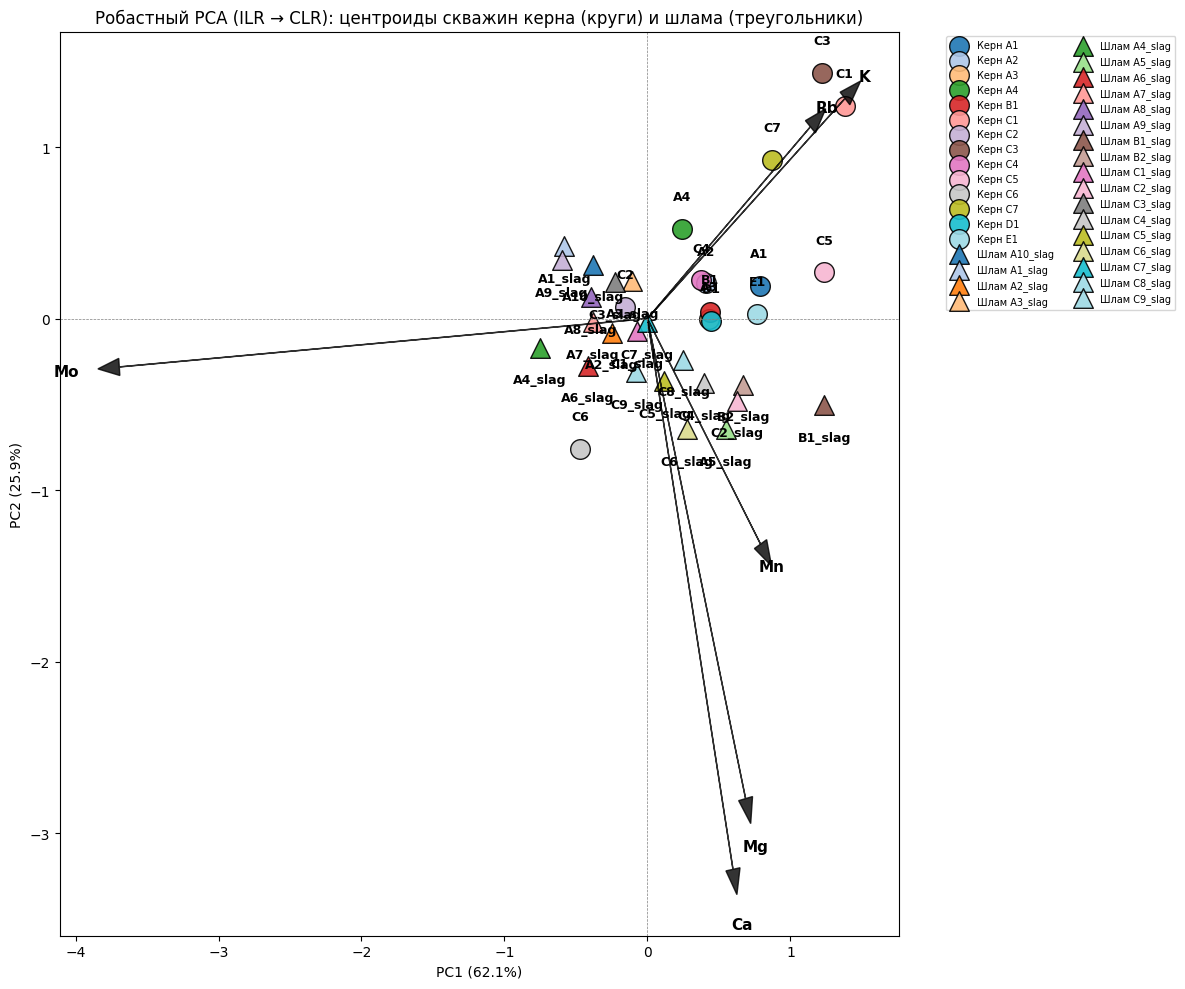

In [71]:
# Загрузка данных
df_slag = pd.read_csv('Data/data_slag_ALLratios_16_10.csv')

# Список элементов (без P)
elements_pca = ['Mg', 'Al', 'Si', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 
                'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

# Проверка колонок в шламе
missing_kern = [el for el in elements_pca if el not in df_filtered.columns]
missing_slag = [el for el in elements_pca if el not in df_slag.columns]
print(f"Отсутствуют в керне: {missing_kern}")
print(f"Отсутствуют в шламе: {missing_slag}")

# Подготовка данных
# Керн (уже с заменой нулей)
X_kern = df_filtered[elements_pca].values.copy()
wells_kern = df_filtered['Well'].values

# Шлам 
X_slag = df_slag[elements_pca].values.copy()
wells_slag = df_slag['Well'].values

# Объединяем керн и шлам
X_all = np.vstack([X_kern, X_slag])
wells_all = np.concatenate([wells_kern, wells_slag])
source = np.array(['kern'] * len(X_kern) + ['slag'] * len(X_slag))

print(f"Керн: {len(X_kern)} проб, Шлам: {len(X_slag)} проб, Всего: {len(X_all)}")

# ILR
def ilr_transformation(X):
    n, D = X.shape
    log_X = np.log(X)
    V = np.zeros((D, D - 1))
    for i in range(1, D):
        v = np.zeros(D)
        v[:i] = 1.0 / i
        v[i] = -1.0
        V[:, i - 1] = np.sqrt(i / (i + 1)) * v
    Z = log_X @ V
    return Z, V

Z, V = ilr_transformation(X_all)

# Робастный PCA
mcd = MinCovDet(random_state=42, support_fraction=0.75)
mcd.fit(Z)
T_z = mcd.location_
C_z = mcd.covariance_
U_z, S_z, Vt_z = svd(C_z)
eigenvalues = S_z ** 2
explained_variance = eigenvalues / eigenvalues.sum()

Z_centered = Z - T_z
scores_ilr = Z_centered @ U_z
loadings_ilr = U_z

# Обратное преобразование в CLR
scores_clr = scores_ilr @ V.T
loadings_clr = V @ loadings_ilr

# Визуализация: центроиды скважин керна и шлама
fig, ax = plt.subplots(figsize=(12, 10))

# Керн — круги
unique_wells_kern = np.unique(wells_kern)
colors_kern = plt.cm.tab20(np.linspace(0, 1, len(unique_wells_kern)))

for i, well in enumerate(unique_wells_kern):
    mask = (wells_all == well) & (source == 'kern')
    if mask.sum() == 0:
        continue
    centroid = scores_clr[mask, :2].mean(axis=0)
    ax.scatter(centroid[0], centroid[1], s=200, color=colors_kern[i], 
               edgecolor='black', marker='o', label=f'Керн {well}', alpha=0.9)
    ax.text(centroid[0], centroid[1] + 0.15, well, fontsize=9,
            ha='center', va='bottom', fontweight='bold')

# Шлам — треугольники
unique_wells_slag = np.unique(wells_slag)
colors_slag = plt.cm.tab20(np.linspace(0, 1, len(unique_wells_slag)))

for i, well in enumerate(unique_wells_slag):
    mask = (wells_all == well) & (source == 'slag')
    if mask.sum() == 0:
        continue
    centroid = scores_clr[mask, :2].mean(axis=0)
    ax.scatter(centroid[0], centroid[1], s=200, color=colors_slag[i],
               edgecolor='black', marker='^', label=f'Шлам {well}', alpha=0.9)
    ax.text(centroid[0], centroid[1] - 0.15, well, fontsize=9,
            ha='center', va='top', fontweight='bold')

# Топ-6 элементов
loadings_df = pd.DataFrame(loadings_clr[:, :2], index=elements_pca, columns=['PC1', 'PC2'])
top6 = loadings_df.abs().sum(axis=1).nlargest(6).index.tolist()

scale_factor = 0.5 * np.max(np.abs(scores_clr[:, :2])) / np.max(np.abs(loadings_clr[:, :2]))
for element in top6:
    x = loadings_df.loc[element, 'PC1'] * scale_factor
    y = loadings_df.loc[element, 'PC2'] * scale_factor
    ax.arrow(0, 0, x, y, head_width=0.1, head_length=0.15,
             fc='black', ec='black', alpha=0.8)
    ax.text(x * 1.1, y * 1.1, element, fontsize=11,
            ha='center', va='center', fontweight='bold')

ax.axhline(0, color='grey', linestyle='--', linewidth=0.5)
ax.axvline(0, color='grey', linestyle='--', linewidth=0.5)
ax.set_xlabel(f'PC1 ({explained_variance[0]:.1%})')
ax.set_ylabel(f'PC2 ({explained_variance[1]:.1%})')
ax.set_title('Робастный PCA (ILR → CLR): центроиды скважин керна (круги) и шлама (треугольники)')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig('robust_pca_kern_vs_slag_centroids.png', dpi=300, bbox_inches='tight')
plt.show()

In [72]:
df_slag.describe()

,Sample,Depth,Stratigraphy,Mg,Al,Si,P,S,K,Ca,...,rΔ_(Al+K+Ti)/Si,rΔ_(Al+K+Ti)/S,rΔ_(Ti+Rb+Zr)/S,rΔ_S/Ti,rΔ_Ni/Al,rΔ_Zn/Al,rΔ_Se/Si,rΔ_(Ca+Mg)/Al,rΔ_Se/Ti,rΔ_(10*Rb+Ti+10*Zr)/Se*1000
count,8644.000000,8644.000000,8644.000000,8644.000000,8644.000000,8644.000000,8644.000000,8644.000000,8644.000000,8644.000000,...,8623.000000,8623.000000,8623.000000,8623.000000,8623.000000,8623.000000,8623.000000,8623.000000,8623.000000,8623.000000
mean,213.931513,3829.184799,4.431282,0.703852,3.817018,27.556483,0.281361,3.039574,0.974770,4.040890,...,0.995827,1.006274,1.009015,1.025411,1.031464,1.034093,1.079886,1.159703,1.046417,1.095084
std,122.743139,498.290889,2.414575,0.631362,1.783757,5.406676,0.308627,2.012670,0.395423,4.019549,...,0.144903,0.254644,0.265553,0.315241,0.354020,0.360060,0.795236,1.231407,0.542418,1.124670
min,1.000000,2800.000000,2.000000,0.109351,0.383441,5.231311,0.000075,0.119139,0.000067,0.344116,...,0.385467,0.110027,0.127320,0.167075,0.162647,0.110706,0.027032,0.042011,0.026818,0.022101
25%,109.000000,3408.000000,3.000000,0.286170,2.665799,24.015926,0.080166,1.942657,0.678670,1.489355,...,0.935235,0.884870,0.874797,0.880460,0.866521,0.871025,0.860044,0.798218,0.857882,0.863438
50%,214.000000,3833.000000,3.000000,0.560521,3.597447,28.971673,0.176755,2.415293,0.992280,2.596335,...,0.990325,0.984685,0.983517,0.991409,0.991656,0.982487,0.988141,0.972025,0.985799,0.983058
75%,318.000000,4244.000000,4.000000,0.944443,4.437036,31.587396,0.423553,3.448836,1.272166,5.167879,...,1.043588,1.093502,1.103282,1.116482,1.132092,1.117963,1.134909,1.173424,1.136427,1.114124
max,517.000000,4893.000000,11.000000,5.846600,11.612252,38.548209,2.978289,19.818291,2.221930,33.278364,...,3.182236,5.691206,5.612400,7.095887,15.514519,11.483285,24.241447,36.973413,15.557554,34.402804


**Создание новых признаков по соотношениям элементов**

In [73]:
# Карбонатность
df_filtered['(Ca+Mg)/(Al+Si)'] = (df_filtered['Ca'] + df_filtered['Mg']) / (df_filtered['Al'] + df_filtered['Si'])
df_filtered['Sr/Ca'] = df_filtered['Sr'] / df_filtered['Ca']
df_filtered['Mn/Ca'] = df_filtered['Mn'] / df_filtered['Ca']

# Терригенное вещество
df_filtered['(Al+K)/(Ca+Mg+Si)'] = (df_filtered['Al'] + df_filtered['K']) / (df_filtered['Ca'] + df_filtered['Mg'] + df_filtered['Si'])
df_filtered['Zr/Al'] = df_filtered['Zr'] / df_filtered['Al']
df_filtered['Zr/Si'] = df_filtered['Zr'] / df_filtered['Si']
df_filtered['K/Al'] = df_filtered['K'] / df_filtered['Al']
df_filtered['Ti/(Zr+Ti)'] = df_filtered['Ti'] / (df_filtered['Zr'] + df_filtered['Ti'])

# Морская биопродуктивность и кислородный режим
df_filtered['Si/Al'] = df_filtered['Si'] / df_filtered['Al']
df_filtered['P/Al'] = df_filtered['P'] / df_filtered['Al']
df_filtered['Ni/Fe'] = df_filtered['Ni'] / df_filtered['Fe']
df_filtered['Ni/(Si+Ca+Mg)'] = df_filtered['Ni'] / (df_filtered['Si'] + df_filtered['Ca'] + df_filtered['Mg'])
df_filtered['S/(Rb+Zr)'] = df_filtered['S'] / (df_filtered['Rb'] + df_filtered['Zr'])
df_filtered['Mo/Al'] = df_filtered['Mo'] / df_filtered['Al']
df_filtered['Mo/(Mn+Mo)'] = df_filtered['Mo'] / (df_filtered['Mn'] + df_filtered['Mo'])
df_filtered['Mn/Al'] = df_filtered['Mn'] / df_filtered['Al']

# Сульфидность
df_filtered['Fe/S'] = df_filtered['Fe'] / df_filtered['S']
df_filtered['Ni/S'] = df_filtered['Ni'] / df_filtered['S']

# Железистость
df_filtered['Fe/(Ca+Mg+Al)'] = df_filtered['Fe'] / (df_filtered['Ca'] + df_filtered['Mg'] + df_filtered['Al'])
df_filtered['Ti/(Si+Ca+Mg)'] = df_filtered['Ti'] / (df_filtered['Si'] + df_filtered['Ca'] + df_filtered['Mg'])
df_filtered['Fe/(Mn+Fe)'] = df_filtered['Fe'] / (df_filtered['Mn'] + df_filtered['Fe'])

# Прочие
df_filtered['(Al+K+Ti)/Si'] = (df_filtered['Al'] + df_filtered['K'] + df_filtered['Ti']) / df_filtered['Si']
df_filtered['(Al+K+Ti)/S'] = (df_filtered['Al'] + df_filtered['K'] + df_filtered['Ti']) / df_filtered['S']
df_filtered['(Ti+Rb+Zr)/S'] = (df_filtered['Ti'] + df_filtered['Rb'] + df_filtered['Zr']) / df_filtered['S']
df_filtered['S/Ti'] = df_filtered['S'] / df_filtered['Ti']
df_filtered['Ni/Al'] = df_filtered['Ni'] / df_filtered['Al']
df_filtered['Zn/Al'] = df_filtered['Zn'] / df_filtered['Al']
df_filtered['Se/Si'] = df_filtered['Se'] / df_filtered['Si']
df_filtered['(Ca+Mg)/Al'] = (df_filtered['Ca'] + df_filtered['Mg']) / df_filtered['Al']
df_filtered['Se/Ti'] = df_filtered['Se'] / df_filtered['Ti']
df_filtered['(10*Rb+Ti+10*Zr)/Se*1000'] = (10 * df_filtered['Rb'] + df_filtered['Ti'] + 10 * df_filtered['Zr']) / df_filtered['Se'] * 1000

In [74]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3027 entries, 0 to 3036
Data columns (total 55 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Mg                        3027 non-null   float64
 1   Al                        3027 non-null   float64
 2   Si                        3027 non-null   float64
 3   P                         3027 non-null   float64
 4   S                         3027 non-null   float64
 5   K                         3027 non-null   float64
 6   Ca                        3027 non-null   float64
 7   Ti                        3027 non-null   float64
 8   Mn                        3027 non-null   float64
 9   Fe                        3027 non-null   float64
 10  Ni                        3027 non-null   float64
 11  Cu                        3027 non-null   float64
 12  Zn                        3027 non-null   float64
 13  Se                        3027 non-null   float64
 14  Rb           

In [21]:
df_filtered.to_csv('Data/data_kern_ratios.csv', index=False)

In [38]:
df_filtered.to_csv('Data/data_kern_ratios_06_10.csv', index=False)

In [75]:
df_filtered.to_csv('Data/data_kern_ratios_04_11.csv', index=False)